In [205]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "Sooyong"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
from preprocessing import *

print(module_test())
print("✅ 준비 완료")

/content/team3-ping-analytics
✅ 모듈 설치 완료
✅ 준비 완료


In [206]:
# 구글 드라이브 연결

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [207]:
# 라이브러리 불러오기

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.lines import Line2D
import seaborn as sns
import json

# 전처리


## accounts_attendance 테이블


In [208]:
# 데이터 불러오기

accounts_attendance = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/accounts_attendance.csv')


### 구조 파악


In [209]:
accounts_attendance.shape


(349637, 3)

- 349,637 rows
- 3 columns


In [210]:
accounts_attendance.head()


,id,attendance_date_list,user_id
0,1,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1446852
1,2,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1359398
2,3,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1501542
3,4,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1507767
4,5,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1287453


In [211]:
accounts_attendance.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349637 entries, 0 to 349636
Data columns (total 3 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   id                    349637 non-null  int64 
 1   attendance_date_list  349637 non-null  object
 2   user_id               349637 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 8.0+ MB


- id: 데이터 적재 순서
- attendance_date_list: 출석일 리스트
  - 리스트 형태로 되어있어 풀어서 봐야할 듯
  - 데이터형이 object임 -> 날짜형으로 변경하자
- user_id: 유저 고유의 식별자


In [212]:
accounts_attendance.isna().sum()


,0
id,0
attendance_date_list,0
user_id,0


In [213]:
accounts_attendance.duplicated().sum()


np.int64(0)

- 결측치, 중복값 없음


#### attendance_date_list


In [214]:
# 1. 필요한 컬럼만 복사

attendance_base = accounts_attendance[
    ["id", "user_id", "attendance_date_list"]
].copy()

attendance_base = attendance_base.rename(
    columns={"id": "attendance_record_id"}
)

print(attendance_base.shape)
display(attendance_base.head())


(349637, 3)


,attendance_record_id,user_id,attendance_date_list
0,1,1446852,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20..."
1,2,1359398,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20..."
2,3,1501542,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20..."
3,4,1507767,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20..."
4,5,1287453,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20..."


In [215]:
# 2-1. 문자열을 실제 리스트로 변환

def parse_attendance_date_list(value):
    # 이미 리스트인 경우
    if isinstance(value, list):
        return value, False

    # 결측 또는 빈 문자열
    if pd.isna(value) or str(value).strip() == "":
        return [], False

    try:
        parsed = json.loads(value)

        # 리스트가 아닌 값이 들어온 경우
        if not isinstance(parsed, list):
            return [], True

        return parsed, False

    except (json.JSONDecodeError, TypeError):
        return [], True

parsed_result = attendance_base[
    "attendance_date_list"
].apply(parse_attendance_date_list)

attendance_base["attendance_dates"] = parsed_result.str[0]
attendance_base["parse_error"] = parsed_result.str[1]


In [216]:
# 2-2. 파싱 상태 확인

parse_validation = pd.Series(
    {
        "원본 행 수": len(attendance_base),
        "고유 사용자 수": attendance_base["user_id"].nunique(),
        "파싱 오류 행 수": attendance_base["parse_error"].sum(),
        "빈 날짜 리스트 행 수": attendance_base[
            "attendance_dates"
        ].str.len().eq(0).sum(),
    },
    name="value",
)

display(parse_validation.to_frame())


,value
원본 행 수,349637
고유 사용자 수,349637
파싱 오류 행 수,0
빈 날짜 리스트 행 수,20945


In [217]:
# 3. 출석 날짜별로 행 펼치기

attendance_long = (
    attendance_base.loc[
        ~attendance_base["parse_error"],
        [
            "attendance_record_id",
            "user_id",
            "attendance_dates",
        ],
    ]
    .explode(
        "attendance_dates",
        ignore_index=True,
    )
    .rename(
        columns={
            "attendance_dates": "attendance_date"
        }
    )
)

display(attendance_long.head(10))


,attendance_record_id,user_id,attendance_date
0,1,1446852,2023-05-27
1,1,1446852,2023-05-28
2,1,1446852,2023-05-29
3,1,1446852,2023-05-30
4,1,1446852,2023-06-03
5,1,1446852,2023-06-06
6,1,1446852,2023-06-12
7,1,1446852,2023-06-15
8,1,1446852,2023-07-10
9,1,1446852,2023-07-31


In [218]:
# 4. 빈 리스트 행 제거 및 날짜형 변환

attendance_long = attendance_long.dropna(
    subset=["attendance_date"]
).copy()

attendance_long["attendance_date"] = pd.to_datetime(
    attendance_long["attendance_date"],
    format="%Y-%m-%d",
    errors="coerce",
)


In [219]:
# 5. 중복 검사

duplicate_user_date_count = (
    attendance_long.duplicated(
        subset=["user_id", "attendance_date"]
    ).sum()
)

print(
    "중복 사용자-출석일 수:",
    f"{duplicate_user_date_count:,}",
)


중복 사용자-출석일 수: 0


In [220]:
# 6. 검증

attendance_validation = pd.Series(
    {
        "원본 사용자 행 수": len(attendance_base),
        "날짜가 있는 사용자 수": (
            attendance_long["user_id"].nunique()
        ),
        "사용자-출석일 행 수": len(attendance_long),
        "사용자-출석일 중복 수": (
            attendance_long.duplicated(
                ["user_id", "attendance_date"]
            ).sum()
        ),
        "최초 출석일": (
            attendance_long["attendance_date"].min()
        ),
        "마지막 출석일": (
            attendance_long["attendance_date"].max()
        ),
    },
    name="value",
)

display(attendance_validation.to_frame())
display(attendance_long.head(10))


,value
원본 사용자 행 수,349637
날짜가 있는 사용자 수,328692
사용자-출석일 행 수,2222327
사용자-출석일 중복 수,0
최초 출석일,2023-05-27 00:00:00
마지막 출석일,2024-05-09 00:00:00


,attendance_record_id,user_id,attendance_date
0,1,1446852,2023-05-27
1,1,1446852,2023-05-28
2,1,1446852,2023-05-29
3,1,1446852,2023-05-30
4,1,1446852,2023-06-03
5,1,1446852,2023-06-06
6,1,1446852,2023-06-12
7,1,1446852,2023-06-15
8,1,1446852,2023-07-10
9,1,1446852,2023-07-31


In [221]:
attendance_preprocessing_check = pd.Series(
    {
        # 원본 테이블 키 검증
        "attendance_record_id 결측": (
            attendance_base["attendance_record_id"].isna().sum()
        ),
        "attendance_record_id 중복": (
            attendance_base["attendance_record_id"].duplicated().sum()
        ),
        "user_id 결측": (
            attendance_base["user_id"].isna().sum()
        ),
        "user_id 중복": (
            attendance_base["user_id"].duplicated().sum()
        ),

        # 리스트 및 날짜 변환 검증
        "날짜 리스트 파싱 오류": (
            attendance_base["parse_error"].sum()
        ),
        "빈 날짜 리스트 사용자": (
            attendance_base["attendance_dates"].str.len().eq(0).sum()
        ),
        "날짜 변환 실패": (
            attendance_long["attendance_date"].isna().sum()
        ),

        # 행 수 보존 검증
        "리스트 내부 날짜 총개수": (
            attendance_base["attendance_dates"].str.len().sum()
        ),
        "펼친 후 사용자-날짜 행수": len(attendance_long),

        # 논리 중복 검증
        "사용자-날짜 중복": (
            attendance_long.duplicated(
                ["user_id", "attendance_date"]
            ).sum()
        ),
    },
    name="value",
)

display(attendance_preprocessing_check.to_frame())


,value
attendance_record_id 결측,0
attendance_record_id 중복,0
user_id 결측,0
user_id 중복,0
날짜 리스트 파싱 오류,0
빈 날짜 리스트 사용자,20945
날짜 변환 실패,0
리스트 내부 날짜 총개수,2222327
펼친 후 사용자-날짜 행수,2222327
사용자-날짜 중복,0


#### user_id


In [222]:
accounts_attendance['user_id'].nunique()


349637

## accounts_blockrecord 테이블


### 구조 파악


In [223]:
accounts_blockrecord = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/accounts_blockrecord.csv')


In [224]:
accounts_blockrecord.shape


(19482, 5)

- 19,482 rows
- 5 columns


In [225]:
accounts_blockrecord.head()


,id,reason,created_at,block_user_id,user_id
0,1,그냥...,2023-05-04 23:01:53,867483,878476
1,2,친구 사이가 어색해짐,2023-05-05 01:17:08,867190,867564
2,3,나랑 관련 없는 질문을 자꾸 보냄,2023-05-05 01:50:55,875110,875261
3,6,그냥...,2023-05-05 05:21:52,883696,883511
4,7,그냥...,2023-05-05 06:40:34,871349,870177


In [226]:
accounts_blockrecord.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19482 entries, 0 to 19481
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id             19482 non-null  int64 
 1   reason         19482 non-null  object
 2   created_at     19482 non-null  object
 3   block_user_id  19482 non-null  int64 
 4   user_id        19482 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 761.1+ KB


- id: 데이터 적재 순서
- reason: 차단 이유
- created_at: 차단 시점
  - 날짜형으로 변경해야 함
- block_user_id: 차단된 유저
- user_id: 차단한 유저


In [227]:
accounts_blockrecord.isna().sum()


,0
id,0
reason,0
created_at,0
block_user_id,0
user_id,0


In [228]:
accounts_blockrecord.duplicated().sum()


np.int64(0)

- 결측치, 중복값 없음


In [229]:
accounts_blockrecord.describe()


,id,block_user_id,user_id
count,19482.000000,1.948200e+04,1.948200e+04
mean,12694.563495,1.183576e+06,1.175780e+06
std,7220.338199,2.049517e+05,2.043189e+05
min,1.000000,8.327400e+05,8.376150e+05
25%,6514.250000,1.001336e+06,9.890410e+05
50%,12731.000000,1.173390e+06,1.160726e+06
75%,18984.750000,1.357468e+06,1.345758e+06
max,25361.000000,1.582869e+06,1.583612e+06


#### reason


In [230]:
accounts_blockrecord['reason'].value_counts(normalize=True)


,proportion
reason,
모르는 사람임,0.494816
친구 사이가 어색해짐,0.297967
사칭 계정,0.103788
나랑 관련 없는 질문을 자꾸 보냄,0.055590
너무 많은 양의 질문을 보냄,0.047172
기타,0.000359
그냥...,0.000308


#### created_at


In [231]:
# 날짜형으로 변경

accounts_blockrecord["created_at"] = pd.to_datetime(
    accounts_blockrecord["created_at"]
)


In [232]:
accounts_blockrecord["created_at"].dtype


dtype('<M8[ns]')

In [233]:
accounts_blockrecord['created_at'].min()


Timestamp('2023-05-04 23:01:53')

In [234]:
accounts_blockrecord['created_at'].max()


Timestamp('2024-05-06 13:03:37')

In [235]:
# 시간 파생변수 만들기

sns.set_theme(style="whitegrid")

block = accounts_blockrecord.copy()

block["created_at"] = (
    pd.to_datetime(
        block["created_at"]
    )
)

# 변환 실패 행 제외
block = block.dropna(
    subset=["created_at"]
).copy()

# 시간대 분석이 편하도록 timezone 제거
block["local_datetime"] = (
    block["created_at"]
    .dt.tz_localize(None)
)

weekday_order = [
    "월", "화", "수", "목", "금", "토", "일"
]

block["date"] = (
    block["local_datetime"].dt.normalize()
)

block["hour"] = (
    block["local_datetime"].dt.hour
)

block["weekday_num"] = (
    block["local_datetime"].dt.dayofweek
)

block["weekday"] = (
    block["weekday_num"]
    .map(dict(enumerate(weekday_order)))
)

block["week_start"] = (
    block["local_datetime"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

block["month"] = (
    block["local_datetime"]
    .dt.to_period("M")
    .astype(str)
)

print(f"전체 차단 기록: {len(block):,}건")
print("최초 차단:", block["created_at"].min())
print("마지막 차단:", block["created_at"].max())


전체 차단 기록: 19,482건
최초 차단: 2023-05-04 23:01:53
마지막 차단: 2024-05-06 13:03:37


In [236]:
# 일/주/월별 집계

full_date_range = pd.date_range(
    start=block["date"].min(),
    end=block["date"].max(),
    freq="D",
)

daily_summary = (
    block.groupby("date")
    .size()
    .reindex(full_date_range, fill_value=0)
    .rename("block_count")
    .to_frame()
)

daily_summary.index.name = "date"

# 일별 변동을 부드럽게 보기 위한 7일 이동평균
daily_summary["rolling_7d_mean"] = (
    daily_summary["block_count"]
    .rolling(7, min_periods=1)
    .mean()
)

weekly_summary = (
    daily_summary["block_count"]
    .resample("W-SUN")
    .sum()
    .rename("block_count")
    .to_frame()
)

monthly_summary = (
    daily_summary
    .assign(
        month=daily_summary.index.to_period("M")
    )
    .groupby("month")
    .agg(
        total_blocks=("block_count", "sum"),
        daily_mean=("block_count", "mean"),
        daily_median=("block_count", "median"),
        observed_days=("block_count", "size"),
    )
)

monthly_summary.index = (
    monthly_summary.index.astype(str)
)

display(monthly_summary.round(2))


,total_blocks,daily_mean,daily_median,observed_days
month,,,,
2023-05,16442,587.21,593.5,28
2023-06,2262,75.40,49.0,30
2023-07,410,13.23,12.0,31
2023-08,159,5.13,3.0,31
2023-09,103,3.43,1.5,30
2023-10,11,0.35,0.0,31
2023-11,16,0.53,0.0,30
2023-12,9,0.29,0.0,31
2024-01,9,0.29,0.0,31


In [237]:
# 시간대별 집계

hour_summary = (
    block.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
    .rename("block_count")
    .to_frame()
)

hour_summary["rate_pct"] = (
    hour_summary["block_count"]
    / hour_summary["block_count"].sum()
    * 100
)

display(hour_summary.round(2))


,block_count,rate_pct
hour,,
0,366,1.88
1,585,3.00
2,556,2.85
3,562,2.88
4,579,2.97
5,634,3.25
6,829,4.26
7,1140,5.85
8,1047,5.37


In [238]:
# 요일별 집계

weekday_daily = daily_summary.copy()

weekday_daily["weekday_num"] = (
    weekday_daily.index.dayofweek
)

weekday_summary = (
    weekday_daily
    .groupby("weekday_num")
    .agg(
        total_blocks=("block_count", "sum"),
        daily_mean=("block_count", "mean"),
        daily_median=("block_count", "median"),
        observed_days=("block_count", "size"),
    )
    .reindex(range(7))
)

weekday_summary["weekday"] = weekday_order

weekday_summary = (
    weekday_summary
    .set_index("weekday")
)

display(weekday_summary.round(2))


,total_blocks,daily_mean,daily_median,observed_days
weekday,,,,
월,2766,52.19,0.0,53
화,2350,45.19,0.5,52
수,2647,50.90,0.5,52
목,2663,50.25,1.0,53
금,2483,46.85,0.0,53
토,3287,62.02,1.0,53
일,3286,62.00,1.0,53


In [239]:
# 요일, 시간대별 히트맵

date_hour_index = pd.MultiIndex.from_product(
    [
        full_date_range,
        range(24),
    ],
    names=["date", "hour"],
)

date_hour_summary = (
    block.groupby(["date", "hour"])
    .size()
    .reindex(date_hour_index, fill_value=0)
    .rename("block_count")
    .reset_index()
)

date_hour_summary["weekday_num"] = (
    date_hour_summary["date"].dt.dayofweek
)

weekday_hour_heatmap = (
    date_hour_summary
    .pivot_table(
        index="weekday_num",
        columns="hour",
        values="block_count",
        aggfunc="mean",
        fill_value=0,
    )
    .reindex(index=range(7), columns=range(24))
)

weekday_hour_heatmap.index = weekday_order


In [240]:
!pip install koreanize_matplotlib

import koreanize_matplotlib


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 48156 (\N{HANGUL SYLLABLE BAL}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/

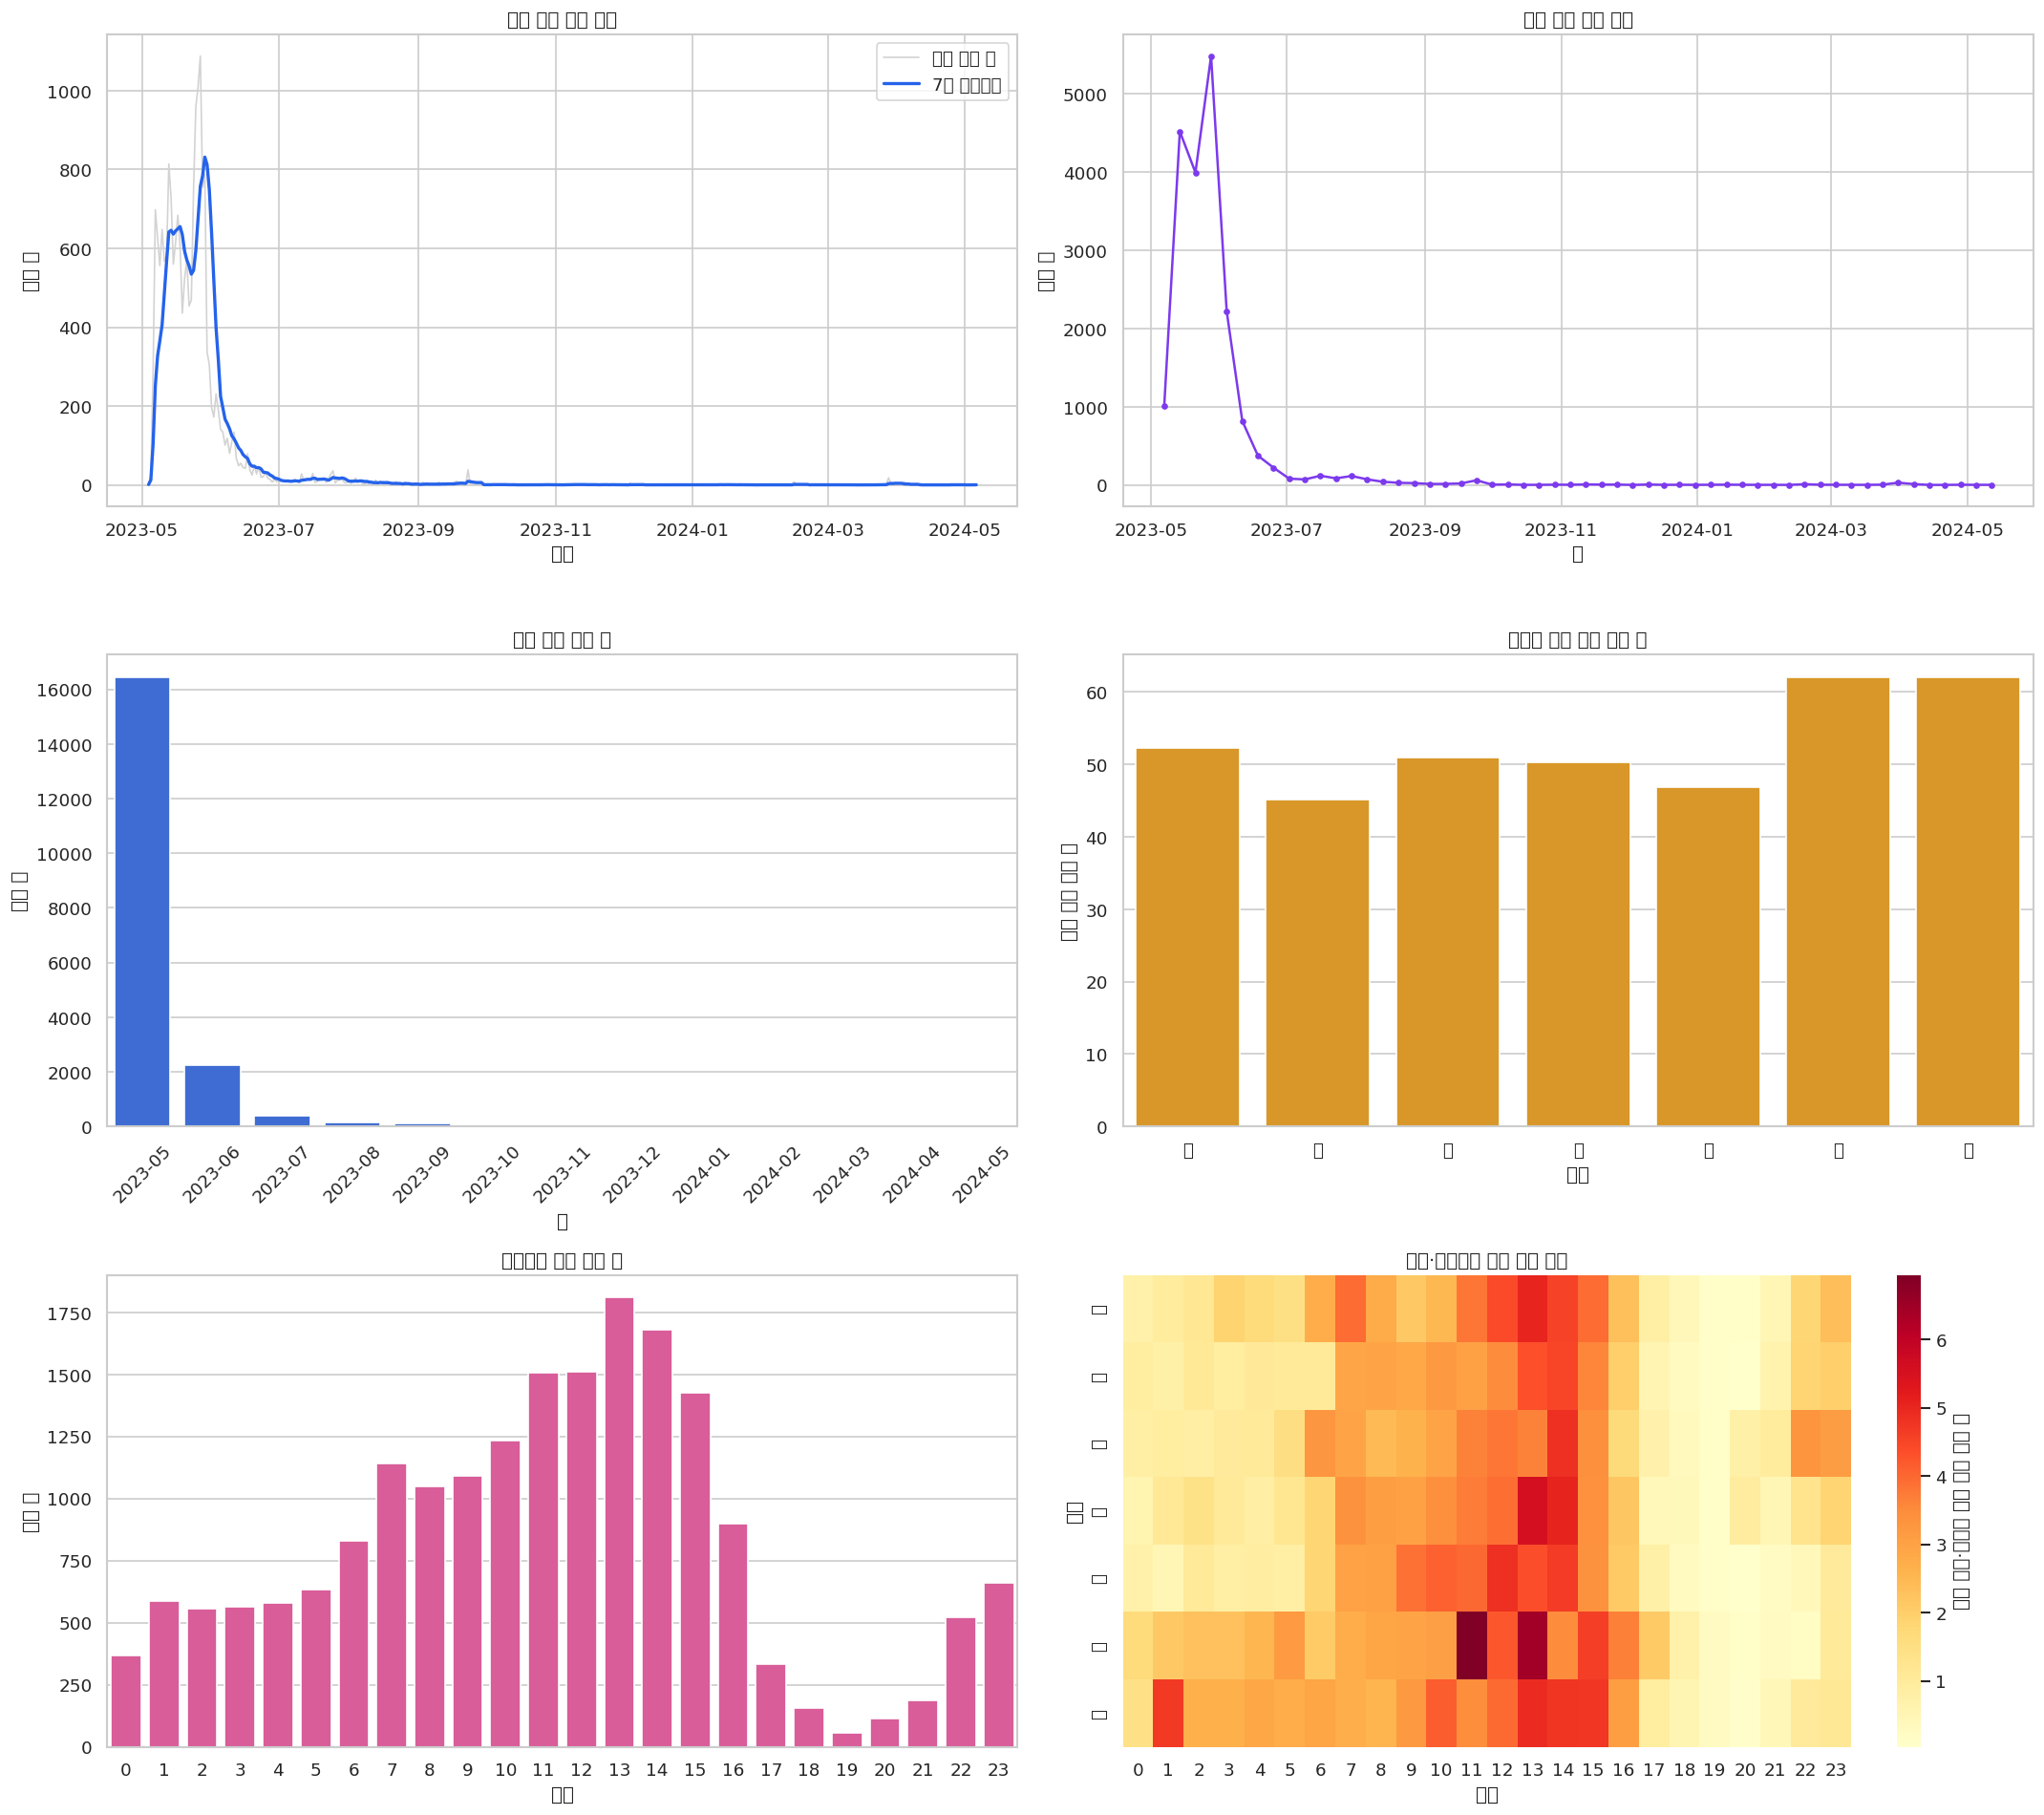

In [241]:
# 차트화

fig, axes = plt.subplots(
    3,
    2,
    figsize=(18, 16),
)

# ① 일별 차단 발생 추이
axes[0, 0].plot(
    daily_summary.index,
    daily_summary["block_count"],
    color="lightgray",
    linewidth=1,
    label="일별 차단 수",
)

axes[0, 0].plot(
    daily_summary.index,
    daily_summary["rolling_7d_mean"],
    color="#2563EB",
    linewidth=2,
    label="7일 이동평균",
)

axes[0, 0].set_title("일별 차단 발생 추이")
axes[0, 0].set_xlabel("날짜")
axes[0, 0].set_ylabel("차단 수")
axes[0, 0].legend()

# ② 주별 차단 발생 추이
axes[0, 1].plot(
    weekly_summary.index,
    weekly_summary["block_count"],
    color="#7C3AED",
    marker="o",
    markersize=3,
)

axes[0, 1].set_title("주별 차단 발생 추이")
axes[0, 1].set_xlabel("주")
axes[0, 1].set_ylabel("차단 수")

# ③ 월별 차단 발생 수
sns.barplot(
    x=monthly_summary.index,
    y=monthly_summary["total_blocks"],
    color="#2563EB",
    ax=axes[1, 0],
)

axes[1, 0].set_title("월별 차단 발생 수")
axes[1, 0].set_xlabel("월")
axes[1, 0].set_ylabel("차단 수")
axes[1, 0].tick_params(
    axis="x",
    rotation=45,
)

# ④ 요일별 하루 평균 차단 수
sns.barplot(
    x=weekday_summary.index,
    y=weekday_summary["daily_mean"],
    color="#F59E0B",
    ax=axes[1, 1],
)

axes[1, 1].set_title("요일별 하루 평균 차단 수")
axes[1, 1].set_xlabel("요일")
axes[1, 1].set_ylabel("하루 평균 차단 수")

# ⑤ 시간대별 차단 분포
sns.barplot(
    x=hour_summary.index,
    y=hour_summary["block_count"],
    color="#EC4899",
    ax=axes[2, 0],
)

axes[2, 0].set_title("시간대별 차단 발생 수")
axes[2, 0].set_xlabel("시간")
axes[2, 0].set_ylabel("차단 수")

# ⑥ 요일 × 시간대 히트맵
sns.heatmap(
    weekday_hour_heatmap,
    cmap="YlOrRd",
    ax=axes[2, 1],
    cbar_kws={
        "label": "해당 요일·시간의 하루 평균 차단 수"
    },
)

axes[2, 1].set_title("요일·시간대별 평균 차단 분포")
axes[2, 1].set_xlabel("시간")
axes[2, 1].set_ylabel("요일")

plt.tight_layout()
plt.show()


#### user_id


In [242]:
accounts_blockrecord['user_id'].nunique()


12552

In [243]:
# user_id별 전체 행 수
block_count_by_user = (
    accounts_blockrecord
    .groupby("user_id")
    .size()
    .rename("block_count")
    .reset_index()
)

display(block_count_by_user.head())


,user_id,block_count
0,837615,1
1,837786,2
2,838168,5
3,839217,1
4,839558,1


In [244]:
top10_block_users = (
    accounts_blockrecord
    .groupby("user_id")
    .size()
    .rename("block_count")
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top10_block_users)


,user_id,block_count
0,1526194,171
1,1415197,163
2,1519819,70
3,1542675,66
4,986459,60
5,1536035,39
6,879416,38
7,1296499,34
8,1343300,34
9,1155373,33


In [245]:
one_block_user_count = (
    block_count_by_user["block_count"]
    .eq(1)
    .sum()
)


In [246]:
block_user_summary = pd.Series(
    {
        "전체 차단 기록 수": len(accounts_blockrecord),
        "차단한 고유 사용자 수": (
            accounts_blockrecord["user_id"].nunique()
        ),
        "차단 기록이 1건인 사용자 수": (
            one_block_user_count
        ),
        "차단 기록이 2건 이상인 사용자 수": (
            block_count_by_user["block_count"]
            .ge(2)
            .sum()
        ),
    },
    name="value",
)

display(block_user_summary.to_frame())


,value
전체 차단 기록 수,19482
차단한 고유 사용자 수,12552
차단 기록이 1건인 사용자 수,9819
차단 기록이 2건 이상인 사용자 수,2733


#### block_user_id


In [247]:
accounts_blockrecord['block_user_id'].nunique()


16240

In [248]:
# block_user_id별 전체 행 수
blocked_count_by_user = (
    accounts_blockrecord
    .groupby("block_user_id")
    .size()
    .rename("blocked_count")
    .reset_index()
)

display(blocked_count_by_user.head())


,block_user_id,blocked_count
0,832740,1
1,833422,1
2,834486,1
3,835888,1
4,835907,1


In [249]:
top10_blocked_users = (
    accounts_blockrecord
    .groupby("block_user_id")
    .size()
    .rename("blocked_count")
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top10_blocked_users)


,block_user_id,blocked_count
0,898020,76
1,877266,25
2,897681,25
3,1380465,25
4,1395312,24
5,876207,24
6,1198628,21
7,1495281,19
8,1031842,18
9,1186363,17


In [250]:
one_blocked_user_count = (
    blocked_count_by_user["blocked_count"]
    .eq(1)
    .sum()
)


In [251]:
blocked_user_summary = pd.Series(
    {
        "전체 차단 기록 수": len(accounts_blockrecord),
        "차단 당한 고유 사용자 수": (
            accounts_blockrecord["block_user_id"].nunique()
        ),
        "차단 당한 기록이 1건인 사용자 수": (
            one_blocked_user_count
        ),
        "차단 당한 기록이 2건 이상인 사용자 수": (
            blocked_count_by_user["blocked_count"]
            .ge(2)
            .sum()
        ),
    },
    name="value",
)

display(blocked_user_summary.to_frame())


,value
전체 차단 기록 수,19482
차단 당한 고유 사용자 수,16240
차단 당한 기록이 1건인 사용자 수,14556
차단 당한 기록이 2건 이상인 사용자 수,1684


### 이상치 판단


In [252]:
# 자기 자신 차단
accounts_blockrecord[accounts_blockrecord['user_id'].eq(accounts_blockrecord["block_user_id"])]


,id,reason,created_at,block_user_id,user_id
4703,6311,모르는 사람임,2023-05-13 16:18:21,877237,877237
4728,6339,사칭 계정,2023-05-13 16:42:05,1012792,1012792
4736,6347,모르는 사람임,2023-05-13 16:50:57,1095213,1095213
4852,6496,친구 사이가 어색해짐,2023-05-14 01:45:40,1197100,1197100
6293,8373,모르는 사람임,2023-05-16 09:12:16,1315402,1315402
6966,9208,모르는 사람임,2023-05-17 10:04:46,1347875,1347875
8231,10777,모르는 사람임,2023-05-19 12:23:58,1374659,1374659
8237,10784,너무 많은 양의 질문을 보냄,2023-05-19 12:39:31,1365534,1365534
8688,11356,친구 사이가 어색해짐,2023-05-20 11:26:13,1358480,1358480
8741,11423,나랑 관련 없는 질문을 자꾸 보냄,2023-05-20 12:54:32,1141855,1141855


- 자기 자신을 차단한 사례 -> 전부 삭제 처리 진행


In [253]:
accounts_blockrecord[accounts_blockrecord.duplicated(
    subset=[
        "user_id",
        "block_user_id",
        "created_at",
    ],
    keep=False,
)]


,id,reason,created_at,block_user_id,user_id
900,1224,너무 많은 양의 질문을 보냄,2023-05-07 15:21:55,954305,917978
901,1225,모르는 사람임,2023-05-07 15:21:55,954305,917978
1125,1509,모르는 사람임,2023-05-08 06:31:49,977940,967723
1126,1510,모르는 사람임,2023-05-08 06:31:49,977940,967723
1882,2555,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1883,2556,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1884,2557,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1885,2558,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1886,2559,모르는 사람임,2023-05-09 11:55:43,1025677,971524
2878,3876,나랑 관련 없는 질문을 자꾸 보냄,2023-05-11 05:13:32,977215,1117631


- 동일인이 동일인을 같은 시간에 차단한 사례
  - reason이 같은 경우와 다른 경우 혼재
    - 같은 경우: 한 행만 남기고 삭제 처리
    - 다른 경우: id의 수치가 가장 작은 행만 남기고 삭제 처리


In [254]:
accounts_blockrecord[accounts_blockrecord.duplicated(
    subset=[
        "user_id",
        "block_user_id",
    ],
    keep=False,
)].sort_values('created_at')


,id,reason,created_at,block_user_id,user_id
8,12,기타,2023-05-05 13:04:31,885794,879662
9,13,기타,2023-05-05 13:04:42,885794,879662
10,14,그냥...,2023-05-05 13:04:52,885794,879662
11,15,기타,2023-05-05 13:04:56,885794,879662
12,16,기타,2023-05-05 13:05:01,885794,879662
...,...,...,...,...,...
19228,24886,모르는 사람임,2023-08-15 18:38:41,992181,1072478
19240,24899,친구 사이가 어색해짐,2023-08-18 12:12:28,1500131,1365572
19248,24912,모르는 사람임,2023-08-21 23:12:23,1029653,955098
19295,25105,모르는 사람임,2023-09-11 14:09:18,1019326,976341


- 동일인이 동일인을 차단한 사례
  - 조심해야할 점: 시각이 다르므로, 차단했다가 푼 다음 다시 차단한 경우도 가능하므로 전부 이상치로 처리하면 안됨


### 이상치 처리


In [255]:
# 원본 테이블 보호
block_raw = accounts_blockrecord.copy()

# 차단 사유 문자열 정리
block_raw["reason"] = (
    block_raw["reason"]
    .astype("string")
    .str.strip()
)

# id가 작은 행부터 정렬
block_raw = block_raw.sort_values("id").copy()


#### 자기 자신 차단


In [256]:
# 자기 자신을 차단한 행

self_block_mask = (
    block_raw["user_id"]
    .eq(block_raw["block_user_id"])
)

self_block_rows = (
    block_raw.loc[self_block_mask]
    .copy()
)

print("자기 자신 차단 행:", f"{len(self_block_rows):,}")

display(self_block_rows)


자기 자신 차단 행: 33


,id,reason,created_at,block_user_id,user_id
4703,6311,모르는 사람임,2023-05-13 16:18:21,877237,877237
4728,6339,사칭 계정,2023-05-13 16:42:05,1012792,1012792
4736,6347,모르는 사람임,2023-05-13 16:50:57,1095213,1095213
4852,6496,친구 사이가 어색해짐,2023-05-14 01:45:40,1197100,1197100
6293,8373,모르는 사람임,2023-05-16 09:12:16,1315402,1315402
6966,9208,모르는 사람임,2023-05-17 10:04:46,1347875,1347875
8231,10777,모르는 사람임,2023-05-19 12:23:58,1374659,1374659
8237,10784,너무 많은 양의 질문을 보냄,2023-05-19 12:39:31,1365534,1365534
8688,11356,친구 사이가 어색해짐,2023-05-20 11:26:13,1358480,1358480
8741,11423,나랑 관련 없는 질문을 자꾸 보냄,2023-05-20 12:54:32,1141855,1141855


In [257]:
block_valid = (
    block_raw.loc[
        ~self_block_mask
        & block_raw["created_at"].notna()
    ]
    .copy()
)


#### 동일인이 동일인을 같은 시각에 차단한 경우


In [258]:
# reason이 같은 경우

reason_record_keys = [
    "user_id",
    "block_user_id",
    "created_at",
    "reason",
]

exact_duplicate_mask = (
    block_valid.duplicated(
        subset=reason_record_keys,
        keep=False,
    )
)

exact_duplicate_rows = (
    block_valid.loc[exact_duplicate_mask]
    .sort_values(reason_record_keys + ["id"])
)

print(
    "완전 동일 중복에 관여한 전체 행:",
    f"{len(exact_duplicate_rows):,}",
)

display(exact_duplicate_rows)


완전 동일 중복에 관여한 전체 행: 9


,id,reason,created_at,block_user_id,user_id
4615,6161,모르는 사람임,2023-05-13 14:54:47,931725,859334
4616,6162,모르는 사람임,2023-05-13 14:54:47,931725,859334
1125,1509,모르는 사람임,2023-05-08 06:31:49,977940,967723
1126,1510,모르는 사람임,2023-05-08 06:31:49,977940,967723
1882,2555,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1883,2556,모르는 사람임,2023-05-09 11:55:42,1025677,971524
1884,2557,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1885,2558,모르는 사람임,2023-05-09 11:55:43,1025677,971524
1886,2559,모르는 사람임,2023-05-09 11:55:43,1025677,971524


In [259]:
# id가 작은 값 한행만 남기고 삭제
block_reason_clean = (
    block_valid
    .sort_values("id")
    .drop_duplicates(
        subset=reason_record_keys,
        keep="first",
    )
    .copy()
)

exact_duplicate_removed = (
    len(block_valid)
    - len(block_reason_clean)
)

print(
    "완전 동일 중복으로 제거된 행:",
    f"{exact_duplicate_removed:,}",
)


완전 동일 중복으로 제거된 행: 5


In [260]:
# reason이 다른 경우

event_keys = [
    "user_id",
    "block_user_id",
    "created_at",
]

same_event_summary = (
    block_reason_clean
    .groupby(
        event_keys,
        as_index=False,
        dropna=False,
    )
    .agg(
        rows=("id", "size"),
        reason_count=("reason", "nunique"),
        reason_list=(
            "reason",
            lambda x: tuple(pd.unique(x.dropna())),
        ),
        min_id=("id", "min"),
    )
)

reason_conflict_events = (
    same_event_summary.loc[
        same_event_summary["reason_count"] > 1
    ]
    .copy()
)

print(
    "동일 시각에 사유가 여러 개인 차단 사건:",
    f"{len(reason_conflict_events):,}",
)

display(reason_conflict_events)


동일 시각에 사유가 여러 개인 차단 사건: 8


,user_id,block_user_id,created_at,rows,reason_count,reason_list,min_id
956,889161,876197,2023-05-16 11:27:34,3,3,"(너무 많은 양의 질문을 보냄, 모르는 사람임, 나랑 관련 없는 질문을 자꾸 보냄)",8492
957,889161,876197,2023-05-16 11:27:35,3,3,"(너무 많은 양의 질문을 보냄, 모르는 사람임, 나랑 관련 없는 질문을 자꾸 보냄)",8495
2077,917978,954305,2023-05-07 15:21:55,2,2,"(너무 많은 양의 질문을 보냄, 모르는 사람임)",1224
8460,1117631,977215,2023-05-11 05:13:32,2,2,"(나랑 관련 없는 질문을 자꾸 보냄, 친구 사이가 어색해짐)",3876
9968,1169540,1171686,2023-05-13 02:32:43,2,2,"(모르는 사람임, 나랑 관련 없는 질문을 자꾸 보냄)",5426
10184,1176971,1161603,2023-05-18 14:21:02,2,2,"(나랑 관련 없는 질문을 자꾸 보냄, 너무 많은 양의 질문을 보냄)",10181
10713,1196057,923491,2023-05-17 23:45:17,2,2,"(친구 사이가 어색해짐, 너무 많은 양의 질문을 보냄)",9726
11404,1221770,1223805,2023-05-15 04:44:17,2,2,"(너무 많은 양의 질문을 보냄, 모르는 사람임)",7413


In [261]:
block_event_clean = (
    block_reason_clean
    .sort_values("id")
    .groupby(
        event_keys,
        as_index=False,
        dropna=False,
    )
    .agg(
        # 해당 사건에서 가장 작은 id
        id=("id", "min"),

        # 가장 작은 id 행의 대표 사유
        reason=("reason", "first"),

        # 실제로 기록된 모든 사유
        reason_list=(
            "reason",
            lambda x: tuple(pd.unique(x.dropna())),
        ),

        # 서로 다른 사유 개수
        reason_count=("reason", "nunique"),
    )
)

block_event_clean["has_reason_conflict"] = (
    block_event_clean["reason_count"] > 1
)

reason_conflict_collapsed = (
    len(block_reason_clean)
    - len(block_event_clean)
)


#### 동일인이 동일인을 다른 시각에 차단한 경우


In [262]:
pair_keys = [
    "user_id",
    "block_user_id",
]

block_event_clean = (
    block_event_clean
    .sort_values(
        pair_keys + ["created_at", "id"]
    )
    .reset_index(drop=True)
)

# 동일 관계 내 차단 기록 순서
block_event_clean["block_order_within_pair"] = (
    block_event_clean
    .groupby(pair_keys)
    .cumcount()
    .add(1)
)

# 동일 관계의 이전 차단 시각
block_event_clean["previous_block_at"] = (
    block_event_clean
    .groupby(pair_keys)["created_at"]
    .shift()
)

# 이전 차단 기록과의 간격
block_event_clean["seconds_since_previous_block"] = (
    block_event_clean["created_at"]
    - block_event_clean["previous_block_at"]
).dt.total_seconds()

# 동일 관계에서 두 번째 이상 등장한 기록
block_event_clean["is_repeated_pair"] = (
    block_event_clean["block_order_within_pair"] > 1
)


In [263]:
# 1분 이내 반복된 행 확인

block_event_clean["is_rapid_repeat_60s"] = (
    block_event_clean[
        "seconds_since_previous_block"
    ].between(
        0,
        60,
        inclusive="right",
    )
)

rapid_repeat_rows = (
    block_event_clean.loc[
        block_event_clean["is_rapid_repeat_60s"]
    ]
    .sort_values(
        pair_keys + ["created_at"]
    )
)

print(
    "60초 이내 반복된 차단 사건:",
    f"{len(rapid_repeat_rows):,}",
)

display(rapid_repeat_rows.head(100))


60초 이내 반복된 차단 사건: 486


,user_id,block_user_id,created_at,id,reason,reason_list,reason_count,has_reason_conflict,block_order_within_pair,previous_block_at,seconds_since_previous_block,is_repeated_pair,is_rapid_repeat_60s
118,847011,897681,2023-05-08 08:41:45,1617,너무 많은 양의 질문을 보냄,"(너무 많은 양의 질문을 보냄,)",1,False,2,2023-05-08 08:41:27,18.0,True,True
139,848687,920457,2023-05-07 05:25:31,599,모르는 사람임,"(모르는 사람임,)",1,False,2,2023-05-07 05:25:00,31.0,True,True
140,848687,920457,2023-05-07 05:25:34,600,모르는 사람임,"(모르는 사람임,)",1,False,3,2023-05-07 05:25:31,3.0,True,True
183,851333,852860,2023-05-06 08:35:18,107,친구 사이가 어색해짐,"(친구 사이가 어색해짐,)",1,False,2,2023-05-06 08:35:02,16.0,True,True
208,852455,847301,2023-05-07 08:51:18,760,친구 사이가 어색해짐,"(친구 사이가 어색해짐,)",1,False,3,2023-05-07 08:51:01,17.0,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1790,909818,898020,2023-05-07 09:13:17,780,너무 많은 양의 질문을 보냄,"(너무 많은 양의 질문을 보냄,)",1,False,6,2023-05-07 09:13:14,3.0,True,True
1793,909818,898020,2023-05-07 12:52:30,1003,나랑 관련 없는 질문을 자꾸 보냄,"(나랑 관련 없는 질문을 자꾸 보냄,)",1,False,9,2023-05-07 12:52:22,8.0,True,True
1796,909818,898020,2023-05-08 15:42:22,2043,나랑 관련 없는 질문을 자꾸 보냄,"(나랑 관련 없는 질문을 자꾸 보냄,)",1,False,12,2023-05-08 15:42:20,2.0,True,True
1797,909818,898020,2023-05-08 15:42:24,2044,나랑 관련 없는 질문을 자꾸 보냄,"(나랑 관련 없는 질문을 자꾸 보냄,)",1,False,13,2023-05-08 15:42:22,2.0,True,True


### 결과


In [264]:
block_preprocessing_summary = pd.Series(
    {
        "원본 행 수": len(block_raw),
        "제외된 자기 자신 차단 행": len(self_block_rows),
        "완전 동일 중복 제거 행": exact_duplicate_removed,
        "사유 단위 최종 행 수": len(block_reason_clean),
        "복수 사유 통합으로 감소한 행": (
            reason_conflict_collapsed
        ),
        "차단 사건 단위 최종 행 수": len(block_event_clean),
        "복수 사유 차단 사건 수": (
            block_event_clean["has_reason_conflict"].sum()
        ),
        "두 번째 이상 반복 차단 사건": (
            block_event_clean["is_repeated_pair"].sum()
        ),
        "60초 이내 반복 사건": (
            block_event_clean["is_rapid_repeat_60s"].sum()
        ),
    },
    name="value",
)

display(block_preprocessing_summary.to_frame())


,value
원본 행 수,19482
제외된 자기 자신 차단 행,33
완전 동일 중복 제거 행,5
사유 단위 최종 행 수,19444
복수 사유 통합으로 감소한 행,10
차단 사건 단위 최종 행 수,19434
복수 사유 차단 사건 수,8
두 번째 이상 반복 차단 사건,962
60초 이내 반복 사건,486


## polls_questionset 테이블


In [265]:
polls_questionset = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/polls_questionset.csv')


### 구조 파악


In [266]:
# 원본 보호
questionset_raw = polls_questionset.copy()

# 전처리용 테이블 생성
questionset_base = (
    questionset_raw
    .rename(columns={"id": "questionset_id"})
    .copy()
)

# status 값 정리
questionset_base["status"] = (
    questionset_base["status"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# created_at, opening_time 컬럼 날짜형으로 변환
for column in ["created_at", "opening_time"]:
    questionset_base[column] = pd.to_datetime(
        questionset_base[column]
    )


In [267]:
questionset_base.shape


(158384, 6)

In [268]:
questionset_base.head()


,questionset_id,question_piece_id_list,opening_time,status,created_at,user_id
0,99817,"[998458, 998459, 998460, 998461, 998462, 99846...",2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
1,99830,"[998588, 998589, 998590, 998591, 998592, 99859...",2023-04-28 12:28:07,F,2023-04-28 12:28:07,849438
2,99840,"[998689, 998691, 998693, 998695, 998697, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,847375
3,99841,"[998688, 998690, 998692, 998694, 998696, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,849446
4,99848,"[998768, 998769, 998770, 998771, 998772, 99877...",2023-04-28 12:28:57,F,2023-04-28 12:28:57,849477


In [269]:
questionset_base.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158384 entries, 0 to 158383
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   questionset_id          158384 non-null  int64         
 1   question_piece_id_list  158384 non-null  object        
 2   opening_time            158384 non-null  datetime64[ns]
 3   status                  158384 non-null  string        
 4   created_at              158384 non-null  datetime64[ns]
 5   user_id                 158384 non-null  int64         
dtypes: datetime64[ns](2), int64(2), object(1), string(1)
memory usage: 7.3+ MB


In [270]:
questionset_base.describe()


,questionset_id,opening_time,created_at,user_id
count,1.583840e+05,158384,158384,1.583840e+05
mean,7.641274e+06,2023-05-17 13:25:41.180416256,2023-05-17 12:43:12.170648832,1.106752e+06
min,9.981700e+04,2023-04-28 12:27:22,2023-04-28 12:27:23,8.380230e+05
25%,1.953393e+06,2023-05-09 15:46:49.500000,2023-05-09 14:58:05.500000,8.847470e+05
50%,6.757335e+06,2023-05-15 13:43:55.500000,2023-05-15 13:04:46.500000,1.117999e+06
75%,1.217510e+07,2023-05-22 11:43:24.500000,2023-05-22 11:04:03,1.261250e+06
max,2.083845e+07,2024-05-07 12:12:30,2024-05-07 11:32:30,1.583358e+06
std,5.943690e+06,NaN,NaN,2.078612e+05


In [271]:
questionset_base.isna().sum()


,0
questionset_id,0
question_piece_id_list,0
opening_time,0
status,0
created_at,0
user_id,0


In [272]:
questionset_base.duplicated().sum()


np.int64(0)

#### id(questionset_id)


In [273]:
questionset_base['questionset_id'].isna().sum()


np.int64(0)

In [274]:
questionset_base['questionset_id'].duplicated().sum()


np.int64(0)

- 결측, 중복 없음


#### question_piece_id_list


In [275]:
# 문자열을 리스트로 변환

def parse_question_piece_list(value):
    if isinstance(value, list):
        return value, False

    if pd.isna(value) or str(value).strip() == "":
        return [], False

    try:
        parsed = json.loads(value)

        if not isinstance(parsed, list):
            return [], True

        return parsed, False

    except (json.JSONDecodeError, TypeError):
        return [], True

parsed_result = (
    questionset_base["question_piece_id_list"]
    .apply(parse_question_piece_list)
)

questionset_base["question_piece_ids"] = (
    parsed_result.str[0]
)

questionset_base["piece_list_parse_error"] = (
    parsed_result.str[1]
)

questionset_base["piece_count"] = (
    questionset_base["question_piece_ids"].str.len()
)


In [276]:
# 리스트 구조 체크

questionset_base["has_duplicate_piece"] = (
    questionset_base["question_piece_ids"]
    .apply(
        lambda values: (
            len(values) != len(set(values))
        )
    )
)

questionset_base["has_invalid_piece_type"] = (
    questionset_base["question_piece_ids"]
    .apply(
        lambda values: any(
            not isinstance(value, int)
            for value in values
        )
    )
)

piece_list_validation = pd.Series(
    {
        "질문 세트 수": len(questionset_base),
        "리스트 파싱 오류": (
            questionset_base[
                "piece_list_parse_error"
            ].sum()
        ),
        "빈 문항 리스트": (
            questionset_base["piece_count"].eq(0).sum()
        ),
        "문항 수가 10개가 아닌 세트": (
            questionset_base["piece_count"].ne(10).sum()
        ),
        "세트 내부 문항 중복": (
            questionset_base[
                "has_duplicate_piece"
            ].sum()
        ),
        "문항 ID 자료형 오류": (
            questionset_base[
                "has_invalid_piece_type"
            ].sum()
        ),
    },
    name="value",
)

display(piece_list_validation.to_frame())


,value
질문 세트 수,158384
리스트 파싱 오류,0
빈 문항 리스트,0
문항 수가 10개가 아닌 세트,0
세트 내부 문항 중복,0
문항 ID 자료형 오류,0


In [277]:
# 문항 개수 분포 확인

piece_count_distribution = (
    questionset_base["piece_count"]
    .value_counts()
    .sort_index()
    .to_frame("questionset_rows")
)

display(piece_count_distribution)


,questionset_rows
piece_count,
10,158384


#### opening_time


In [278]:
questionset_base['opening_time'].isna().sum()


np.int64(0)

In [279]:
questionset_base['opening_time'].min()


Timestamp('2023-04-28 12:27:22')

In [280]:
questionset_base['opening_time'].max()


Timestamp('2024-05-07 12:12:30')

#### status


In [281]:
questionset_base['status'].unique()


<StringArray>
['F', 'C', 'O']
Length: 3, dtype: string

In [282]:
status_validation = (
    questionset_base["status"]
    .value_counts(dropna=False)
    .to_frame("rows")
)

status_validation["rate_pct"] = (
    status_validation["rows"]
    / status_validation["rows"].sum()
    * 100
)

display(status_validation.round(2))


,rows,rate_pct
status,,
F,153411,96.86
O,4407,2.78
C,566,0.36


#### created_at


In [283]:
questionset_base['created_at'].isna().sum()


np.int64(0)

In [284]:
questionset_base['created_at'].min()


Timestamp('2023-04-28 12:27:23')

In [285]:
questionset_base['created_at'].max()


Timestamp('2024-05-07 11:32:30')

#### user_id


In [286]:
questionset_base['user_id'].isna().sum()


np.int64(0)

In [287]:
questionset_base['user_id'].nunique()


4972

### 이상치 판단/처리


In [288]:
# 리스트를 제외한 컬럼에서의 중복 체크

# 리스트 튜플화
questionset_base["question_piece_tuple"] = (
    questionset_base["question_piece_ids"]
    .apply(tuple)
)

normalized_columns = [
    "user_id",
    "question_piece_tuple",
    "opening_time",
    "status",
    "created_at",
]

# questionset_id만 다르고 실제 내용이 같은 경우
questionset_base[
    questionset_base.duplicated(
        subset=normalized_columns
    )]


,questionset_id,question_piece_id_list,opening_time,status,created_at,user_id,question_piece_ids,piece_list_parse_error,piece_count,has_duplicate_piece,has_invalid_piece_type,question_piece_tuple


In [289]:
# created_at, opening_time 비교

# 차이
questionset_base["opening_delay_seconds"] = (
    questionset_base["opening_time"]
    - questionset_base["created_at"]
).dt.total_seconds()

# 차이가 0 미만인 경우 이상치
questionset_base["opening_before_created"] = (
    questionset_base[
        "opening_delay_seconds"
    ] < 0
)

questionset_base[questionset_base["opening_before_created"]]


,questionset_id,question_piece_id_list,opening_time,status,created_at,user_id,question_piece_ids,piece_list_parse_error,piece_count,has_duplicate_piece,has_invalid_piece_type,question_piece_tuple,opening_delay_seconds,opening_before_created
0,99817,"[998458, 998459, 998460, 998461, 998462, 99846...",2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436,"[998458, 998459, 998460, 998461, 998462, 99846...",False,10,False,False,"(998458, 998459, 998460, 998461, 998462, 99846...",-1.0,True
22,99916,"[999448, 999449, 999450, 999451, 999452, 99945...",2023-04-28 12:31:51,F,2023-04-28 12:31:52,849692,"[999448, 999449, 999450, 999451, 999452, 99945...",False,10,False,False,"(999448, 999449, 999450, 999451, 999452, 99945...",-1.0,True
31,99974,"[1000028, 1000029, 1000030, 1000031, 1000032, ...",2023-04-28 12:33:35,F,2023-04-28 12:33:36,849864,"[1000028, 1000029, 1000030, 1000031, 1000032, ...",False,10,False,False,"(1000028, 1000029, 1000030, 1000031, 1000032, ...",-1.0,True
63,100426,"[1004548, 1004549, 1004550, 1004551, 1004552, ...",2023-04-28 12:48:57,F,2023-04-28 12:48:58,849620,"[1004548, 1004549, 1004550, 1004551, 1004552, ...",False,10,False,False,"(1004548, 1004549, 1004550, 1004551, 1004552, ...",-1.0,True
79,100637,"[1006658, 1006659, 1006660, 1006661, 1006662, ...",2023-04-28 12:58:39,F,2023-04-28 12:58:40,849938,"[1006658, 1006659, 1006660, 1006661, 1006662, ...",False,10,False,False,"(1006658, 1006659, 1006660, 1006661, 1006662, ...",-1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143350,16798833,"[167989091, 167989092, 167989093, 167989094, 1...",2023-05-29 14:32:57,F,2023-05-29 14:32:58,1547256,"[167989091, 167989092, 167989093, 167989094, 1...",False,10,False,False,"(167989091, 167989092, 167989093, 167989094, 1...",-1.0,True
144351,17024477,"[170245531, 170245532, 170245533, 170245534, 1...",2023-05-30 06:02:01,F,2023-05-30 06:02:02,1550358,"[170245531, 170245532, 170245533, 170245534, 1...",False,10,False,False,"(170245531, 170245532, 170245533, 170245534, 1...",-1.0,True
145183,17208810,"[172088858, 172088861, 172088863, 172088864, 1...",2023-05-30 13:17:42,F,2023-05-30 13:17:43,1553161,"[172088858, 172088861, 172088863, 172088864, 1...",False,10,False,False,"(172088858, 172088861, 172088863, 172088864, 1...",-1.0,True
156012,20052297,"[200523731, 200523732, 200523733, 200523734, 2...",2023-06-17 11:35:32,F,2023-06-17 11:35:33,1576277,"[200523731, 200523732, 200523733, 200523734, 2...",False,10,False,False,"(200523731, 200523732, 200523733, 200523734, 2...",-1.0,True


- 질문 세트 생성 시점보다 오픈 시점이 더 빠른 경우: 679행


In [290]:
negative_opening_delay = (
    questionset_base.loc[
        questionset_base["opening_before_created"],
        "opening_delay_seconds",
    ]
)

negative_delay_summary = pd.Series(
    {
        "해당 행 수": len(negative_opening_delay),
        "가장 큰 음수 차이(초)": (
            negative_opening_delay.min()
        ),
        "중앙값(초)": (
            negative_opening_delay.median()
        ),
        "0에 가장 가까운 차이(초)": (
            negative_opening_delay.max()
        ),
    },
    name="value",
)

display(negative_delay_summary.to_frame())

display(
    negative_opening_delay
    .value_counts()
    .sort_index()
    .to_frame("rows")
)


,value
해당 행 수,679.0
가장 큰 음수 차이(초),-29.0
중앙값(초),-1.0
0에 가장 가까운 차이(초),-1.0


,rows
opening_delay_seconds,
-29.0,1
-17.0,1
-14.0,3
-12.0,1
-11.0,1
-10.0,3
-9.0,2
-8.0,3
-7.0,3


In [291]:
# 동일 유저/시점 생성된 질문 세트 - 이상치

questionset_base["same_user_created_count"] = (
    questionset_base
    .groupby(
        ["user_id", "created_at"]
    )["questionset_id"]
    .transform("size")
)

same_user_created_mask = (
    questionset_base[
        "same_user_created_count"
    ] > 1
)

same_user_created_mask.sum()


np.int64(54)

In [292]:
display(
    questionset_base.loc[
        same_user_created_mask,
        [
            "questionset_id",
            "user_id",
            "created_at",
            "opening_time",
            "status",
            "question_piece_ids",
        ],
    ]
    .sort_values(
        ["user_id", "created_at", "questionset_id"]
    )
    .head(50)
)


,questionset_id,user_id,created_at,opening_time,status,question_piece_ids
35644,1432410,855825,2023-05-08 15:23:21,2023-05-08 15:23:21,F,"[14324388, 14324390, 14324392, 14324393, 14324..."
35645,1432412,855825,2023-05-08 15:23:21,2023-05-08 16:13:20,F,"[14324402, 14324404, 14324405, 14324407, 14324..."
52762,3878252,856195,2023-05-12 11:26:11,2023-05-12 12:06:10,F,"[38782804, 38782806, 38782809, 38782812, 38782..."
52763,3878253,856195,2023-05-12 11:26:11,2023-05-12 12:06:10,F,"[38782802, 38782805, 38782808, 38782811, 38782..."
21014,525683,885746,2023-05-06 03:50:54,2023-05-06 03:50:54,F,"[5257125, 5257126, 5257128, 5257129, 5257131, ..."
21015,525684,885746,2023-05-06 03:50:54,2023-05-06 04:40:54,F,"[5257117, 5257119, 5257120, 5257121, 5257122, ..."
26986,747666,887754,2023-05-07 02:42:03,2023-05-07 02:42:03,F,"[7476948, 7476949, 7476950, 7476951, 7476952, ..."
26987,747669,887754,2023-05-07 02:42:03,2023-05-07 03:32:03,F,"[7476978, 7476979, 7476980, 7476981, 7476982, ..."
38360,1744771,926141,2023-05-09 10:43:11,2023-05-09 10:43:11,F,"[17447978, 17447983, 17447987, 17447990, 17447..."
38361,1744772,926141,2023-05-09 10:43:11,2023-05-09 10:43:11,F,"[17447997, 17448002, 17448007, 17448014, 17448..."


- 동일시점 생성하긴 했지만 유저/시점만 동일할뿐 이외에는 이상할 것이 없다고 판단해 그대로 유지


### 테이블 생성


In [293]:
# 질문 세트-문항 연결 테이블 생성

valid_piece_list_mask = (
    ~questionset_base["piece_list_parse_error"]
    & questionset_base["piece_count"].eq(10)
    & ~questionset_base["has_duplicate_piece"]
    & ~questionset_base["has_invalid_piece_type"]
)

questionset_piece_long = (
    questionset_base.loc[
        valid_piece_list_mask,
        [
            "questionset_id",
            "question_piece_ids",
        ],
    ]
    .explode(
        "question_piece_ids",
        ignore_index=True,
    )
    .rename(
        columns={
            "question_piece_ids": "question_piece_id"
        }
    )
)

questionset_piece_long["question_piece_id"] = (
    pd.to_numeric(
        questionset_piece_long["question_piece_id"],
        errors="coerce",
    )
    .astype("Int64")
)

# 원본 리스트에 저장된 문항 순서
questionset_piece_long["stored_position"] = (
    questionset_piece_long
    .groupby("questionset_id")
    .cumcount()
    .add(1)
)


In [294]:
# 질문 세트 단위 최종 테이블

questionset_clean = (
    questionset_base[
        [
            "questionset_id",
            "user_id",
            "status",
            "created_at",
            "opening_time",
            "opening_delay_seconds",
            "opening_before_created",
            "same_user_created_count",
        ]
    ]
    .rename(
        columns={
            "same_user_created_count":
            "same_user_created_at_set_count"
        }
    )
    .copy()
)


In [295]:
# 최종 테이블 검증

expected_piece_rows = (
    questionset_base.loc[
        valid_piece_list_mask,
        "piece_count",
    ].sum()
)

piece_rows_per_set = (
    questionset_piece_long
    .groupby("questionset_id")
    .size()
)

questionset_preprocessing_summary = pd.Series(
    {
        "원본 질문 세트 행 수":
            len(questionset_raw),

        "최종 질문 세트 행 수":
            len(questionset_clean),

        "처리 과정에서 제외된 세트 수":
            len(questionset_raw)
            - len(questionset_clean),

        "질문 세트 ID 중복":
            questionset_clean[
                "questionset_id"
            ].duplicated().sum(),

        "리스트 파싱 오류":
            questionset_base[
                "piece_list_parse_error"
            ].sum(),

        "문항 수가 10개가 아닌 세트":
            questionset_base[
                "piece_count"
            ].ne(10).sum(),

        "세트 내부 문항 중복":
            questionset_base[
                "has_duplicate_piece"
            ].sum(),

        "문항 ID 자료형 오류":
            questionset_base[
                "has_invalid_piece_type"
            ].sum(),

        "생성보다 먼저 오픈된 세트":
            questionset_clean[
                "opening_before_created"
            ].sum(),

        "동일 유저·동일 시각 생성 세트 행":
            questionset_clean[
                "same_user_created_at_set_count"
            ].gt(1).sum(),

        "예상 세트-문항 행 수":
            expected_piece_rows,

        "실제 세트-문항 행 수":
            len(questionset_piece_long),

        "세트당 문항 수가 10개가 아닌 세트":
            piece_rows_per_set.ne(10).sum(),

        "펼친 문항 ID 결측":
            questionset_piece_long[
                "question_piece_id"
            ].isna().sum(),

        "동일 세트 내부 문항 중복":
            questionset_piece_long.duplicated(
                [
                    "questionset_id",
                    "question_piece_id",
                ]
            ).sum(),
    },
    name="value",
)

display(
    questionset_preprocessing_summary.to_frame()
)


,value
원본 질문 세트 행 수,158384
최종 질문 세트 행 수,158384
처리 과정에서 제외된 세트 수,0
질문 세트 ID 중복,0
리스트 파싱 오류,0
문항 수가 10개가 아닌 세트,0
세트 내부 문항 중복,0
문항 ID 자료형 오류,0
생성보다 먼저 오픈된 세트,679
동일 유저·동일 시각 생성 세트 행,54


## csv파일로 추출


In [296]:
import os

# 전처리 CSV 저장 폴더
EXPORT_DIR = (
    "/content/drive/MyDrive/"
    "코드잇 3팀 고급 프로젝트/"
    "01_전처리 완료된 csv"
)

os.makedirs(EXPORT_DIR, exist_ok=True)

print("저장 폴더:", EXPORT_DIR)


저장 폴더: /content/drive/MyDrive/코드잇 3팀 고급 프로젝트/01_전처리 완료된 csv


In [297]:
def collection_to_json(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        converted = [
            item.item()
            if isinstance(item, np.generic)
            else item
            for item in value
        ]

        return json.dumps(
            converted,
            ensure_ascii=False,
        )

    return value


In [298]:
# 사용자별 출석 목록
attendance_base_export = (
    attendance_base[
        [
            "attendance_record_id",
            "user_id",
            "attendance_dates",
            "parse_error",
        ]
    ]
    .rename(
        columns={
            "attendance_dates": "attendance_date_list"
        }
    )
    .copy()
)

attendance_base_export["attendance_date_list"] = (
    attendance_base_export["attendance_date_list"]
    .apply(collection_to_json)
)

# 사용자-출석일 단위
attendance_long_export = attendance_long.copy()

# 날짜만 저장
attendance_long_export["attendance_date"] = (
    attendance_long_export["attendance_date"]
    .dt.strftime("%Y-%m-%d")
)


In [299]:
# 차단 사유 단위
block_reason_export = block_reason_clean.copy()

# 차단 사건 단위
block_event_export = block_event_clean.copy()

# 여러 사유가 담긴 튜플을 JSON 문자열로 변환
block_event_export["reason_list"] = (
    block_event_export["reason_list"]
    .apply(collection_to_json)
)


In [300]:
# 질문 세트 단위
questionset_export = questionset_clean.copy()

# 질문 세트-문항 연결 단위
questionset_piece_export = (
    questionset_piece_long[
        [
            "questionset_id",
            "question_piece_id",
            "stored_position",
        ]
    ]
    .copy()
)


In [301]:
# export_tables = {
#     "accounts_attendance_clean.csv": (
#         attendance_long_export
#     ),
#     "accounts_blockrecord_clean.csv": (
#         block_event_export
#     ),
#     "polls_questionset_clean.csv": (
#         questionset_export
#     ),
#     "polls_questionset_piece_clean.csv": (
#         questionset_piece_export
#     ),
# }

# export_result = []

# for file_name, dataframe in export_tables.items():
#     file_path = os.path.join(
#         EXPORT_DIR,
#         file_name,
#     )

#     dataframe.to_csv(
#         file_path,
#         index=False,
#         encoding="utf-8-sig",
#         date_format="%Y-%m-%d %H:%M:%S",
#     )

#     export_result.append({
#         "file_name": file_name,
#         "rows": len(dataframe),
#         "columns": dataframe.shape[1],
#         "file_size_mb": round(
#             os.path.getsize(file_path)
#             / 1024**2,
#             2,
#         ),
#         "saved": os.path.exists(file_path),
#     })

# export_summary = pd.DataFrame(export_result)

# display(export_summary)


# 소주제에 맞게 테이블 병합


In [302]:
accounts_userquestionrecord_cleaned = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/01_전처리 완료된 csv/accounts_userquestionrecord_cleaned.csv')
accounts_attendance_clean = pd.read_csv('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/01_전처리 완료된 csv/accounts_attendance_clean.csv')


## 유저-출석 참여


In [303]:
# 1. 원본 보호

uq = accounts_userquestionrecord_cleaned.copy()
att = accounts_attendance_clean.copy()


In [304]:
# 2. 데이터형 세팅

# 날짜형으로 변환
uq["created_at"] = pd.to_datetime(
    uq["created_at"]
)

uq["answer_updated_at"] = pd.to_datetime(
    uq["answer_updated_at"]
)

att["attendance_date"] = pd.to_datetime(
    att["attendance_date"]
).dt.floor("D")

# user_id 데이터형 통일
uq["user_id"] = pd.to_numeric(
    uq["user_id"]
).astype("Int64")

att["user_id"] = pd.to_numeric(
    att["user_id"]
).astype("Int64")


In [305]:
# 3-1. 투표 완료 기록 추출
# status == 'C': 투표 완료 후 닫힌 기록
# user_id, created_at: 결측이 아닐 때 -> 투표한 유저와 투표 완료 시각이 확인되는 행

vote_rows = uq.loc[
    uq["status"].astype("string").str.upper().eq("C")
    & uq["user_id"].notna()
    & uq["created_at"].notna(),
    [
        "id",
        "user_id",
        "question_id",
        "question_piece_id",
        "created_at"
    ],
].copy()


In [306]:
# 3-2. 투표 완료 시각에서 일별로 활성 기준일 생성

vote_rows["activity_date"] = (
    vote_rows["created_at"].dt.floor("D")
)


In [307]:
# 3-3. 유저별/출석 참여일별로 투표 활성 집계
# vote_count: 유저가 해당일 완료한 투표 수
# unique_questions: 투표한 고유 question_id 수
# unique_question_pieces: 투표한 고유 question_piece_id 수
# first_vote_at / last_vote_at: 해당일의 첫/마지막 투포 시각

vote_daily = (
    vote_rows
    .groupby(
        ["user_id", "activity_date"],
        as_index=False
    )
    .agg(
        vote_count=("id", "size"),
        unique_questions=("question_id", "nunique"),
        unique_question_pieces=(
            "question_piece_id",
            "nunique"
        ),
        first_vote_at=("created_at", "min"),
        last_vote_at=("created_at", "max"),
    )
)

vote_daily.head()


,user_id,activity_date,vote_count,unique_questions,unique_question_pieces,first_vote_at,last_vote_at
0,838023,2023-04-29,1,1,1,2023-04-29 16:22:56,2023-04-29 16:22:56
1,838023,2023-04-30,6,6,6,2023-04-30 04:04:50,2023-04-30 04:18:56
2,838023,2023-05-02,1,1,1,2023-05-02 05:49:35,2023-05-02 05:49:35
3,838023,2023-05-03,10,9,10,2023-05-03 08:35:26,2023-05-03 12:23:17
4,838023,2023-05-04,4,4,4,2023-05-04 07:25:53,2023-05-04 07:26:25


In [308]:
# 4-1. 출석 참여로 인정할만한 행을 추린 테이블 생성
# user_id, attendance_date: 결측이 아닐 때

attendance_rows = att.loc[
    att["user_id"].notna()
    & att["attendance_date"].notna(),
    [
        "user_id",
        "attendance_date",
    ],
].drop_duplicates().copy()


In [309]:
# 4-2. 유저별/출석 참여일별 정렬 테이블 생성

attendance_daily = (
    attendance_rows
    .sort_values(
        [
            "user_id",
            "attendance_date",
        ]
    )
    .copy()
)

# 출석 참여일을 1로 값을 하는 컬럼 생성
attendance_daily["attendance_count"] = 1

attendance_daily.head()


,user_id,attendance_date,attendance_count
1682153,832151,2023-05-29,1
2102611,832340,2023-06-05,1
2102612,832340,2023-06-06,1
1164426,832986,2023-05-28,1
605831,833041,2023-05-27,1


In [310]:
# 5. 활성 기간 생성 함수

def make_active_periods(
    activity_daily,
    user_col,
    date_col,
    activity_count_col,
):
    # 1) 유저별/활동일별 정렬
    data = (
        activity_daily[
            [
                user_col,
                date_col,
                activity_count_col,
            ]
        ]
        .drop_duplicates(
            [
                user_col,
                date_col,
            ]
        )
        .sort_values(
            [
                user_col,
                date_col,
            ]
        )
        .copy()
    )

    # 2) 직전 활동일과의 차이 계산
    data["gap_days"] = (
        data
        .groupby(user_col)[date_col]
        .diff()
        .dt.days
    )

    # 3) 새로운 활성 기간의 시작 여부 표시
    # 유저의 첫 활성이거나 직전 활성과의 간격이 7일을 초과하면 True
    # 간격이 정확히 7일이면 같은 활성 기간으로 유지
    data["is_new_active_period"] = (
        data["gap_days"].isna()
        | data["gap_days"].gt(7)
    )

    # 4) 새 활성 기간 시작 플래그의 누적으로 기간 번호 생성
    data["active_period_no"] = (
        data
        .groupby(user_col)["is_new_active_period"]
        .cumsum()
    )

    # 5) 유저별/활성 기간별 활성 시작일, 활성 종료일, 실제 활성일 수, 전체 활성 횟수
    periods = (
        data
        .groupby(
            [
                user_col,
                "active_period_no",
            ],
            as_index=False
        )
        .agg(
            active_start_date=(date_col, "min"),
            active_end_date=(date_col, "max"),
            actual_active_days=(date_col, "nunique"),
            total_activity=(
                activity_count_col,
                "sum"
            ),
        )
    )

    # 6) 유저별/활성 기간별 총 일수 계산
    periods["active_period_days"] = (
        periods["active_end_date"]
        - periods["active_start_date"]
    ).dt.days + 1

    return data, periods


In [311]:
# 6. 투표 관련 변수를 함수에 넣어 유저별 투표 활성 기간 생성

vote_activity_daily, vote_active_periods = (
    make_active_periods(
        activity_daily=vote_daily,
        user_col="user_id",
        date_col="activity_date",
        activity_count_col="vote_count",
    )
)

vote_active_periods.head(20)


,user_id,active_period_no,active_start_date,active_end_date,actual_active_days,total_activity,active_period_days
0,838023,1,2023-04-29,2023-05-04,5,22,6
1,838466,1,2023-05-02,2023-05-07,6,126,6
2,838466,2,2023-06-02,2023-06-02,1,2,1
3,838466,3,2023-09-18,2023-09-18,1,2,1
4,838642,1,2023-04-28,2023-04-29,2,10,2
5,839357,1,2023-04-29,2023-05-07,8,185,9
6,839357,2,2023-05-26,2023-05-26,1,7,1
7,840293,1,2023-05-03,2023-05-15,7,166,13
8,840473,1,2023-05-03,2023-06-16,21,223,45
9,840474,1,2023-05-03,2023-05-08,5,40,6


In [312]:
# 7. 출석 참여 관련 변수를 함수에 넣어 유저별 출석 참여 활성 기간 생성

attendance_activity_daily, attendance_active_periods = (
    make_active_periods(
        activity_daily=attendance_daily,
        user_col="user_id",
        date_col="attendance_date",
        activity_count_col="attendance_count",
    )
)

display(attendance_active_periods.head(20))


,user_id,active_period_no,active_start_date,active_end_date,actual_active_days,total_activity,active_period_days
0,832151,1,2023-05-29,2023-05-29,1,1,1
1,832340,1,2023-06-05,2023-06-06,2,2,2
2,832986,1,2023-05-28,2023-05-28,1,1,1
3,833041,1,2023-05-27,2023-06-06,9,9,11
4,833041,2,2023-06-18,2023-08-02,24,24,46
5,833041,3,2023-09-17,2023-10-06,14,14,20
6,833041,4,2023-10-17,2023-10-17,1,1,1
7,833041,5,2023-11-28,2023-11-28,1,1,1
8,833041,6,2023-12-12,2023-12-12,1,1,1
9,833041,7,2024-02-01,2024-02-09,3,3,9


In [313]:
# 8-1. 활성 기간을 날짜별 활성 유저수로 변환하는 함수

def make_daily_active_counts(
    periods,
    start_col="active_start_date",
    end_col="active_end_date",
    output_col="active_users",
):
    start_date = periods[start_col].min()
    end_date = periods[end_col].max()

    # 1) 날짜 범위 생성
    calendar = pd.DataFrame({
        "analysis_date": pd.date_range(
            start=start_date,
            end=end_date,
            freq="D"
        )
    })

    # 2) 날짜별 활성 시작일에 +1
    start_events = (
        periods[start_col]
        .value_counts()
        .rename_axis("analysis_date")
        .reset_index(name="delta")
    )

    # 3) 날짜별 활성 종료 다음일에 -1
    end_events = (
        (periods[end_col] + pd.Timedelta(days=1))
        .value_counts()
        .rename_axis("analysis_date")
        .reset_index(name="delta")
    )
    end_events["delta"] *= -1

    # 4-1) 날짜별 변화량 합산
    events = pd.concat(
        [
            start_events,
            end_events,
        ],
        ignore_index=True,
    )
    events = (
        events
        .groupby("analysis_date", as_index=False)["delta"]
        .sum()
    )
    # 4-2) 모든 분석 날짜에 변화량 연결, 시작/종료 변화가 없는 날짜는 0으로 채우기
    result = (
        calendar
        .merge(
            events,
            on="analysis_date",
            how="left",
        )
        .fillna({"delta": 0})
        .sort_values("analysis_date")
    )
    # 4-3) 날짜별 변화량 누적 -> 날짜별 활성 유저수 계산
    result[output_col] = (
        result["delta"]
        .cumsum()
        .astype(int)
    )

    return result.drop(columns="delta")


In [314]:
# 8-2. 함수에 투표/출석 참여 적용

vote_active_daily = make_daily_active_counts(
    vote_active_periods,
    output_col="vote_active_users",
)

attendance_active_daily = make_daily_active_counts(
    attendance_active_periods,
    output_col="attendance_active_users",
)


In [315]:
# 9-1. 날짜별 투표/출석 참여량 집계

# 투표 완료
vote_volume_daily = (
    vote_daily
    .groupby("activity_date", as_index=False)
    .agg(
        daily_vote_users=("user_id", "nunique"),
        daily_vote_count=("vote_count", "sum"),
    )
    .rename(
        columns={
            "activity_date": "analysis_date"
        }
    )
)

# 출석 참여
attendance_volume_daily = (
    attendance_daily
    .groupby("attendance_date", as_index=False)
    .agg(
        daily_attendance_users=("user_id", "nunique"),
        daily_attendance_count=(
            "attendance_count",
            "sum",
        ),
    )
    .rename(
        columns={
            "attendance_date": "analysis_date"
        }
    )
)


In [316]:
# 9-2. 모든 지표 결합 테이블 만들기

activity_trend_daily = (
    vote_active_daily
    .merge(
        attendance_active_daily,
        on="analysis_date",
        how="outer",
    )
    .merge(
        vote_volume_daily,
        on="analysis_date",
        how="left",
    )
    .merge(
        attendance_volume_daily,
        on="analysis_date",
        how="left",
    )
    .sort_values("analysis_date")
    .reset_index(drop=True)
)

# 각 데이터의 관측 가능 기간
vote_start = uq["created_at"].min().floor("D")
vote_end = uq["created_at"].max().floor("D")
attendance_start = att["attendance_date"].min()
attendance_end = att["attendance_date"].max()
activity_trend_daily["vote_observed"] = (
    activity_trend_daily["analysis_date"]
    .between(vote_start, vote_end)
)

activity_trend_daily["attendance_observed"] = (
    activity_trend_daily["analysis_date"]
    .between(attendance_start, attendance_end)
)

vote_cols = [
    "vote_active_users",
    "daily_vote_users",
    "daily_vote_count",
]

attendance_cols = [
    "attendance_active_users",
    "daily_attendance_users",
    "daily_attendance_count",
]

# 관측 가능한 기간 내부의 결측만 실제 0으로 처리
activity_trend_daily.loc[
    activity_trend_daily["vote_observed"],
    vote_cols,
] = (
    activity_trend_daily.loc[
        activity_trend_daily["vote_observed"],
        vote_cols,
    ]
    .fillna(0)
)
activity_trend_daily.loc[
    activity_trend_daily["attendance_observed"],
    attendance_cols,
] = (
    activity_trend_daily.loc[
        activity_trend_daily["attendance_observed"],
        attendance_cols,
    ]
    .fillna(0)
)

activity_trend_daily.head(20)


,analysis_date,vote_active_users,attendance_active_users,daily_vote_users,daily_vote_count,daily_attendance_users,daily_attendance_count,vote_observed,attendance_observed
0,2023-04-28,124.0,NaN,124.0,3074.0,NaN,NaN,True,False
1,2023-04-29,222.0,NaN,220.0,10862.0,NaN,NaN,True,False
2,2023-04-30,329.0,NaN,322.0,15588.0,NaN,NaN,True,False
3,2023-05-01,361.0,NaN,324.0,11765.0,NaN,NaN,True,False
4,2023-05-02,429.0,NaN,411.0,13052.0,NaN,NaN,True,False
5,2023-05-03,799.0,NaN,756.0,23492.0,NaN,NaN,True,False
6,2023-05-04,944.0,NaN,818.0,21601.0,NaN,NaN,True,False
7,2023-05-05,1354.0,NaN,1244.0,38935.0,NaN,NaN,True,False
8,2023-05-06,1498.0,NaN,1374.0,45724.0,NaN,NaN,True,False
9,2023-05-07,1520.0,NaN,1353.0,42430.0,NaN,NaN,True,False


In [317]:
# 10-1. 지표별 전날 대비 유저 수와 증가/감소율 계산

metrics = [
    "vote_active_users",
    "attendance_active_users",
    "daily_vote_users",
    "daily_attendance_users",
]

for col in metrics:
    previous_col = f"{col}_previous"
    change_col = f"{col}_change"
    change_pct_col = f"{col}_change_pct"

    activity_trend_daily[previous_col] = (
        activity_trend_daily[col].shift(1)
    )

    activity_trend_daily[change_col] = (
        activity_trend_daily[col]
        - activity_trend_daily[previous_col]
    )

    activity_trend_daily[change_pct_col] = np.where(
        activity_trend_daily[previous_col] > 0,
        (
            activity_trend_daily[change_col]
            / activity_trend_daily[previous_col]
            * 100
        ),
        np.nan,
    )


In [318]:
# 10-2. 투표 완료 활성 감소 TOP 20

# 투표 활성 유저가 직전 날짜에 100명 이상이었던 구간만 확인
vote_decline_days = (
    activity_trend_daily.loc[
        activity_trend_daily["vote_active_users_previous"] >= 100,
        [
            "analysis_date",
            "vote_active_users_previous",
            "vote_active_users",
            "vote_active_users_change",
            "vote_active_users_change_pct",
        ],
    ]
    .sort_values(
        [
            "vote_active_users_change_pct",
            "vote_active_users_change",
        ]
    )
    .head(20)
)

vote_decline_days


,analysis_date,vote_active_users_previous,vote_active_users,vote_active_users_change,vote_active_users_change_pct
40,2023-06-07,823.0,619.0,-204.0,-24.787363
58,2023-06-25,111.0,89.0,-22.0,-19.819820
56,2023-06-23,116.0,94.0,-22.0,-18.965517
45,2023-06-12,410.0,334.0,-76.0,-18.536585
46,2023-06-13,334.0,283.0,-51.0,-15.269461
32,2023-05-30,1745.0,1504.0,-241.0,-13.810888
53,2023-06-20,143.0,124.0,-19.0,-13.286713
51,2023-06-18,189.0,164.0,-25.0,-13.227513
38,2023-06-05,983.0,856.0,-127.0,-12.919634
52,2023-06-19,164.0,143.0,-21.0,-12.804878


In [319]:
# 10-3. 출석 참여 활성 감소 TOP 20

# 출석 활성 유저가 직전 날짜에 1,000명 이상이었던 구간만 확인
attendance_decline_days = (
    activity_trend_daily.loc[
        activity_trend_daily["attendance_active_users_previous"] >= 1000,
        [
            "analysis_date",
            "attendance_active_users_previous",
            "attendance_active_users",
            "attendance_active_users_change",
            "attendance_active_users_change_pct",
        ],
    ]
    .sort_values(
        [
            "attendance_active_users_change_pct",
            "attendance_active_users_change",
        ]
    )
    .head(20)
)

attendance_decline_days


,analysis_date,attendance_active_users_previous,attendance_active_users,attendance_active_users_change,attendance_active_users_change_pct
118,2023-08-24,1512.0,12.0,-1500.0,-99.206349
117,2023-08-23,2666.0,1512.0,-1154.0,-43.285821
145,2023-09-20,6398.0,3935.0,-2463.0,-38.496405
150,2023-09-25,3462.0,2529.0,-933.0,-26.949740
165,2023-10-10,1612.0,1181.0,-431.0,-26.736973
178,2023-10-23,1112.0,837.0,-275.0,-24.730216
115,2023-08-21,4073.0,3258.0,-815.0,-20.009821
101,2023-08-07,9513.0,7622.0,-1891.0,-19.878062
116,2023-08-22,3258.0,2666.0,-592.0,-18.170657
167,2023-10-12,1133.0,929.0,-204.0,-18.005296


In [320]:
# 한글 폰트 설정

!apt-get -qq update
!apt-get -qq install -y fonts-nanum

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_name = fm.FontProperties(
    fname=font_path
).get_name()

plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

sns.set_theme(
    style="whitegrid",
    font=font_name
)


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


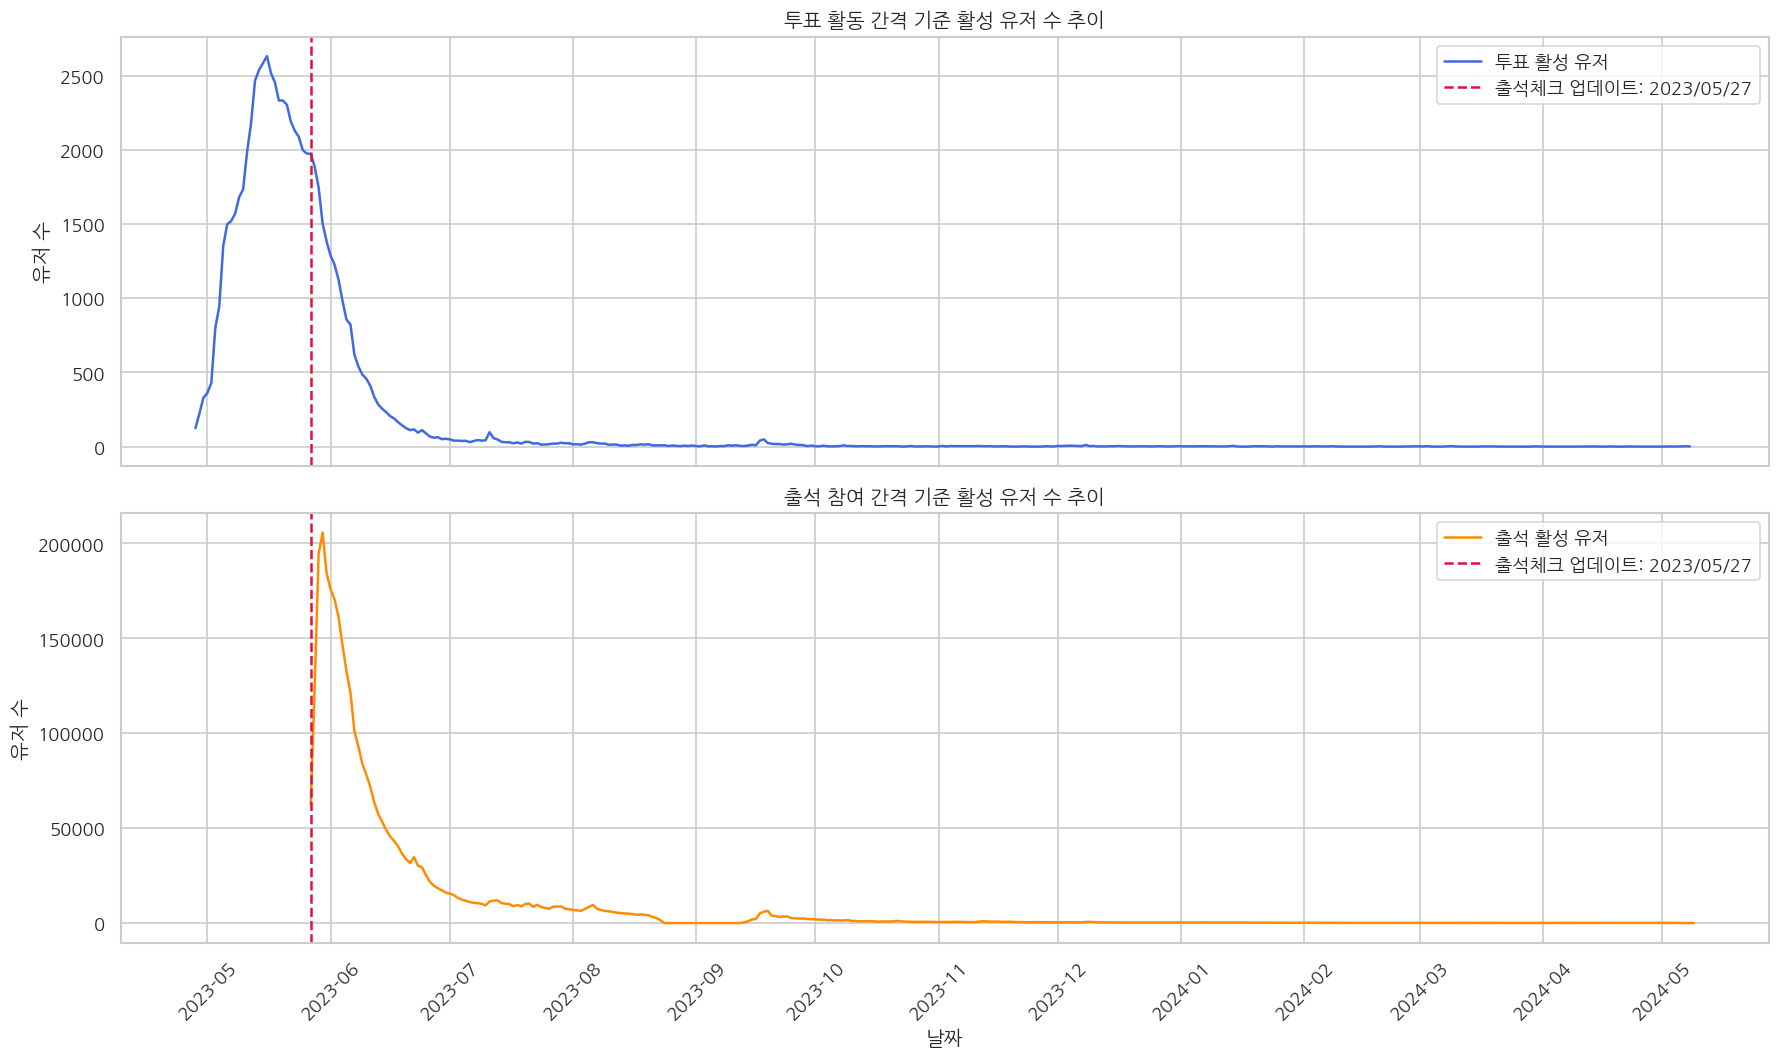

In [321]:
import matplotlib.dates as mdates

# 출석체크 업데이트 기준일
attendance_update_date = pd.Timestamp("2023-05-27")

fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 9),
    sharex=True,
)

# 투표 활성 유저 차트
sns.lineplot(
    data=activity_trend_daily,
    x="analysis_date",
    y="vote_active_users",
    ax=axes[0],
    color="royalblue",
    label="투표 활성 유저",
)

axes[0].axvline(
    attendance_update_date,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label="출석체크 업데이트: 2023/05/27",
)

axes[0].set_title(
    "투표 활동 간격 기준 활성 유저 수 추이"
)
axes[0].set_ylabel("유저 수")
axes[0].legend()

# 출석 활성 유저 차트
sns.lineplot(
    data=activity_trend_daily,
    x="analysis_date",
    y="attendance_active_users",
    ax=axes[1],
    color="darkorange",
    label="출석 활성 유저",
)

axes[1].axvline(
    attendance_update_date,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label="출석체크 업데이트: 2023/05/27",
)

axes[1].set_title(
    "출석 참여 간격 기준 활성 유저 수 추이"
)
axes[1].set_ylabel("유저 수")
axes[1].set_xlabel("날짜")
axes[1].legend()

# 모든 차트의 x축을 1개월 간격으로 표시
for ax in axes:
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


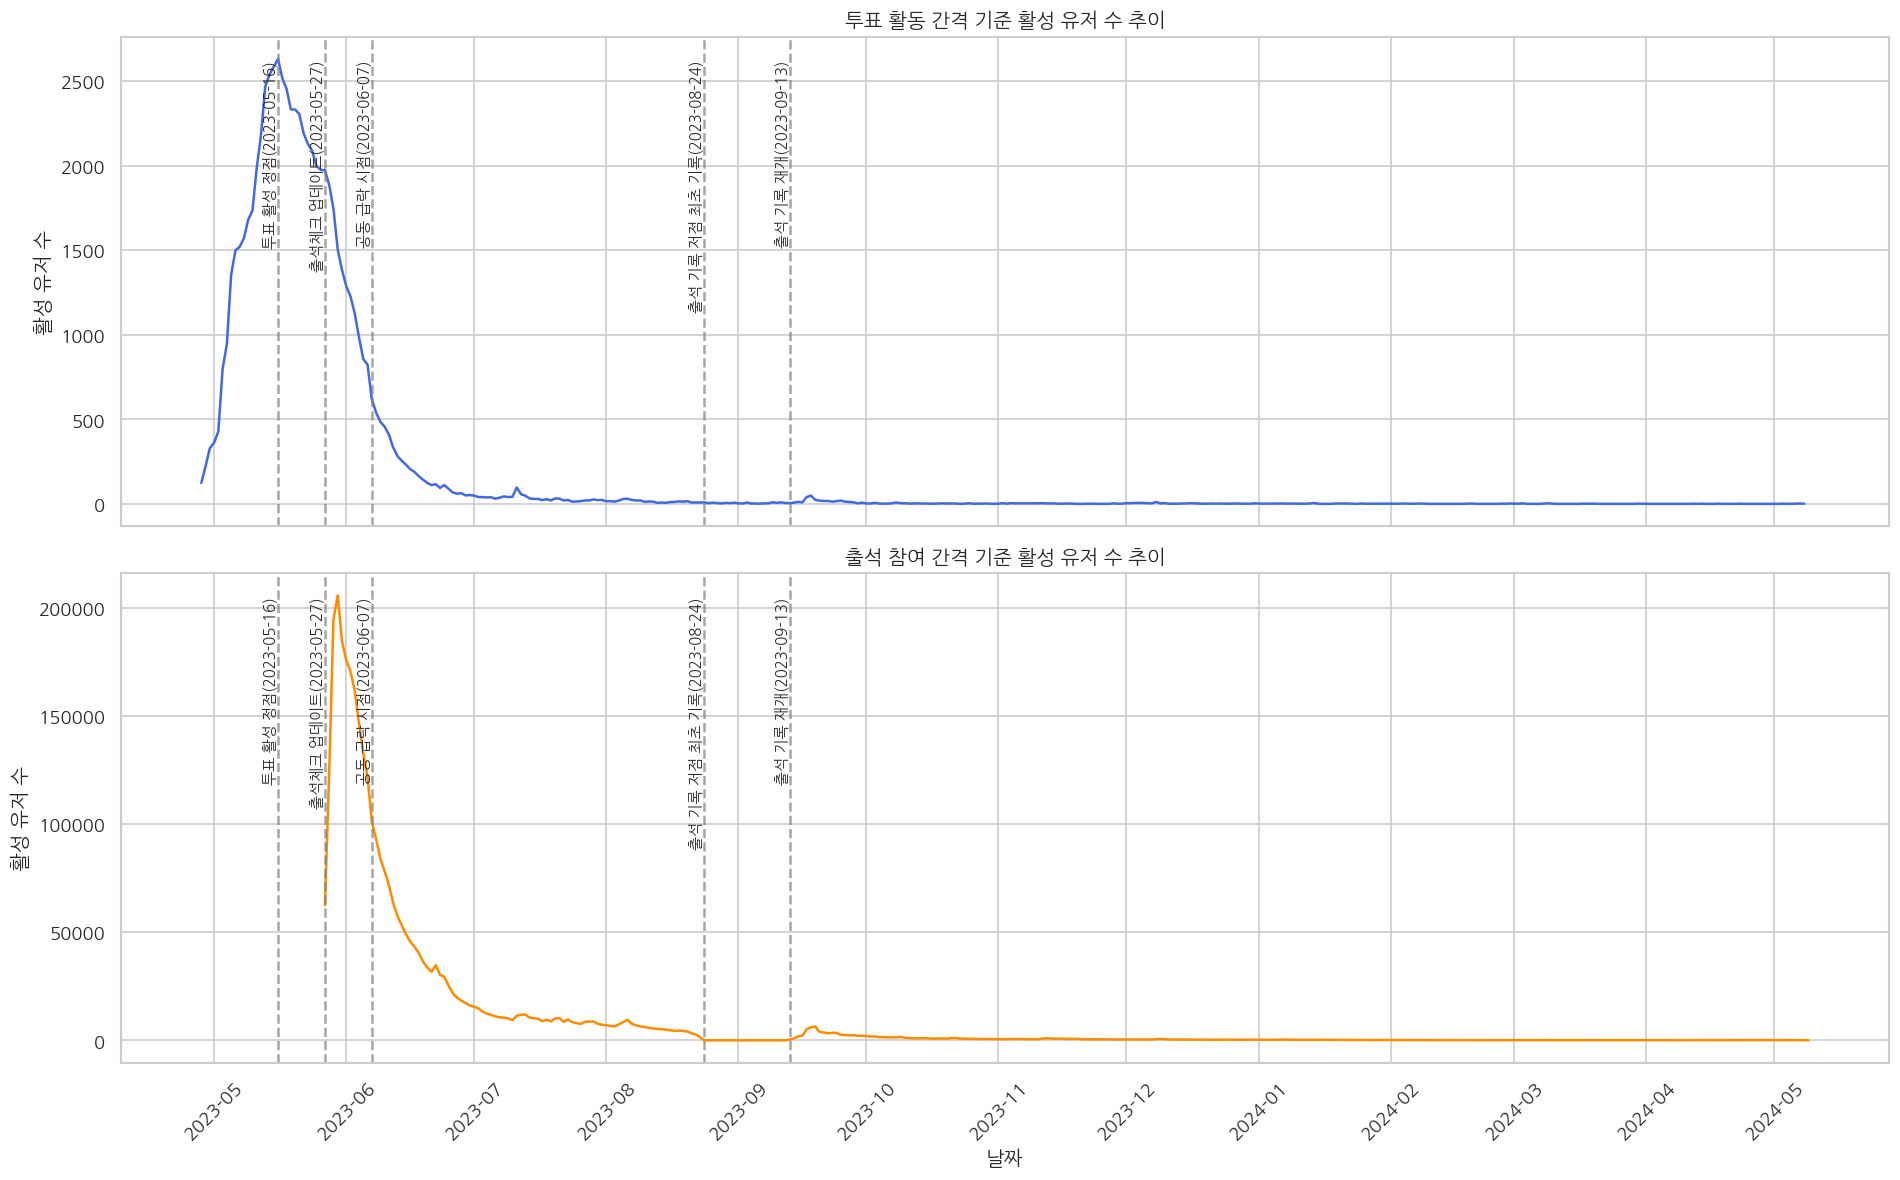

In [322]:
important_dates = {
    "투표 활성 정점(2023-05-16)": "2023-05-16",
    "출석체크 업데이트(2023-05-27)": "2023-05-27",
    "공동 급락 시점(2023-06-07)": "2023-06-07",
    "출석 기록 저점 최초 기록(2023-08-24)": "2023-08-24",
    "출석 기록 재개(2023-09-13)": "2023-09-13",
}

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 10),
    sharex=True
)

chart_info = [
    (
        "vote_active_users",
        "투표 활동 간격 기준 활성 유저 수 추이",
        "royalblue",
    ),
    (
        "attendance_active_users",
        "출석 참여 간격 기준 활성 유저 수 추이",
        "darkorange",
    ),
]

for ax, (metric, title, color) in zip(axes, chart_info):

    sns.lineplot(
        data=activity_trend_daily,
        x="analysis_date",
        y=metric,
        ax=ax,
        color=color,
    )

    for label, date in important_dates.items():
        date = pd.Timestamp(date)

        ax.axvline(
            date,
            color="gray",
            linestyle="--",
            alpha=0.7,
        )

        ax.text(
            date,
            ax.get_ylim()[1] * 0.95,
            label,
            rotation=90,
            va="top",
            ha="right",
            fontsize=9,
        )

    ax.set_title(title)
    ax.set_ylabel("활성 유저 수")

axes[1].set_xlabel("날짜")

axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)
axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 대주제 3. 질문 카테고리별 호기심·추가 행동·수익화 분석

## 분석 목표

질문 카테고리에 따라 투표 완료, 초성 확인, 후속 투표 참여와 결제 경험이 어떻게 달라지는지 확인한다.

## 분석 순서

1. 분석 데이터 준비 및 연결 검증
2. 카테고리별 투표 완료 전환
3. 카테고리별 읽기·초성 확인 행동
4. 수신 후 투표 참여 분석
5. 초성 확인과 후속 결제의 연관성 분석
6. 결과 신뢰성 검증
7. 카테고리별 호기심·하트 소비 기회 종합


## 1. 분석 데이터 준비 및 연결 검증


### 1-1. 최종 분석 파일 불러오기


In [323]:
# 분석 경로 설정
PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "코드잇 3팀 고급 프로젝트"
)
CLEAN_DATA_DIR = f"{PROJECT_DIR}/01_전처리 완료된 csv"
EXTRA_DATA_DIR = f"{PROJECT_DIR}/02_추가_csv"

# 최종 분석 파일 불러오기
category_base = pd.read_csv(
    f"{EXTRA_DATA_DIR}/questions_combined_final.csv"
)
piece_base = pd.read_csv(
    f"{CLEAN_DATA_DIR}/polls_questionpiece_cleaned.csv"
)
vote_base = pd.read_csv(
    f"{CLEAN_DATA_DIR}/accounts_userquestionrecord_updated.csv"
)
payment_base = pd.read_csv(
    f"{CLEAN_DATA_DIR}/accounts_paymenthistory_cleaned.csv"
)

print("카테고리 테이블:", category_base.shape)
print("질문 조각 테이블:", piece_base.shape)
print("투표 기록 테이블:", vote_base.shape)
print("결제 기록 테이블:", payment_base.shape)


카테고리 테이블: (3901, 5)
질문 조각 테이블: (1264349, 5)
투표 기록 테이블: (1213926, 12)
결제 기록 테이블: (94609, 5)


### 1-2. 분석 컬럼과 자료형 정리


In [324]:
# 카테고리 테이블의 분석 컬럼 정리
category_base = category_base[
    [
        "id",
        "question_text",
        "created_at",
        "category",
    ]
].copy()

category_lookup = category_base.rename(
    columns={
        "id": "question_id",
        "created_at": "question_created_at",
    }
).copy()

category_lookup["question_id"] = pd.to_numeric(
    category_lookup["question_id"],
    errors="coerce",
).astype("Int64")
category_lookup["question_created_at"] = pd.to_datetime(
    category_lookup["question_created_at"],
    errors="coerce",
)

# 투표 기록 테이블의 분석 컬럼 정리
vote_base = vote_base[
    [
        "id",
        "question_id",
        "question_piece_id",
        "user_id",
        "chosen_user_id",
        "created_at",
        "has_read",
        "opened_times",
        "status",
        "answer_status",
        "answer_updated_at",
        "report_count",
    ]
].copy()

vote_id_columns = [
    "id",
    "question_id",
    "question_piece_id",
    "user_id",
    "chosen_user_id",
]

for column in vote_id_columns:
    vote_base[column] = pd.to_numeric(
        vote_base[column],
        errors="coerce",
    ).astype("Int64")

for column in ["has_read", "opened_times", "report_count"]:
    vote_base[column] = pd.to_numeric(
        vote_base[column],
        errors="coerce",
    )

vote_base["created_at"] = pd.to_datetime(
    vote_base["created_at"],
    errors="coerce",
)
vote_base["answer_updated_at"] = pd.to_datetime(
    vote_base["answer_updated_at"],
    errors="coerce",
)

# 결제 테이블의 컬럼명과 자료형 정리
if "productId" in payment_base.columns:
    payment_base = payment_base.rename(
        columns={"productId": "product_id"}
    )

payment_base["id"] = pd.to_numeric(
    payment_base["id"],
    errors="coerce",
).astype("Int64")
payment_base["user_id"] = pd.to_numeric(
    payment_base["user_id"],
    errors="coerce",
).astype("Int64")
payment_base["created_at"] = pd.to_datetime(
    payment_base["created_at"],
    errors="coerce",
)


### 1-3. 테이블 기본 품질 확인


In [325]:
# 행 수, 고유 ID, 결측과 중복 확인
table_validation = pd.DataFrame(
    [
        {
            "테이블": "카테고리",
            "전체 행 수": len(category_lookup),
            "고유 ID 수": category_lookup["question_id"].nunique(),
            "ID 결측": category_lookup["question_id"].isna().sum(),
            "ID 중복": category_lookup["question_id"].duplicated().sum(),
        },
        {
            "테이블": "질문 조각",
            "전체 행 수": len(piece_base),
            "고유 ID 수": piece_base["id"].nunique(),
            "ID 결측": piece_base["id"].isna().sum(),
            "ID 중복": piece_base["id"].duplicated().sum(),
        },
        {
            "테이블": "투표 기록",
            "전체 행 수": len(vote_base),
            "고유 ID 수": vote_base["id"].nunique(),
            "ID 결측": vote_base["id"].isna().sum(),
            "ID 중복": vote_base["id"].duplicated().sum(),
        },
        {
            "테이블": "결제 기록",
            "전체 행 수": len(payment_base),
            "고유 ID 수": payment_base["id"].nunique(),
            "ID 결측": payment_base["id"].isna().sum(),
            "ID 중복": payment_base["id"].duplicated().sum(),
        },
    ]
)

display(table_validation)


,테이블,전체 행 수,고유 ID 수,ID 결측,ID 중복
0,카테고리,3901,3901,0,0
1,질문 조각,1264349,1264349,0,0
2,투표 기록,1213926,1213926,0,0
3,결제 기록,94609,94609,0,0


### 1-4. 카테고리와 투표 기록 연결


In [326]:
# question_id를 기준으로 카테고리 연결
vote_category_check = vote_base.merge(
    category_lookup[
        [
            "question_id",
            "question_text",
            "question_created_at",
            "category",
        ]
    ],
    on="question_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

join_validation = pd.Series(
    {
        "전체 투표 기록": len(vote_category_check),
        "카테고리 연결 성공": vote_category_check["_merge"].eq("both").sum(),
        "카테고리 연결 실패": vote_category_check["_merge"].eq("left_only").sum(),
        "카테고리 연결률(%)": vote_category_check["_merge"].eq("both").mean() * 100,
    },
    name="값",
)

display(join_validation.to_frame().round(2))

# 연결되지 않은 질문 ID 확인
unmatched_question_ids = (
    vote_category_check.loc[
        vote_category_check["_merge"].eq("left_only"),
        "question_id",
    ]
    .value_counts(dropna=False)
    .rename_axis("question_id")
    .reset_index(name="행 수")
)

display(unmatched_question_ids)


,값
전체 투표 기록,1213926.0
카테고리 연결 성공,1204228.0
카테고리 연결 실패,9698.0
카테고리 연결률(%),99.2


,question_id,행 수
0,186,9684
1,3956,14


카테고리 연결 실패 기록은 전처리에서 제외한 `vote`, `포인트` 질문인지 확인한 뒤 분석 대상에서 제외한다.


### 1-5. 최종 행동 분석 테이블 생성


In [327]:
# 카테고리가 연결된 투표 기록만 사용
category_behavior_base = (
    vote_category_check.loc[
        vote_category_check["_merge"].eq("both")
    ]
    .drop(columns="_merge")
    .copy()
)

# 읽기와 초성 확인 행동 플래그 생성
category_behavior_base["has_read_flag"] = (
    category_behavior_base["has_read"]
    .map({0: False, 1: True})
    .astype("boolean")
)
category_behavior_base["has_opened_initial"] = (
    category_behavior_base["opened_times"]
    .gt(0)
    .astype("boolean")
)
category_behavior_base["opened_all_initials"] = (
    category_behavior_base["opened_times"]
    .eq(3)
    .astype("boolean")
)

display(
    pd.Series(
        {
            "분석 대상 투표 수신 기록": len(category_behavior_base),
            "고유 수신자 수": category_behavior_base["chosen_user_id"].nunique(),
            "opened_times 범위 밖 기록": (
                ~category_behavior_base["opened_times"].between(0, 3)
                & category_behavior_base["opened_times"].notna()
            ).sum(),
            "읽지 않았지만 초성을 확인한 기록": (
                category_behavior_base["has_read"].eq(0)
                & category_behavior_base["opened_times"].gt(0)
            ).sum(),
        },
        name="값",
    ).to_frame()
)


,값
분석 대상 투표 수신 기록,1204228
고유 수신자 수,15402
opened_times 범위 밖 기록,0
읽지 않았지만 초성을 확인한 기록,0


## 2. 카테고리별 투표 완료 전환


### 2-1. 질문 조각과 실제 투표 완료 기록 비교


In [328]:
# 실제 완료 기록이 존재하는 question_piece_id 확인
voted_piece_ids = vote_base["question_piece_id"].dropna().unique()

piece_vote_check = piece_base[
    ["id", "question_id", "is_voted", "is_skipped"]
].copy()
piece_vote_check["is_voted_flag"] = pd.to_numeric(
    piece_vote_check["is_voted"],
    errors="coerce",
).eq(1)
piece_vote_check["has_vote_record"] = (
    piece_vote_check["id"].isin(voted_piece_ids)
)

# question_id를 기준으로 카테고리 연결
category_by_id = category_base.set_index("id")["category"]
piece_vote_check["category"] = (
    piece_vote_check["question_id"].map(category_by_id)
)
piece_vote_check["flag_only"] = (
    piece_vote_check["is_voted_flag"]
    & ~piece_vote_check["has_vote_record"]
)


### 2-2. 카테고리별 투표 완료율 계산


In [329]:
# 카테고리별 질문 생성 및 투표 완료 집계
category_vote_rate = (
    piece_vote_check.loc[
        piece_vote_check["category"].notna()
    ]
    .groupby("category")
    .agg(
        generated_pieces=("id", "size"),
        confirmed_votes=("has_vote_record", "sum"),
        flagged_votes=("is_voted_flag", "sum"),
        flag_only=("flag_only", "sum"),
    )
    .reset_index()
)

category_vote_rate["confirmed_rate_pct"] = (
    category_vote_rate["confirmed_votes"]
    / category_vote_rate["generated_pieces"]
    * 100
)
category_vote_rate["flagged_rate_pct"] = (
    category_vote_rate["flagged_votes"]
    / category_vote_rate["generated_pieces"]
    * 100
)
category_vote_rate["rate_gap_pp"] = (
    category_vote_rate["flagged_rate_pct"]
    - category_vote_rate["confirmed_rate_pct"]
)

category_vote_rate_display = (
    category_vote_rate.rename(
        columns={
            "category": "질문 카테고리",
            "generated_pieces": "생성된 질문 조각 수",
            "confirmed_votes": "완료 기록이 확인된 투표 수",
            "flagged_votes": "투표 완료 표시 수",
            "flag_only": "완료 표시만 있는 수",
            "confirmed_rate_pct": "실제 완료 기록 기준 투표율(%)",
            "flagged_rate_pct": "투표 완료 표시 기준 투표율(%)",
            "rate_gap_pp": "두 기준의 차이(%p)",
        }
    )
    .sort_values("실제 완료 기록 기준 투표율(%)", ascending=False)
    .round(2)
)

display(category_vote_rate_display)


,질문 카테고리,생성된 질문 조각 수,완료 기록이 확인된 투표 수,투표 완료 표시 수,완료 표시만 있는 수,실제 완료 기록 기준 투표율(%),투표 완료 표시 기준 투표율(%),두 기준의 차이(%p)
1,성격·감정·사회적 태도,272817,263479,264190,711,96.58,96.84,0.26
0,능력·학업·미래,221062,213106,213570,464,96.40,96.61,0.21
2,외적 매력·연애 호감,305735,293020,294165,1145,95.84,96.22,0.37
3,우정·신뢰·관계 친밀도,255472,244544,245618,1074,95.72,96.14,0.42
4,취향·생활습관·상황,199084,190051,190309,258,95.46,95.59,0.13


카테고리별 투표 완료율은 모두 높고 차이가 작아, 카테고리를 구분하는 핵심 지표로 사용하지 않는다.


## 3. 카테고리별 읽기·초성 확인 행동


### 3-1. 카테고리별 수신 행동 퍼널


In [330]:
# 1. 전체 행 수와 고유 투표 수신자 수 확인

print(
    "분석 대상 투표 수신 기록:",
    f"{len(category_behavior_base):,}건",
)

print(
    "고유 수신자 수:",
    f"{category_behavior_base['chosen_user_id'].nunique():,}명",
)


분석 대상 투표 수신 기록: 1,204,228건
고유 수신자 수: 15,402명


In [331]:
# 2. 퍼널 플래그 순차적으로 만들기

# 2-1) 읽은 뒤 초성을 한 글자 이상 확인한 기록(has_read_flag = True & has_opened_initial = True)
category_behavior_base[
    "read_and_opened_initial"
] = (
    category_behavior_base["has_read_flag"]
    .fillna(False) # 결측을 False로 채우기
    &
    category_behavior_base["has_opened_initial"]
    .fillna(False) # 결측을 False로 채우기
)

# 2-2) 읽은 뒤 초성 세 글자를 모두 확인한 기록(has_read_flag = True & opened_all_initials = Ture)
category_behavior_base[
    "read_and_opened_all"
] = (
    category_behavior_base["has_read_flag"]
    .fillna(False) # 결측을 False로 채우기
    &
    category_behavior_base["opened_all_initials"]
    .fillna(False) # 결측을 False로 채우기
)

# 2-3) 읽지 않았다고 표시됐지만 초성이 열렸다고 나타난 비정상 조합 표시(has_read_flag = False & has_opened_initial = True)
category_behavior_base[
    "opened_without_read"
] = (
    category_behavior_base["has_read_flag"]
    .eq(False)
    &
    category_behavior_base["has_opened_initial"]
    .eq(True)
)

# 2-4) 위에서 만든 컬럼의 각각 행 수 표시
funnel_logic_check = pd.Series(
    {
        "전체 수신 기록": (
            len(category_behavior_base)
        ),
        "읽은 기록": (
            category_behavior_base[
                "has_read_flag"
            ].sum()
        ),
        "초성을 1개 이상 확인한 기록": (
            category_behavior_base[
                "has_opened_initial"
            ].sum()
        ),

        "읽은 후 초성을 확인한 기록": (
            category_behavior_base[
                "read_and_opened_initial"
            ].sum()
        ),
        "읽은 후 초성 3개를 모두 확인한 기록": (
            category_behavior_base[
                "read_and_opened_all"
            ].sum()
        ),

        "읽지 않았지만 초성을 확인한 기록": (
            category_behavior_base[
                "opened_without_read"
            ].sum()
        ),
    },
    name="rows",
)

display(
    funnel_logic_check.to_frame()
)


,rows
전체 수신 기록,1204228
읽은 기록,670346
초성을 1개 이상 확인한 기록,56747
읽은 후 초성을 확인한 기록,56747
읽은 후 초성 3개를 모두 확인한 기록,2645
읽지 않았지만 초성을 확인한 기록,0


In [332]:
# 3. 카테고리별로 수신, 읽기, 초성 확인 건수를 집계

category_funnel = (
    category_behavior_base
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        # 해당 카테고리의 전체 투표 수신 기록
        received_records=(
            "id",
            "size",
        ),
        # 해당 카테고리 투표를 받은 고유 사용자
        unique_receivers=(
            "chosen_user_id",
            "nunique",
        ),

        # 결과를 읽은 기록
        read_records=(
            "has_read_flag",
            "sum",
        ),

        # 초성을 확인한 기록
        initial_open_records=(
            "has_opened_initial",
            "sum",
        ),
        # 결과를 읽은 후 초성을 확인한 기록
        read_and_initial_open_records=(
            "read_and_opened_initial",
            "sum",
        ),

        # 초성 3개를 모두 확인한 기록
        all_initial_open_records=(
            "opened_all_initials",
            "sum",
        ),
        # 결과를 읽은 후 초성 3개를 모두 확인한 기록
        read_and_all_initial_open_records=(
            "read_and_opened_all",
            "sum",
        ),

        # 읽지 않았지만 초성을 확인한 기록
        opened_without_read_records=(
            "opened_without_read",
            "sum",
        ),
    )
    .reset_index()
)

display(category_funnel)


,category,received_records,unique_receivers,read_records,initial_open_records,read_and_initial_open_records,all_initial_open_records,read_and_all_initial_open_records,opened_without_read_records
0,능력·학업·미래,213111,11479,113746,5961,5961,144,144,0
1,성격·감정·사회적 태도,263483,11936,144297,9636,9636,283,283,0
2,외적 매력·연애 호감,293029,12109,169077,19150,19150,1113,1113,0
3,우정·신뢰·관계 친밀도,244551,11477,138025,16386,16386,959,959,0
4,취향·생활습관·상황,190054,11328,105201,5614,5614,146,146,0


In [333]:
# 4. 카테고리별 퍼널 전환율 계산

# 함수 생성: 0으로 나누는 오류 방지(분모가 0이면 NaN 반환)
def calculate_rate_pct(numerator, denominator):
    return np.where(
        denominator > 0,
        numerator / denominator * 100,
        np.nan,
    )

# 4-1) 전체 수신 기록 중 결과를 읽은 비율
category_funnel["read_rate_pct"] = (
    calculate_rate_pct(
        category_funnel["read_records"],
        category_funnel["received_records"],
    )
)

# 4-2) 전체 수신 기록 중 초성을 한 글자 이상 확인한 비율(has_read 값과 관계없이 실제 opened_times만 사용)
category_funnel[
    "initial_open_rate_among_all_pct"
] = (
    calculate_rate_pct(
        category_funnel["initial_open_records"],
        category_funnel["received_records"],
    )
)

# 4-3) 읽은 기록 중 초성을 한 글자 이상 확인한 비율(읽기 -> 초성 확인 전환율)
category_funnel[
    "initial_open_rate_among_read_pct"
] = (
    calculate_rate_pct(
        category_funnel[
            "read_and_initial_open_records"
        ],
        category_funnel["read_records"],
    )
)

# 4-4) 전체 수신 기록 중 초성 3개를 모두 확인한 비율
category_funnel[
    "all_initial_open_rate_among_all_pct"
] = (
    calculate_rate_pct(
        category_funnel[
            "all_initial_open_records"
        ],
        category_funnel["received_records"],
    )
)

# 4-5) 초성을 한 글자 이상 확인한 기록 중 초성 3개를 모두 확인한 비율
category_funnel[
    "all_initial_open_rate_among_openers_pct"
] = (
    calculate_rate_pct(
        category_funnel[
            "all_initial_open_records"
        ],
        category_funnel[
            "initial_open_records"
        ],
    )
)


In [334]:
# 5. 카테고리별 전환율을 전체 평균과 비교

# 5-1) 전체 평균 생성
# 전체 행 수
overall_received = len(
    category_behavior_base
)

# 수신한 투표 읽은 여부
overall_read = (
    category_behavior_base[
        "has_read_flag"
    ].sum()
)

# 초성 1개 이상 오픈
overall_initial_open = (
    category_behavior_base[
        "has_opened_initial"
    ].sum()
)

# 초성 3개 모두 오픈
overall_all_initial_open = (
    category_behavior_base[
        "opened_all_initials"
    ].sum()
)

# 전체 평균 전환율 계산
overall_read_rate = (
    overall_read
    / overall_received
    * 100
)
overall_initial_open_rate = (
    overall_initial_open
    / overall_received
    * 100
)
overall_all_initial_open_rate = (
    overall_all_initial_open
    / overall_received
    * 100
)


In [335]:
# 5-2) 전체 평균 전환율 확인

overall_funnel = pd.Series(
    {
        "전체 수신 기록": overall_received,
        "전체 읽기율(%)": (
            overall_read_rate
        ),
        "전체 초성 확인율(%)": (
            overall_initial_open_rate
        ),
        "전체 초성 3개 확인율(%)": (
            overall_all_initial_open_rate
        ),
    },
    name="value",
)

display(
    overall_funnel
    .to_frame()
    .round(2)
)


,value
전체 수신 기록,1204228.00
전체 읽기율(%),55.67
전체 초성 확인율(%),4.71
전체 초성 3개 확인율(%),0.22


In [336]:
# 5-3) 카테고리별 전환율과 전체 평균의 차이

# 수신한 투표 읽은 여부
category_funnel["read_rate_gap_pp"] = (
    category_funnel["read_rate_pct"]
    - overall_read_rate
)

# 초성 1개 이상 오픈
category_funnel["initial_open_rate_gap_pp"] = (
    category_funnel[
        "initial_open_rate_among_all_pct"
    ]
    - overall_initial_open_rate
)

# 초성 3개 모두 오픈
category_funnel[
    "all_initial_open_rate_gap_pp"
] = (
    category_funnel[
        "all_initial_open_rate_among_all_pct"
    ]
    - overall_all_initial_open_rate
)


In [337]:
# 6. 퍼널 결과표 생성

category_funnel_result = (
    category_funnel[
        [
            "category",
            "received_records",
            "unique_receivers",
            "read_records",
            "initial_open_records",
            "all_initial_open_records",
            "read_rate_pct",
            "initial_open_rate_among_all_pct",
            "initial_open_rate_among_read_pct",
            "all_initial_open_rate_among_all_pct",
            "all_initial_open_rate_among_openers_pct",
            "read_rate_gap_pp",
            "initial_open_rate_gap_pp",
            "all_initial_open_rate_gap_pp",
            "opened_without_read_records",
        ]
    ]
    .sort_values(
        "initial_open_rate_among_all_pct", # 초성 확인율이 높은 카테고리 순으로 정렬
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    category_funnel_result.round(2)
)


,category,received_records,unique_receivers,read_records,initial_open_records,all_initial_open_records,read_rate_pct,initial_open_rate_among_all_pct,initial_open_rate_among_read_pct,all_initial_open_rate_among_all_pct,all_initial_open_rate_among_openers_pct,read_rate_gap_pp,initial_open_rate_gap_pp,all_initial_open_rate_gap_pp,opened_without_read_records
0,우정·신뢰·관계 친밀도,244551,11477,138025,16386,959,56.44,6.70,11.87,0.39,5.85,0.77,1.99,0.17,0
1,외적 매력·연애 호감,293029,12109,169077,19150,1113,57.70,6.54,11.33,0.38,5.81,2.03,1.82,0.16,0
2,성격·감정·사회적 태도,263483,11936,144297,9636,283,54.77,3.66,6.68,0.11,2.94,-0.90,-1.06,-0.11,0
3,취향·생활습관·상황,190054,11328,105201,5614,146,55.35,2.95,5.34,0.08,2.60,-0.31,-1.76,-0.14,0
4,능력·학업·미래,213111,11479,113746,5961,144,53.37,2.80,5.24,0.07,2.42,-2.29,-1.92,-0.15,0


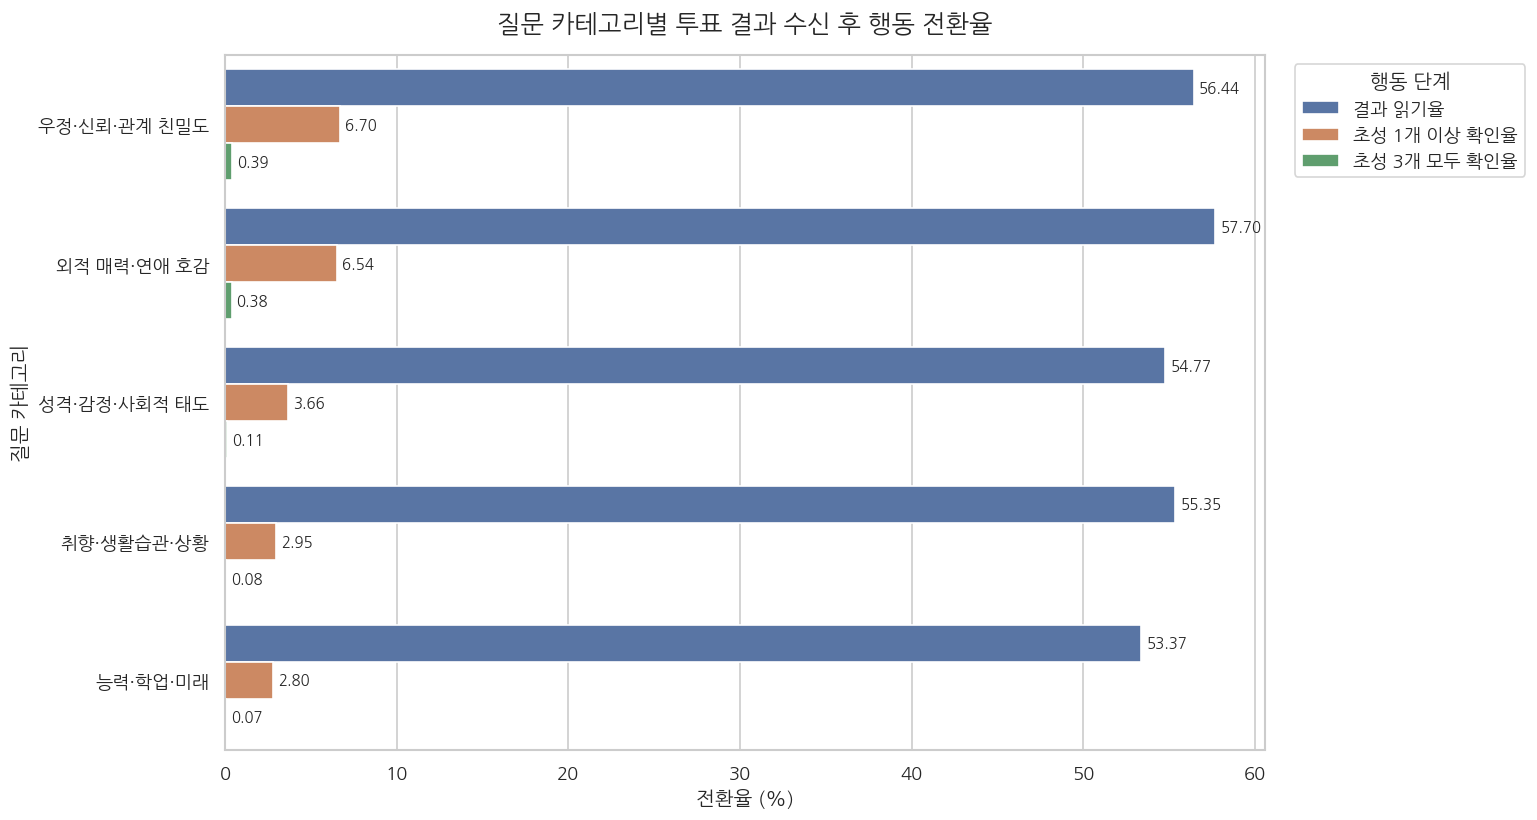

In [338]:
# 7. 카테고리별 퍼널 차트 생성

# 차트 기본 스타일 설정
sns.set_theme(
    style="whitegrid",
    font="NanumGothic",
)
plt.rcParams["axes.unicode_minus"] = False

# 차트에 사용할 전환율 컬럼을 긴 형태로 변환
funnel_chart_data = (
    category_funnel_result[
        [
            "category",
            "read_rate_pct",
            "initial_open_rate_among_all_pct",
            "all_initial_open_rate_among_all_pct",
        ]
    ]
    .melt(
        id_vars="category",
        var_name="metric",
        value_name="rate_pct",
    )
)

# 영문 컬럼명을 차트에서 사용할 한글 이름으로 변경
metric_name_map = {
    "read_rate_pct": "결과 읽기율",
    "initial_open_rate_among_all_pct": "초성 1개 이상 확인율",
    "all_initial_open_rate_among_all_pct": "초성 3개 모두 확인율",
}

funnel_chart_data["metric"] = (
    funnel_chart_data["metric"]
    .map(metric_name_map)
)

# 초성 확인율이 높은 순서로 카테고리 정렬
category_order = (
    category_funnel_result[
        "category"
    ].tolist()
)

# 시각화
plt.figure(figsize=(13, 7))
ax = sns.barplot(
    data=funnel_chart_data,
    y="category",
    x="rate_pct",
    hue="metric",
    order=category_order,
)

# 막대 위에 비율 표시
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9,
    )

plt.title(
    "질문 카테고리별 투표 결과 수신 후 행동 전환율",
    fontsize=15,
    pad=15,
)
plt.xlabel("전환율 (%)")
plt.ylabel("질문 카테고리")
plt.legend(
    title="행동 단계",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()

plt.show()


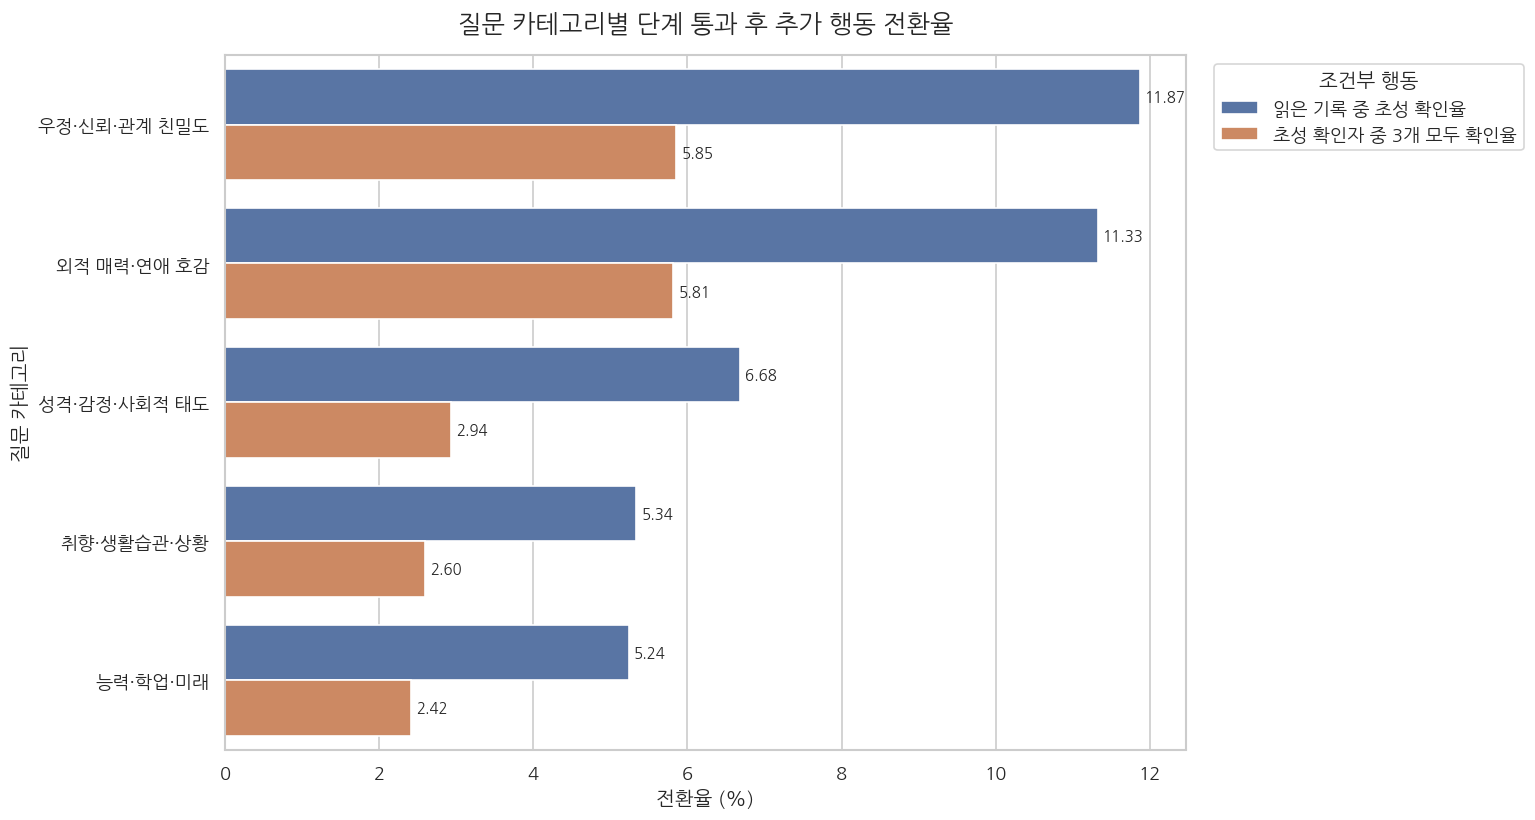

In [339]:
# 8. 읽은 후 초성 확인율과 초성 확인 후 3개 초성 전부 확인율 차트

conditional_chart_data = (
    category_funnel_result[
        [
            "category",
            "initial_open_rate_among_read_pct",
            "all_initial_open_rate_among_openers_pct",
        ]
    ]
    .melt(
        id_vars="category",
        var_name="metric",
        value_name="rate_pct",
    )
)

# 차트 표시용 이름 지정
conditional_metric_name_map = {
    "initial_open_rate_among_read_pct": (
        "읽은 기록 중 초성 확인율"
    ),
    "all_initial_open_rate_among_openers_pct": (
        "초성 확인자 중 3개 모두 확인율"
    ),
}

conditional_chart_data["metric"] = (
    conditional_chart_data["metric"]
    .map(conditional_metric_name_map)
)

# 시각화
plt.figure(figsize=(13, 7))
ax = sns.barplot(
    data=conditional_chart_data,
    y="category",
    x="rate_pct",
    hue="metric",
    order=category_order,
)

# 막대 위에 비율 표시
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9,
    )

plt.title(
    "질문 카테고리별 단계 통과 후 추가 행동 전환율",
    fontsize=15,
    pad=15,
)
plt.xlabel("전환율 (%)")
plt.ylabel("질문 카테고리")
plt.legend(
    title="조건부 행동",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()

plt.show()


In [340]:
# 사용자별 수신 횟수 차이를 고려한 초성 확인율 계산
# 카테고리별 사용자 동일 가중치 결과를 함께 확인

# 카테고리-수신자 단위로 행동 집계
receiver_category_behavior = (
    category_behavior_base
    .groupby(
        [
            "category",
            "chosen_user_id",
        ],
        observed=True,
    )
    .agg(
        received_records=(
            "id",
            "size",
        ),

        read_records=(
            "has_read_flag",
            "sum",
        ),

        initial_open_records=(
            "has_opened_initial",
            "sum",
        ),

        all_initial_open_records=(
            "opened_all_initials",
            "sum",
        ),
    )
    .reset_index()
)

# 사용자별 카테고리 행동률 계산
receiver_category_behavior[
    "personal_read_rate_pct"
] = (
    receiver_category_behavior["read_records"]
    / receiver_category_behavior["received_records"]
    * 100
)

receiver_category_behavior[
    "personal_initial_open_rate_pct"
] = (
    receiver_category_behavior[
        "initial_open_records"
    ]
    / receiver_category_behavior[
        "received_records"
    ]
    * 100
)

receiver_category_behavior[
    "personal_all_initial_open_rate_pct"
] = (
    receiver_category_behavior[
        "all_initial_open_records"
    ]
    / receiver_category_behavior[
        "received_records"
    ]
    * 100
)

# 카테고리별 사용자 평균·중앙 행동률 계산: 투표를 많이 받은 사용자와 적게 받은 사용자에게 동일한 가중치를 부여
receiver_weighted_summary = (
    receiver_category_behavior
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        receivers=(
            "chosen_user_id",
            "nunique",
        ),

        median_received_records=(
            "received_records",
            "median",
        ),

        mean_personal_read_rate_pct=(
            "personal_read_rate_pct",
            "mean",
        ),

        mean_personal_initial_open_rate_pct=(
            "personal_initial_open_rate_pct",
            "mean",
        ),

        median_personal_initial_open_rate_pct=(
            "personal_initial_open_rate_pct",
            "median",
        ),

        mean_personal_all_initial_open_rate_pct=(
            "personal_all_initial_open_rate_pct",
            "mean",
        ),
    )
    .sort_values(
        "mean_personal_initial_open_rate_pct",
        ascending=False,
    )
    .reset_index()
)

display(
    receiver_weighted_summary.round(2)
)


,category,receivers,median_received_records,mean_personal_read_rate_pct,mean_personal_initial_open_rate_pct,median_personal_initial_open_rate_pct,mean_personal_all_initial_open_rate_pct
0,우정·신뢰·관계 친밀도,11477,8.0,57.76,7.92,0.0,0.4
1,외적 매력·연애 호감,12109,7.0,58.61,7.42,0.0,0.35
2,성격·감정·사회적 태도,11936,7.0,56.7,4.53,0.0,0.15
3,능력·학업·미래,11479,6.0,55.49,3.84,0.0,0.09
4,취향·생활습관·상황,11328,6.0,54.44,3.74,0.0,0.09


In [341]:
# 기록 기준 결과에서 필요한 컬럼 선택
record_weighted_result = (
    category_funnel_result[
        [
            "category",
            "received_records",
            "initial_open_rate_among_all_pct",
        ]
    ]
    .rename(
        columns={
            "initial_open_rate_among_all_pct": (
                "record_weighted_open_rate_pct"
            )
        }
    )
)

# 사용자 동일 가중치 결과에서 필요한 컬럼 선택
user_weighted_result = (
    receiver_weighted_summary[
        [
            "category",
            "receivers",
            "median_received_records",
            "mean_personal_initial_open_rate_pct",
        ]
    ]
    .rename(
        columns={
            "mean_personal_initial_open_rate_pct": (
                "user_equal_weight_open_rate_pct"
            )
        }
    )
)

# 카테고리를 기준으로 두 결과를 연결(validate="one_to_one": 각 카테고리가 양쪽 테이블에 한 행씩만 있는지 확인)
weight_comparison = (
    record_weighted_result
    .merge(
        user_weighted_result,
        on="category",
        how="inner",
        validate="one_to_one",
    )
)

# 기록 기준과 사용자 동일 가중치 기준의 차이 계산
# 양수: 기록 기준 비율이 더 높음 → 많은 기록을 가진 사용자가 확인율을 끌어올렸을 가능성
# 음수: 사용자 동일 가중치 비율이 더 높음 → 많은 기록을 가진 사용자의 확인율이 오히려 낮을 가능성
weight_comparison["rate_gap_pp"] = (
    weight_comparison[
        "record_weighted_open_rate_pct"
    ]
    -
    weight_comparison[
        "user_equal_weight_open_rate_pct"
    ]
)

# 기록 기준 초성 확인율이 높은 순서로 정렬
weight_comparison = (
    weight_comparison
    .sort_values(
        "record_weighted_open_rate_pct",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    weight_comparison.round(2)
)


,category,received_records,record_weighted_open_rate_pct,receivers,median_received_records,user_equal_weight_open_rate_pct,rate_gap_pp
0,우정·신뢰·관계 친밀도,244551,6.70,11477,8.0,7.92,-1.22
1,외적 매력·연애 호감,293029,6.54,12109,7.0,7.42,-0.89
2,성격·감정·사회적 태도,263483,3.66,11936,7.0,4.53,-0.87
3,취향·생활습관·상황,190054,2.95,11328,6.0,3.74,-0.78
4,능력·학업·미래,213111,2.80,11479,6.0,3.84,-1.04


In [342]:
# 기록 기준과 사용자 동일 가중치 기준을 하나의 rate_type 컬럼으로 모음
weight_chart_data = (
    weight_comparison[
        [
            "category",
            "record_weighted_open_rate_pct",
            "user_equal_weight_open_rate_pct",
        ]
    ]
    .melt(
        id_vars="category",
        var_name="rate_type",
        value_name="open_rate_pct",
    )
)

# 차트 범례에 사용할 한글 이름으로 변경
rate_type_name_map = {
    "record_weighted_open_rate_pct": (
        "기록 기준 초성 확인율"
    ),
    "user_equal_weight_open_rate_pct": (
        "사용자 동일 가중치 초성 확인율"
    ),
}

weight_chart_data["rate_type"] = (
    weight_chart_data["rate_type"]
    .map(rate_type_name_map)
)


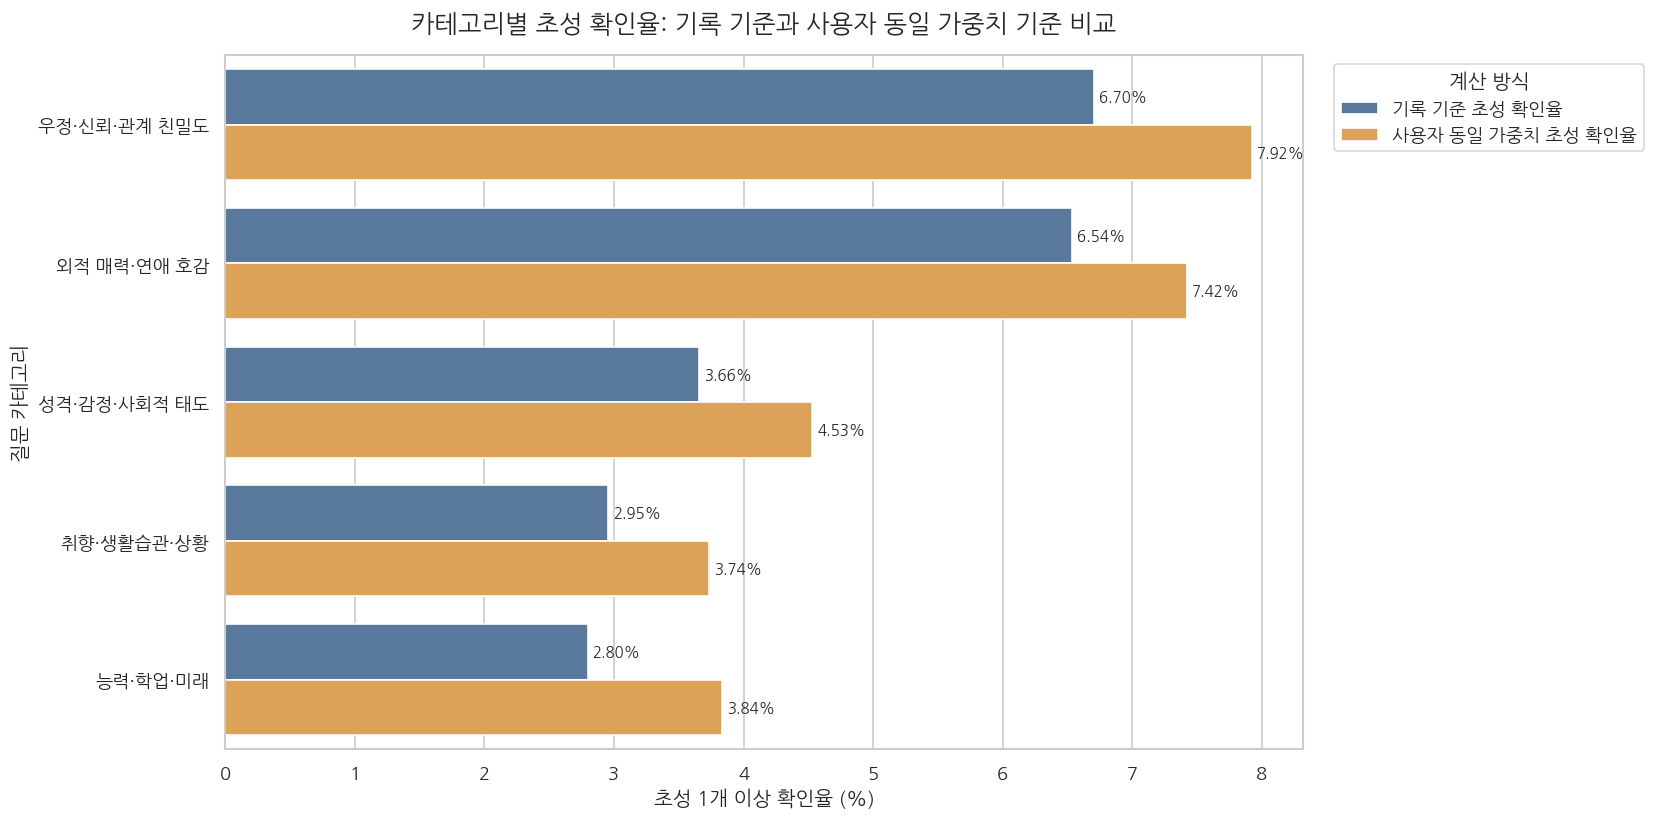

In [343]:
# 기록 기준 초성 확인율이 높은 순서로 표시
category_order = (
    weight_comparison["category"]
    .tolist()
)

# 두 계산 방식에 사용할 색상 지정
weight_palette = {
    "기록 기준 초성 확인율": "#4C78A8",
    "사용자 동일 가중치 초성 확인율": "#F2A541",
}

# 카테고리별 두 초성 확인율을 나란히 표시
plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=weight_chart_data,
    y="category",
    x="open_rate_pct",
    hue="rate_type",
    order=category_order,
    palette=weight_palette,
    errorbar=None,
)

# 각 막대 끝에 정확한 비율 표시
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9,
    )

plt.title(
    "카테고리별 초성 확인율: 기록 기준과 사용자 동일 가중치 기준 비교",
    fontsize=15,
    pad=15,
)
plt.xlabel("초성 1개 이상 확인율 (%)")
plt.ylabel("질문 카테고리")
plt.legend(
    title="계산 방식",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()

plt.show()


### 3-2. 실제 초성 확인 개수와 전체 기여도


In [344]:
# 카테고리별 하트 소비 수요 분석용 데이터 생성

category_spend_base = (
    category_behavior_base.copy()
)

# 초성 확인 횟수를 숫자형으로 변환

category_spend_base["opened_times_clean"] = (
    pd.to_numeric(
        category_spend_base["opened_times"],
        errors="coerce",
    )
)

# 정상 범위는 0~3
# 범위를 벗어난 값은 분석에서 사용할 수 없도록 결측 처리

valid_opened_times = (
    category_spend_base[
        "opened_times_clean"
    ].between(0, 3)
)

# 데이터 검증 결과

opened_times_validation = pd.DataFrame(
    {
        "검증 항목": [
            "전체 수신 기록",
            "초성 확인 횟수 결측",
            "0~3 범위 정상 기록",
            "0 미만 기록",
            "3 초과 기록",
        ],
        "기록 수(건)": [
            len(category_spend_base),

            category_spend_base[
                "opened_times_clean"
            ].isna().sum(),

            valid_opened_times.sum(),

            category_spend_base[
                "opened_times_clean"
            ].lt(0).sum(),

            category_spend_base[
                "opened_times_clean"
            ].gt(3).sum(),
        ],
    }
)

display(opened_times_validation)


,검증 항목,기록 수(건)
0,전체 수신 기록,1204228
1,초성 확인 횟수 결측,0
2,0~3 범위 정상 기록,1204228
3,0 미만 기록,0
4,3 초과 기록,0


In [345]:
# 정상적인 opened_times가 있는 행만 사용

category_spend_analysis = (
    category_spend_base.loc[
        valid_opened_times
    ]
    .copy()
)

# 초성을 한 개 이상 확인했는지 여부

category_spend_analysis[
    "초성_확인_여부"
] = (
    category_spend_analysis[
        "opened_times_clean"
    ].gt(0)
)

# 초성 3개를 모두 확인했는지 여부

category_spend_analysis[
    "초성_전체_확인_여부"
] = (
    category_spend_analysis[
        "opened_times_clean"
    ].eq(3)
)

# 초성을 확인한 사용자만 ID를 남김
# 카테고리별 고유 초성 확인자 수를 계산할 때 사용

category_spend_analysis[
    "초성_확인자_id"
] = (
    category_spend_analysis[
        "chosen_user_id"
    ].where(
        category_spend_analysis[
            "초성_확인_여부"
        ]
    )
)


In [346]:
# 카테고리별 수신량과 초성 확인 행동 계산

category_spend_summary = (
    category_spend_analysis
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        receipt_records=(
            "id",
            "size",
        ),

        unique_receivers=(
            "chosen_user_id",
            "nunique",
        ),

        opened_records=(
            "초성_확인_여부",
            "sum",
        ),

        unique_openers=(
            "초성_확인자_id",
            "nunique",
        ),

        total_opened_initials=(
            "opened_times_clean",
            "sum",
        ),

        fully_opened_records=(
            "초성_전체_확인_여부",
            "sum",
        ),
    )
    .reset_index()
)


In [347]:
# 전체 수신 기록 중 초성을 한 개 이상 확인한 비율

category_spend_summary[
    "opened_record_rate_pct"
] = (
    category_spend_summary[
        "opened_records"
    ]
    / category_spend_summary[
        "receipt_records"
    ]
    * 100
)

# 고유 수신자 중 한 번이라도 초성을 확인한 사용자 비율

category_spend_summary[
    "unique_opener_rate_pct"
] = (
    category_spend_summary[
        "unique_openers"
    ]
    / category_spend_summary[
        "unique_receivers"
    ]
    * 100
)

# 수신 100건당 실제로 확인된 초성 개수
# 카테고리별 하트 소비 수요의 핵심 지표

category_spend_summary[
    "opened_initials_per_100_receipts"
] = (
    category_spend_summary[
        "total_opened_initials"
    ]
    / category_spend_summary[
        "receipt_records"
    ]
    * 100
)

# 초성을 확인한 기록 한 건당 평균 몇 개를 확인했는지

category_spend_summary[
    "mean_initials_per_opened_record"
] = (
    category_spend_summary[
        "total_opened_initials"
    ]
    / category_spend_summary[
        "opened_records"
    ]
)

# 초성 확인자 한 명당 누적 확인 개수

category_spend_summary[
    "mean_initials_per_opener"
] = (
    category_spend_summary[
        "total_opened_initials"
    ]
    / category_spend_summary[
        "unique_openers"
    ]
)

# 전체 수신 기록 중 초성 3개를 모두 확인한 비율

category_spend_summary[
    "fully_opened_record_rate_pct"
] = (
    category_spend_summary[
        "fully_opened_records"
    ]
    / category_spend_summary[
        "receipt_records"
    ]
    * 100
)

# 전체 초성 확인 횟수에서 해당 카테고리가 차지하는 비중
# 카테고리의 규모와 소비 효율이 함께 반영됨

category_spend_summary[
    "opened_initial_share_pct"
] = (
    category_spend_summary[
        "total_opened_initials"
    ]
    / category_spend_summary[
        "total_opened_initials"
    ].sum()
    * 100
)


In [348]:
# 출력용 표 생성

category_spend_display = (
    category_spend_summary
    .rename(
        columns={
            "category":
                "질문 카테고리",
            "receipt_records":
                "수신 기록 수(건)",
            "unique_receivers":
                "고유 수신자 수(명)",
            "opened_records":
                "초성 확인 기록 수(건)",
            "unique_openers":
                "고유 초성 확인자 수(명)",
            "total_opened_initials":
                "총 초성 확인 개수(개)",
            "opened_record_rate_pct":
                "수신 기록 기준 초성 확인율(%)",
            "unique_opener_rate_pct":
                "고유 수신자 기준 초성 확인율(%)",
            "opened_initials_per_100_receipts":
                "수신 100건당 초성 확인 개수(개)",
            "mean_initials_per_opened_record":
                "초성 확인 기록당 평균 확인 개수(개)",
            "mean_initials_per_opener":
                "초성 확인자당 평균 확인 개수(개)",
            "fully_opened_record_rate_pct":
                "초성 3개 전체 확인율(%)",
            "opened_initial_share_pct":
                "전체 초성 확인 중 비중(%)",
        }
    )
    [
        [
            "질문 카테고리",
            "수신 기록 수(건)",
            "고유 수신자 수(명)",
            "초성 확인 기록 수(건)",
            "고유 초성 확인자 수(명)",
            "총 초성 확인 개수(개)",
            "수신 기록 기준 초성 확인율(%)",
            "고유 수신자 기준 초성 확인율(%)",
            "수신 100건당 초성 확인 개수(개)",
            "초성 확인 기록당 평균 확인 개수(개)",
            "초성 확인자당 평균 확인 개수(개)",
            "초성 3개 전체 확인율(%)",
            "전체 초성 확인 중 비중(%)",
        ]
    ]
    .sort_values(
        "수신 100건당 초성 확인 개수(개)",
        ascending=False,
    )
    .round(2)
)

print("질문 카테고리별 초성 확인 및 하트 소비 수요")

display(category_spend_display)


질문 카테고리별 초성 확인 및 하트 소비 수요


,질문 카테고리,수신 기록 수(건),고유 수신자 수(명),초성 확인 기록 수(건),고유 초성 확인자 수(명),총 초성 확인 개수(개),수신 기록 기준 초성 확인율(%),고유 수신자 기준 초성 확인율(%),수신 100건당 초성 확인 개수(개),초성 확인 기록당 평균 확인 개수(개),초성 확인자당 평균 확인 개수(개),초성 3개 전체 확인율(%),전체 초성 확인 중 비중(%)
3,우정·신뢰·관계 친밀도,244551,11477,16386,4985,21886,6.7,43.43,8.95,1.34,4.39,0.39,29.93
2,외적 매력·연애 호감,293029,12109,19150,5206,25720,6.54,42.99,8.78,1.34,4.94,0.38,35.18
1,성격·감정·사회적 태도,263483,11936,9636,3868,11645,3.66,32.41,4.42,1.21,3.01,0.11,15.93
4,취향·생활습관·상황,190054,11328,5614,2844,6736,2.95,25.11,3.54,1.20,2.37,0.08,9.21
0,능력·학업·미래,213111,11479,5961,2953,7126,2.8,25.73,3.34,1.20,2.41,0.07,9.75


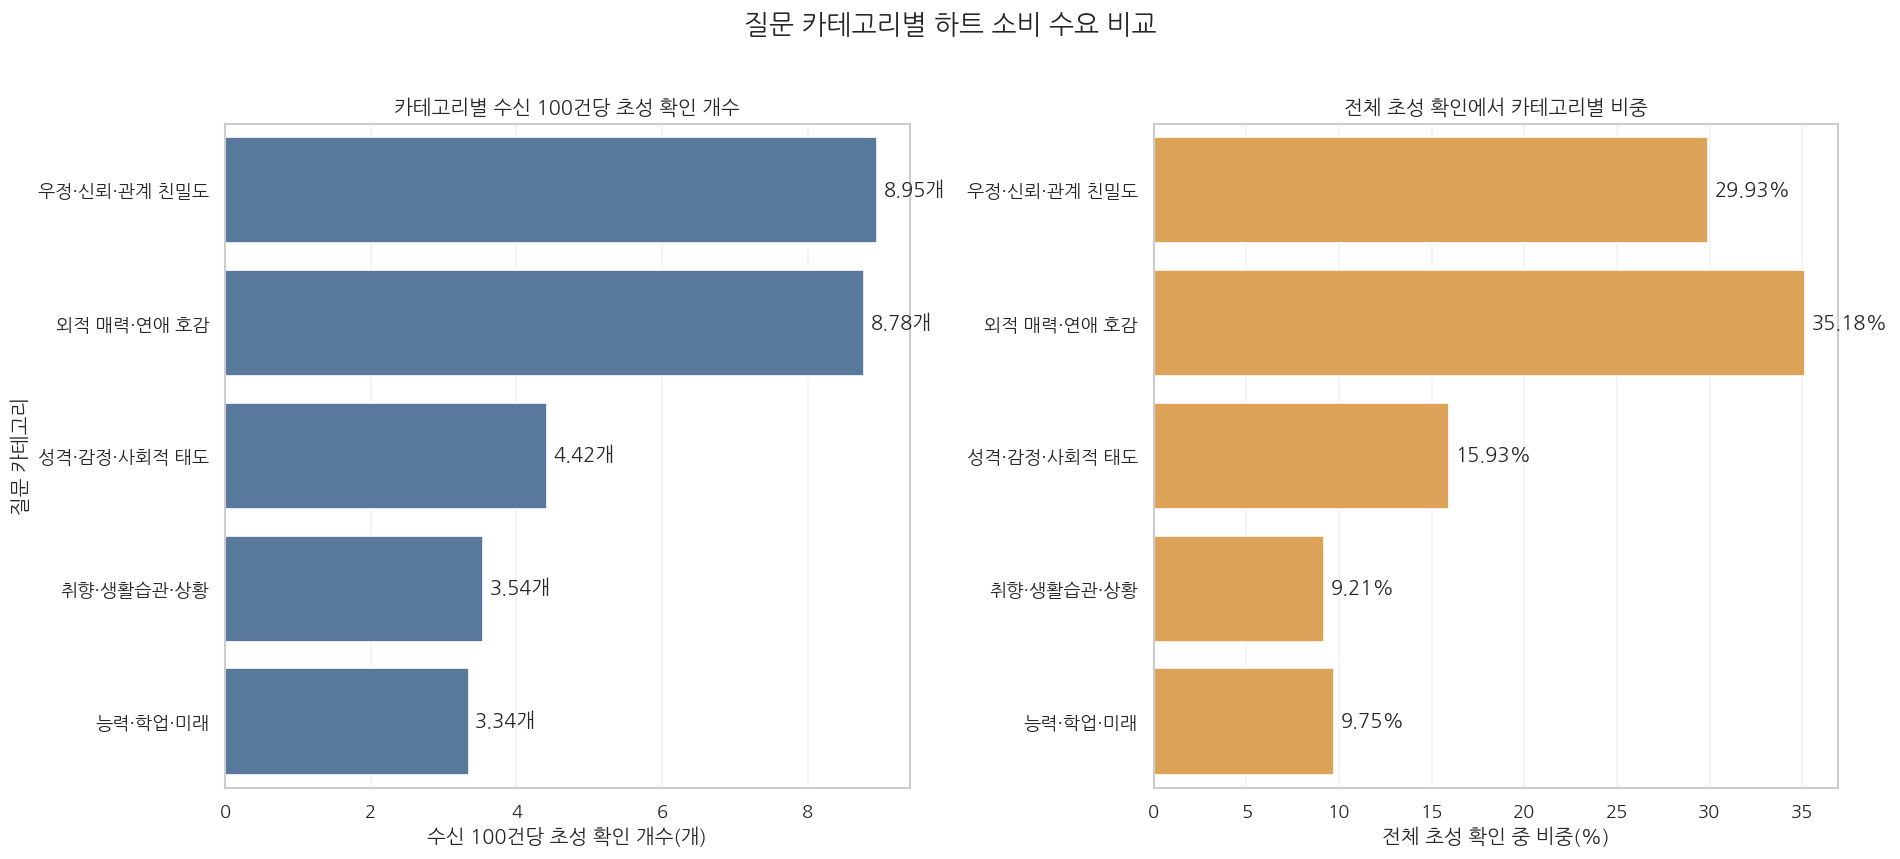

In [349]:
# 카테고리 표시 순서
# 수신 100건당 초성 확인 개수가 높은 순서

category_order = (
    category_spend_summary
    .sort_values(
        "opened_initials_per_100_receipts",
        ascending=False,
    )["category"]
    .tolist()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7),
)

# 왼쪽: 수신량을 보정한 초성 소비 수요

sns.barplot(
    data=category_spend_summary,
    y="category",
    x="opened_initials_per_100_receipts",
    order=category_order,
    color="#4C78A8",
    ax=axes[0],
)

axes[0].set_title(
    "카테고리별 수신 100건당 초성 확인 개수"
)
axes[0].set_xlabel(
    "수신 100건당 초성 확인 개수(개)"
)
axes[0].set_ylabel("질문 카테고리")

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.2f개",
        padding=4,
    )

# 오른쪽: 전체 초성 확인 중 카테고리별 비중

sns.barplot(
    data=category_spend_summary,
    y="category",
    x="opened_initial_share_pct",
    order=category_order,
    color="#F2A541",
    ax=axes[1],
)

axes[1].set_title(
    "전체 초성 확인에서 카테고리별 비중"
)
axes[1].set_xlabel(
    "전체 초성 확인 중 비중(%)"
)
axes[1].set_ylabel("")

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f%%",
        padding=4,
    )

for ax in axes:
    ax.grid(
        axis="x",
        alpha=0.25,
    )

fig.suptitle(
    "질문 카테고리별 하트 소비 수요 비교",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()
plt.show()


## 4. 수신 후 투표 참여 분석


질문을 수신한 사용자가 이후 1일·3일·7일 안에 직접 투표를 완료했는지 확인한다. 동일 사용자의 반복 수신 영향을 확인하기 위해 기록 기준과 사용자 동일 가중치 기준을 함께 비교한다.


### 4-1. 수신 기록과 투표 완료 기록 준비


In [350]:
# 카테고리가 연결된 투표 결과 수신 기록
receipt_vote_base = (
    category_behavior_base[
        [
            "id",
            "chosen_user_id",
            "created_at",
            "category",
        ]
    ]
    .rename(
        columns={
            "id": "receipt_record_id",
            "chosen_user_id": "user_id",
            "created_at": "receipt_at",
        }
    )
    .dropna(
        subset=[
            "user_id",
            "receipt_at",
            "category",
        ]
    )
    .copy()
)

# 사용자가 직접 완료한 투표 기록
future_vote_events = (
    vote_base[
        [
            "id",
            "user_id",
            "created_at",
        ]
    ]
    .rename(
        columns={
            "id": "next_vote_record_id",
            "created_at": "next_vote_at",
        }
    )
    .dropna(
        subset=[
            "user_id",
            "next_vote_at",
        ]
    )
    .drop_duplicates("next_vote_record_id")
    .copy()
)

# 사용자 ID와 시간 자료형 통일
receipt_vote_base["user_id"] = pd.to_numeric(
    receipt_vote_base["user_id"],
    errors="coerce",
).astype("Int64")
future_vote_events["user_id"] = pd.to_numeric(
    future_vote_events["user_id"],
    errors="coerce",
).astype("Int64")

receipt_vote_base["receipt_at"] = pd.to_datetime(
    receipt_vote_base["receipt_at"],
    errors="coerce",
)
future_vote_events["next_vote_at"] = pd.to_datetime(
    future_vote_events["next_vote_at"],
    errors="coerce",
)

display(
    pd.Series(
        {
            "분석 대상 수신 기록 수": len(receipt_vote_base),
            "고유 수신자 수": receipt_vote_base["user_id"].nunique(),
            "전체 투표 완료 기록 수": len(future_vote_events),
            "고유 투표자 수": future_vote_events["user_id"].nunique(),
        },
        name="값",
    ).to_frame()
)


,값
분석 대상 수신 기록 수,1204228
고유 수신자 수,15402
전체 투표 완료 기록 수,1213926
고유 투표자 수,4849


### 4-2. 각 수신 기록 이후의 다음 투표 시각 연결


In [351]:
# merge_asof 사용을 위해 시간 기준으로 정렬
receipt_vote_sorted = receipt_vote_base.sort_values(
    ["receipt_at", "user_id"]
).copy()
future_vote_sorted = future_vote_events.sort_values(
    ["next_vote_at", "user_id"]
).copy()

# 동일 사용자가 수신 시점 이후 가장 먼저 완료한 투표 연결
receipt_next_vote = pd.merge_asof(
    receipt_vote_sorted,
    future_vote_sorted,
    left_on="receipt_at",
    right_on="next_vote_at",
    by="user_id",
    direction="forward",
    allow_exact_matches=False,
)

# 수신부터 다음 투표까지의 경과 시간 계산
receipt_next_vote["hours_to_next_vote"] = (
    receipt_next_vote["next_vote_at"]
    - receipt_next_vote["receipt_at"]
).dt.total_seconds() / 3600

display(
    pd.Series(
        {
            "전체 수신 기록": len(receipt_next_vote),
            "이후 투표 기록이 있는 수신": (
                receipt_next_vote["next_vote_at"].notna().sum()
            ),
            "음수 경과 시간이 있는 기록": (
                receipt_next_vote["hours_to_next_vote"].lt(0).sum()
            ),
        },
        name="값",
    ).to_frame()
)


,값
전체 수신 기록,1204228
이후 투표 기록이 있는 수신,910315
음수 경과 시간이 있는 기록,0


### 4-3. 카테고리별 1일·3일·7일 내 투표 참여율 계산


In [352]:
# 분석할 관찰 기간
vote_horizons = {
    1: "1일 이내",
    3: "3일 이내",
    7: "7일 이내",
}

# 투표 기록의 마지막 관측 시각
vote_data_end_at = future_vote_events["next_vote_at"].max()

record_rate_results = []
user_rate_results = []

for horizon_days, horizon_label in vote_horizons.items():
    # 관찰 기간을 끝까지 확보할 수 있는 수신 기록만 분모에 포함
    eligible_receipts = (
        receipt_next_vote.loc[
            receipt_next_vote["receipt_at"].le(
                vote_data_end_at
                - pd.Timedelta(days=horizon_days)
            )
        ]
        .copy()
    )

    flag_column = f"voted_within_{horizon_days}d"
    eligible_receipts[flag_column] = (
        eligible_receipts["next_vote_at"].notna()
        & eligible_receipts["next_vote_at"].le(
            eligible_receipts["receipt_at"]
            + pd.Timedelta(days=horizon_days)
        )
    )

    # 수신 기록 한 건을 동일하게 가중한 전환율
    record_summary = (
        eligible_receipts
        .groupby("category", observed=True)
        .agg(
            eligible_receipts=("receipt_record_id", "size"),
            unique_receivers=("user_id", "nunique"),
            converted_receipts=(flag_column, "sum"),
        )
        .reset_index()
    )
    record_summary["record_weighted_rate_pct"] = (
        record_summary["converted_receipts"]
        / record_summary["eligible_receipts"]
        * 100
    )
    record_summary["관찰 기간"] = horizon_label
    record_rate_results.append(record_summary)

    # 사용자별 전환율을 먼저 구해 반복 수신이 많은 사용자의 영향 완화
    user_category_rate = (
        eligible_receipts
        .groupby(
            ["category", "user_id"],
            observed=True,
        )[flag_column]
        .mean()
        .reset_index(name="user_conversion_rate")
    )
    user_summary = (
        user_category_rate
        .groupby("category", observed=True)
        .agg(
            users=("user_id", "nunique"),
            user_equal_weight_rate=(
                "user_conversion_rate",
                "mean",
            ),
        )
        .reset_index()
    )
    user_summary["user_equal_weight_rate_pct"] = (
        user_summary["user_equal_weight_rate"] * 100
    )
    user_summary["관찰 기간"] = horizon_label
    user_rate_results.append(user_summary)

category_future_vote_record = pd.concat(
    record_rate_results,
    ignore_index=True,
)
category_future_vote_user = pd.concat(
    user_rate_results,
    ignore_index=True,
)


### 4-4. 기록 기준과 사용자 동일 가중치 기준 비교


In [353]:
# 두 계산 방식을 하나의 결과표로 결합
category_future_vote_summary = (
    category_future_vote_record.merge(
        category_future_vote_user,
        on=["category", "관찰 기간"],
        how="left",
        validate="one_to_one",
    )
)

category_future_vote_display = (
    category_future_vote_summary.rename(
        columns={
            "category": "질문 카테고리",
            "eligible_receipts": "관찰 가능한 수신 기록 수",
            "unique_receivers": "고유 수신자 수",
            "converted_receipts": "기간 내 투표로 이어진 수신 기록 수",
            "record_weighted_rate_pct": "기록 기준 투표 참여율(%)",
            "users": "사용자 동일 가중치 계산 사용자 수",
            "user_equal_weight_rate_pct": "사용자 동일 가중치 투표 참여율(%)",
        }
    )
    [
        [
            "관찰 기간",
            "질문 카테고리",
            "관찰 가능한 수신 기록 수",
            "고유 수신자 수",
            "기간 내 투표로 이어진 수신 기록 수",
            "기록 기준 투표 참여율(%)",
            "사용자 동일 가중치 투표 참여율(%)",
        ]
    ]
    .sort_values(
        ["관찰 기간", "기록 기준 투표 참여율(%)"],
        ascending=[True, False],
    )
)

category_future_vote_display[
    [
        "기록 기준 투표 참여율(%)",
        "사용자 동일 가중치 투표 참여율(%)",
    ]
] = category_future_vote_display[
    [
        "기록 기준 투표 참여율(%)",
        "사용자 동일 가중치 투표 참여율(%)",
    ]
].round(2)

display(category_future_vote_display)


,관찰 기간,질문 카테고리,관찰 가능한 수신 기록 수,고유 수신자 수,기간 내 투표로 이어진 수신 기록 수,기록 기준 투표 참여율(%),사용자 동일 가중치 투표 참여율(%)
1,1일 이내,성격·감정·사회적 태도,263481,11936,168032,63.77,28.08
0,1일 이내,능력·학업·미래,213110,11479,132496,62.17,28.67
2,1일 이내,외적 매력·연애 호감,293028,12109,181715,62.01,26.83
3,1일 이내,우정·신뢰·관계 친밀도,244550,11477,151104,61.79,28.72
4,1일 이내,취향·생활습관·상황,190054,11328,112724,59.31,27.26
6,3일 이내,성격·감정·사회적 태도,263478,11936,187363,71.11,31.82
5,3일 이내,능력·학업·미래,213105,11479,148486,69.68,32.54
7,3일 이내,외적 매력·연애 호감,293022,12109,203759,69.54,30.51
8,3일 이내,우정·신뢰·관계 친밀도,244541,11477,168739,69.0,32.57
9,3일 이내,취향·생활습관·상황,190049,11327,127763,67.23,31.29


### 4-5. 카테고리별 후속 투표 참여율 시각화


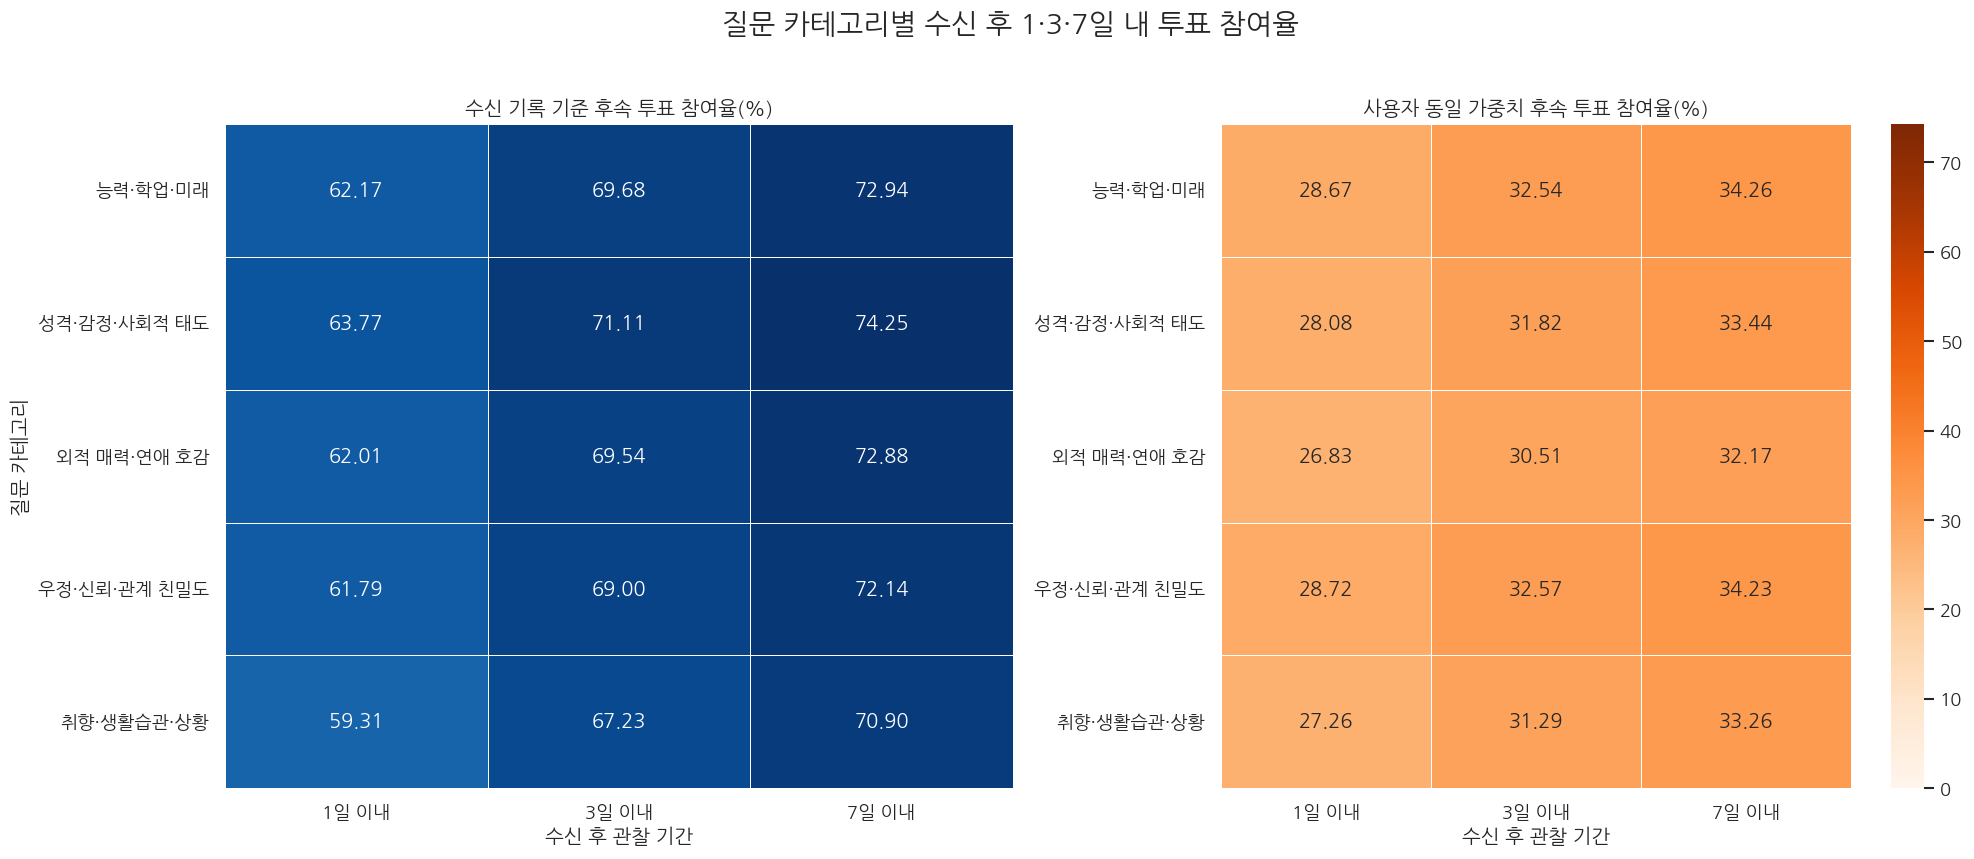

In [354]:
# 기록 기준과 사용자 동일 가중치 기준을 각각 피벗
record_heatmap = (
    category_future_vote_summary.pivot(
        index="category",
        columns="관찰 기간",
        values="record_weighted_rate_pct",
    )
    .reindex(columns=["1일 이내", "3일 이내", "7일 이내"])
)

user_heatmap = (
    category_future_vote_summary.pivot(
        index="category",
        columns="관찰 기간",
        values="user_equal_weight_rate_pct",
    )
    .reindex(
        index=record_heatmap.index,
        columns=["1일 이내", "3일 이내", "7일 이내"],
    )
)

# object 자료형을 숫자형으로 변환
record_heatmap = (
    record_heatmap
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
)

user_heatmap = (
    user_heatmap
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
)

# 두 차트에 동일한 색상 범위 적용
heatmap_max = max(
    record_heatmap.max().max(),
    user_heatmap.max().max(),
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 7),
)

sns.heatmap(
    record_heatmap,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=heatmap_max,
    cbar=False,
    linewidths=0.5,
    ax=axes[0],
)

axes[0].set_title("수신 기록 기준 후속 투표 참여율(%)")
axes[0].set_xlabel("수신 후 관찰 기간")
axes[0].set_ylabel("질문 카테고리")

sns.heatmap(
    user_heatmap,
    annot=True,
    fmt=".2f",
    cmap="Oranges",
    vmin=0,
    vmax=heatmap_max,
    cbar=True,
    linewidths=0.5,
    ax=axes[1],
)

axes[1].set_title("사용자 동일 가중치 후속 투표 참여율(%)")
axes[1].set_xlabel("수신 후 관찰 기간")
axes[1].set_ylabel("")

fig.suptitle(
    "질문 카테고리별 수신 후 1·3·7일 내 투표 참여율",
    fontsize=17,
    y=1.02,
)

plt.tight_layout()
plt.show()

## 5. 초성 확인과 후속 결제의 연관성


### 5-1. 결제 데이터와 분석 범위 확인


In [355]:
# 결제 테이블 기본 품질과 기간 확인
payment_validation = pd.Series(
    {
        "전체 결제 기록": len(payment_base),
        "고유 결제 ID 수": payment_base["id"].nunique(),
        "고유 결제 사용자 수": payment_base["user_id"].nunique(),
        "결제 ID 결측": payment_base["id"].isna().sum(),
        "결제 ID 중복": payment_base["id"].duplicated().sum(),
        "최초 결제 시각": payment_base["created_at"].min(),
        "마지막 결제 시각": payment_base["created_at"].max(),
    },
    name="값",
)

display(payment_validation.to_frame())

# 투표 수신자와 결제자의 교집합 확인
receiver_ids = set(
    category_behavior_base["chosen_user_id"].dropna().unique()
)
payer_ids = set(
    payment_base["user_id"].dropna().unique()
)

display(
    pd.Series(
        {
            "고유 투표 수신자": len(receiver_ids),
            "고유 결제 사용자": len(payer_ids),
            "수신·결제 모두 경험한 사용자": len(receiver_ids & payer_ids),
            "수신자 중 결제 경험자 비율(%)": (
                len(receiver_ids & payer_ids) / len(receiver_ids) * 100
            ),
            "결제자 중 수신 경험자 비율(%)": (
                len(receiver_ids & payer_ids) / len(payer_ids) * 100
            ),
        },
        name="값",
    ).to_frame().round(2)
)


,값
전체 결제 기록,94609
고유 결제 ID 수,94609
고유 결제 사용자 수,59192
결제 ID 결측,0
결제 ID 중복,0
최초 결제 시각,2023-05-13 21:28:34
마지막 결제 시각,2024-05-08 14:12:45


,값
고유 투표 수신자,15402.00
고유 결제 사용자,59192.00
수신·결제 모두 경험한 사용자,1210.00
수신자 중 결제 경험자 비율(%),7.86
결제자 중 수신 경험자 비율(%),2.04


### 5-2. 상품별 결제 특성


In [356]:
# 상품별 결제 기록 기간과 반복 구매 특성 확인

payment_product_profile = (
    payment_base
    .groupby("product_id", observed=True)
    .agg(
        payment_records=("user_id", "size"),
        unique_payers=("user_id", "nunique"),
        first_payment_at=("created_at", "min"),
        last_payment_at=("created_at", "max"),
    )
    .reset_index()
)

# 사용자 한 명당 평균 결제 기록 수

payment_product_profile[
    "records_per_payer"
] = (
    payment_product_profile["payment_records"]
    / payment_product_profile["unique_payers"]
)

display(
    payment_product_profile
    .sort_values("payment_records", ascending=False)
    .round(2)
)


,product_id,payment_records,unique_payers,first_payment_at,last_payment_at,records_per_payer
3,heart.777,57568,57432,2023-05-13 21:28:34,2024-05-06 14:51:27,1.0
0,heart.1000,19189,11124,2023-05-13 21:47:04,2024-05-08 14:12:45,1.73
1,heart.200,15722,9383,2023-05-13 21:39:06,2024-04-30 09:39:37,1.68
2,heart.4000,2130,1501,2023-05-13 21:39:22,2024-03-24 13:20:20,1.42


In [357]:
# 사용자-상품별 결제 횟수 계산

user_product_payment_count = (
    payment_base
    .groupby(
        ["product_id", "user_id"],
        observed=True,
    )
    .size()
    .reset_index(name="payment_count")
)

# 상품별로 1회만 구매한 사용자 비율 계산

product_repeat_summary = (
    user_product_payment_count
    .groupby("product_id", observed=True)
    .agg(
        unique_payers=("user_id", "nunique"),

        one_time_payers=(
            "payment_count",
            lambda x: x.eq(1).sum(),
        ),

        repeat_payers=(
            "payment_count",
            lambda x: x.gt(1).sum(),
        ),

        max_payment_count=(
            "payment_count",
            "max",
        ),
    )
    .reset_index()
)

product_repeat_summary[
    "one_time_payer_rate_pct"
] = (
    product_repeat_summary["one_time_payers"]
    / product_repeat_summary["unique_payers"]
    * 100
)

product_repeat_summary[
    "repeat_payer_rate_pct"
] = (
    product_repeat_summary["repeat_payers"]
    / product_repeat_summary["unique_payers"]
    * 100
)

display(
    product_repeat_summary
    .sort_values("unique_payers", ascending=False)
    .round(2)
)


,product_id,unique_payers,one_time_payers,repeat_payers,max_payment_count,one_time_payer_rate_pct,repeat_payer_rate_pct
3,heart.777,57432,57313,119,5,99.79,0.21
0,heart.1000,11124,7334,3790,26,65.93,34.07
1,heart.200,9383,6052,3331,50,64.50,35.50
2,heart.4000,1501,1177,324,14,78.41,21.59


### 5-3. 수신자별 초성 확인과 후속 결제 연결


In [358]:
# 수신 기록에서 분석에 필요한 컬럼만 가져오기

receipt_analysis_base = (
    category_behavior_base[
        [
            "chosen_user_id",
            "created_at",
            "opened_times",
            "category",
        ]
    ]
    .copy()
)

# 컬럼명을 분석 목적에 맞게 변경
receipt_analysis_base = (
    receipt_analysis_base.rename(
        columns={
            "chosen_user_id": "user_id",
            "created_at": "received_at",
        }
    )
)

# 사용자 ID 형식 통일
receipt_analysis_base["user_id"] = (
    pd.to_numeric(
        receipt_analysis_base["user_id"],
        errors="coerce",
    )
    .astype("Int64")
)

# 수신 시각을 datetime 형식으로 변환
receipt_analysis_base["received_at"] = (
    pd.to_datetime(
        receipt_analysis_base["received_at"],
        errors="coerce",
    )
)

# 초성 확인 개수를 숫자로 변환
receipt_analysis_base["opened_times"] = (
    pd.to_numeric(
        receipt_analysis_base["opened_times"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0, upper=3)
    .astype("int64")
)

# 사용자, 수신 시각, 카테고리를 확인할 수 없는 행 제외
receipt_analysis_base = (
    receipt_analysis_base.dropna(
        subset=[
            "user_id",
            "received_at",
            "category",
        ]
    )
    .copy()
)

display(
    pd.Series(
        {
            "전체 수신 기록 수": len(receipt_analysis_base),
            "고유 수신자 수": (
                receipt_analysis_base["user_id"].nunique()
            ),
            "초성을 1개 이상 확인한 기록 수": (
                receipt_analysis_base["opened_times"].gt(0).sum()
            ),
        },
        name="값",
    ).to_frame()
)


,값
전체 수신 기록 수,1204228
고유 수신자 수,15402
초성을 1개 이상 확인한 기록 수,56747


In [359]:
# 사용자별 수신 행동 요약

user_receipt_summary = (
    receipt_analysis_base
    .groupby("user_id", as_index=False)
    .agg(
        first_received_at=(
            "received_at",
            "min",
        ),
        receipt_records=(
            "received_at",
            "size",
        ),
        total_opened_initials=(
            "opened_times",
            "sum",
        ),
    )
)

# 초성을 한 번이라도 확인했는지 표시
user_receipt_summary["has_opened_initial"] = (
    user_receipt_summary["total_opened_initials"].gt(0)
)

display(
    user_receipt_summary.rename(
        columns={
            "user_id": "사용자 ID",
            "first_received_at": "최초 수신 시각",
            "receipt_records": "누적 수신 건수",
            "total_opened_initials": "누적 초성 확인 개수",
            "has_opened_initial": "초성 확인 경험 여부",
        }
    ).head()
)


,사용자 ID,최초 수신 시각,누적 수신 건수,누적 초성 확인 개수,초성 확인 경험 여부
0,833112,2023-05-05 11:20:53,2,0,False
1,833113,2023-04-29 16:54:18,19,0,False
2,833203,2023-04-29 17:53:35,115,0,False
3,833294,2023-04-29 16:28:09,29,3,True
4,833424,2023-04-30 12:23:03,4,0,False


In [360]:
# 결제 기록에서 필요한 컬럼만 가져오기

payment_analysis_base = (
    payment_base[
        [
            "user_id",
            "product_id",
            "created_at",
        ]
    ]
    .copy()
)

# 결제 시각 컬럼명 변경
payment_analysis_base = (
    payment_analysis_base.rename(
        columns={
            "created_at": "payment_at",
        }
    )
)

# 사용자 ID 형식 통일
payment_analysis_base["user_id"] = (
    pd.to_numeric(
        payment_analysis_base["user_id"],
        errors="coerce",
    )
    .astype("Int64")
)

# 결제 시각을 datetime 형식으로 변환
payment_analysis_base["payment_at"] = (
    pd.to_datetime(
        payment_analysis_base["payment_at"],
        errors="coerce",
    )
)

# 사용자, 상품, 결제 시각을 확인할 수 없는 행 제외
payment_analysis_base = (
    payment_analysis_base.dropna(
        subset=[
            "user_id",
            "product_id",
            "payment_at",
        ]
    )
    .copy()
)

display(
    pd.Series(
        {
            "전체 결제 기록 수": len(payment_analysis_base),
            "고유 결제자 수": (
                payment_analysis_base["user_id"].nunique()
            ),
            "결제 상품 종류 수": (
                payment_analysis_base["product_id"].nunique()
            ),
        },
        name="값",
    ).to_frame()
)


,값
전체 결제 기록 수,94609
고유 결제자 수,59192
결제 상품 종류 수,4


In [361]:
# 최초 투표 결과 수신 이후 발생한 결제만 확인

payment_after_receipt = (
    payment_analysis_base
    .merge(
        user_receipt_summary[
            [
                "user_id",
                "first_received_at",
            ]
        ],
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

# 결제가 최초 수신 시각 이후에 발생했는지 확인
payment_after_receipt = (
    payment_after_receipt.loc[
        payment_after_receipt["payment_at"]
        >= payment_after_receipt["first_received_at"]
    ]
    .copy()
)

display(
    pd.Series(
        {
            "최초 수신 이후 결제 기록 수": (
                len(payment_after_receipt)
            ),
            "최초 수신 이후 결제자 수": (
                payment_after_receipt["user_id"].nunique()
            ),
        },
        name="값",
    ).to_frame()
)


,값
최초 수신 이후 결제 기록 수,1468
최초 수신 이후 결제자 수,944


In [362]:
# 사용자별 결제 상품 구성 요약

user_payment_summary = (
    payment_after_receipt
    .groupby("user_id", as_index=False)
    .agg(
        payment_records=(
            "product_id",
            "size",
        ),
        has_non_777_payment=(
            "product_id",
            lambda x: x.ne("heart.777").any(),
        ),
    )
)

# 결제 기록이 존재하므로 전체 상품 결제 경험은 True
user_payment_summary["has_any_payment"] = True

# 수신 사용자 테이블에 결제 여부 연결
user_receipt_payment = (
    user_receipt_summary
    .merge(
        user_payment_summary,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# 결제 기록이 연결되지 않은 사용자는 결제 경험 없음
user_receipt_payment["has_any_payment"] = (
    user_receipt_payment["has_any_payment"]
    .fillna(False)
    .astype(bool)
)

user_receipt_payment["has_non_777_payment"] = (
    user_receipt_payment["has_non_777_payment"]
    .fillna(False)
    .astype(bool)
)

user_receipt_payment["payment_records"] = (
    user_receipt_payment["payment_records"]
    .fillna(0)
    .astype("int64")
)

display(
    user_receipt_payment.rename(
        columns={
            "user_id": "사용자 ID",
            "first_received_at": "최초 수신 시각",
            "receipt_records": "누적 수신 건수",
            "total_opened_initials": "누적 초성 확인 개수",
            "has_opened_initial": "초성 확인 경험 여부",
            "payment_records": "최초 수신 이후 결제 횟수",
            "has_any_payment": "전체 상품 결제 경험 여부",
            "has_non_777_payment": (
                "heart.777 외 상품 결제 경험 여부"
            ),
        }
    ).head()
)


/tmp/ipykernel_1576/1542953177.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1576/1542953177.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,사용자 ID,최초 수신 시각,누적 수신 건수,누적 초성 확인 개수,초성 확인 경험 여부,최초 수신 이후 결제 횟수,heart.777 외 상품 결제 경험 여부,전체 상품 결제 경험 여부
0,833112,2023-05-05 11:20:53,2,0,False,0,False,False
1,833113,2023-04-29 16:54:18,19,0,False,0,False,False
2,833203,2023-04-29 17:53:35,115,0,False,0,False,False
3,833294,2023-04-29 16:28:09,29,3,True,0,False,False
4,833424,2023-04-30 12:23:03,4,0,False,0,False,False


### 5-4. 누적 초성 확인량별 결제 경험


In [363]:
# 사용자별 누적 초성 확인 개수에 따라 구간 생성
user_receipt_payment["initial_open_group"] = pd.cut(
    user_receipt_payment["total_opened_initials"],
    bins=[-0.001, 0, 1, 3, 6, 10, np.inf],
    labels=[
        "0개",
        "1개",
        "2~3개",
        "4~6개",
        "7~10개",
        "11개 이상",
    ],
    right=True,
)


In [364]:
# 최초 수신 이후 결제 기록을 기준으로
# 사용자별 상품 구매 여부 계산

user_payment_product_type = (
    payment_after_receipt
    .groupby(
        "user_id",
        observed=True,
    )
    .agg(
        has_777_payment=(
            "product_id",
            lambda x: x.eq("heart.777").any(),
        ),

        has_other_payment=(
            "product_id",
            lambda x: x.ne("heart.777").any(),
        ),
    )
    .reset_index()
)


In [365]:
# 사용자별 초성 확인 데이터에
# 결제 상품 유형 연결

user_receipt_payment_segment = (
    user_receipt_payment
    .drop(
        columns=[
            "has_777_payment",
            "has_other_payment",
        ],
        errors="ignore",
    )
    .merge(
        user_payment_product_type,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# 결제가 없는 사용자는 False 처리

user_receipt_payment_segment[
    [
        "has_777_payment",
        "has_other_payment",
    ]
] = (
    user_receipt_payment_segment[
        [
            "has_777_payment",
            "has_other_payment",
        ]
    ]
    .fillna(False)
    .astype(bool)
)


/tmp/ipykernel_1576/2481184993.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [366]:
# 기본값은 결제 없음

user_receipt_payment_segment[
    "payment_product_group"
] = "결제 없음"

# heart.777만 결제한 사용자

user_receipt_payment_segment.loc[
    (
        user_receipt_payment_segment[
            "has_777_payment"
        ]
        &
        ~user_receipt_payment_segment[
            "has_other_payment"
        ]
    ),
    "payment_product_group",
] = "heart.777만 결제"

# 다른 상품을 한 번이라도 결제한 사용자
# heart.777을 함께 구매했더라도 이 그룹에 포함

user_receipt_payment_segment.loc[
    user_receipt_payment_segment[
        "has_other_payment"
    ],
    "payment_product_group",
] = "heart.777 외 상품도 결제"


In [367]:
# 초성 확인 구간별 전체 사용자 수

initial_group_users = (
    user_receipt_payment_segment
    .groupby(
        "initial_open_group",
        observed=True,
    )
    .agg(
        users=(
            "user_id",
            "nunique",
        )
    )
    .reset_index()
)

# 초성 확인 구간·결제 유형별 사용자 수

initial_payment_segment = (
    user_receipt_payment_segment
    .groupby(
        [
            "initial_open_group",
            "payment_product_group",
        ],
        observed=True,
    )
    .agg(
        segment_users=(
            "user_id",
            "nunique",
        )
    )
    .reset_index()
    .merge(
        initial_group_users,
        on="initial_open_group",
        how="left",
        validate="many_to_one",
    )
)

# 해당 초성 확인 구간의 전체 사용자 중
# 각 결제 유형이 차지하는 비율

initial_payment_segment[
    "segment_rate_pct"
] = (
    initial_payment_segment[
        "segment_users"
    ]
    / initial_payment_segment[
        "users"
    ]
    * 100
)


In [368]:
# 결제 경험자만 출력용 표로 확인

initial_payment_segment_display = (
    initial_payment_segment.loc[
        initial_payment_segment[
            "payment_product_group"
        ].ne("결제 없음")
    ]
    .rename(
        columns={
            "initial_open_group":
                "누적 초성 확인 구간",
            "payment_product_group":
                "결제 상품 유형",
            "segment_users":
                "결제자 수(명)",
            "users":
                "구간 전체 사용자 수(명)",
            "segment_rate_pct":
                "구간 전체 사용자 중 비율(%)",
        }
    )
    [
        [
            "누적 초성 확인 구간",
            "결제 상품 유형",
            "구간 전체 사용자 수(명)",
            "결제자 수(명)",
            "구간 전체 사용자 중 비율(%)",
        ]
    ]
    .round(2)
)

display(initial_payment_segment_display)


,누적 초성 확인 구간,결제 상품 유형,구간 전체 사용자 수(명),결제자 수(명),구간 전체 사용자 중 비율(%)
0,0개,heart.777 외 상품도 결제,8131,85,1.05
1,0개,heart.777만 결제,8131,225,2.77
3,1개,heart.777 외 상품도 결제,1302,24,1.84
4,1개,heart.777만 결제,1302,40,3.07
6,2~3개,heart.777 외 상품도 결제,1464,24,1.64
7,2~3개,heart.777만 결제,1464,69,4.71
9,4~6개,heart.777 외 상품도 결제,1074,18,1.68
10,4~6개,heart.777만 결제,1074,48,4.47
12,7~10개,heart.777 외 상품도 결제,958,14,1.46
13,7~10개,heart.777만 결제,958,54,5.64


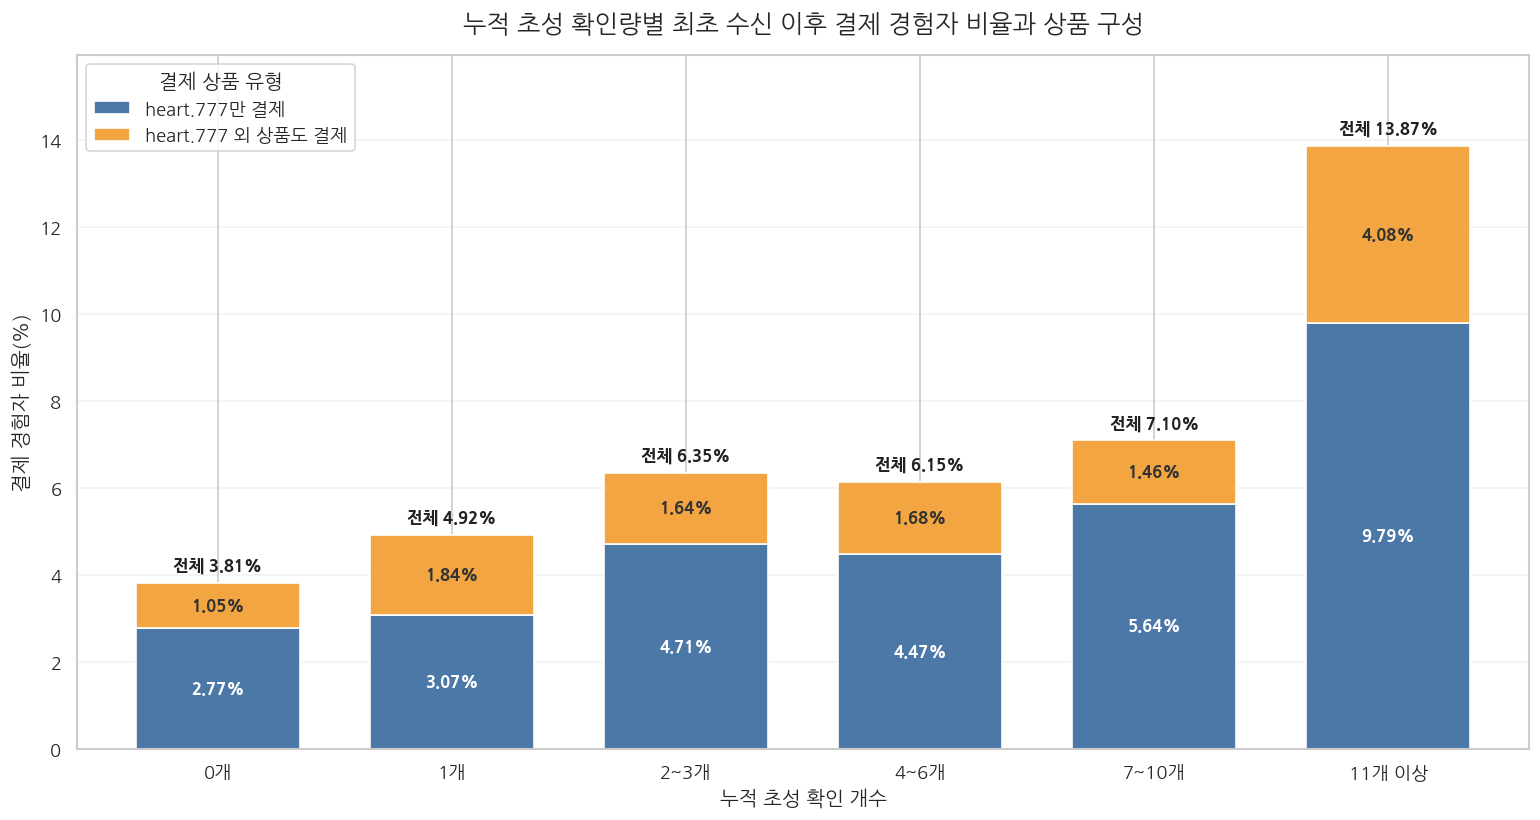

In [369]:
# 누적 막대용 데이터 생성
# 결제 없음은 제외하므로 막대 전체 높이가 결제율이 됨

stacked_payment_chart = (
    initial_payment_segment.loc[
        initial_payment_segment[
            "payment_product_group"
        ].ne("결제 없음")
    ]
    .pivot(
        index="initial_open_group",
        columns="payment_product_group",
        values="segment_rate_pct",
    )
    .fillna(0)
    .reindex(
        [
            "0개",
            "1개",
            "2~3개",
            "4~6개",
            "7~10개",
            "11개 이상",
        ]
    )
)

# 열 표시 순서 통일

stacked_payment_chart = (
    stacked_payment_chart.reindex(
        columns=[
            "heart.777만 결제",
            "heart.777 외 상품도 결제",
        ],
        fill_value=0,
    )
)

# 누적 막대 차트 생성

ax = stacked_payment_chart.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    color=[
        "#4C78A8",
        "#F2A541",
    ],
    width=0.7,
)

# 누적 막대 안에 각 결제 유형의 비율 표시

for x_position, group_name in enumerate(
    stacked_payment_chart.index
):

    # 현재까지 쌓인 막대 높이
    bottom = 0

    for payment_type in (
        stacked_payment_chart.columns
    ):

        value = stacked_payment_chart.loc[
            group_name,
            payment_type,
        ]

        # 값이 0보다 클 때만 표시

        if value > 0:

            # 각 막대 조각의 정중앙에 값 표시

            ax.text(
                x=x_position,
                y=bottom + value / 2,
                s=f"{value:.2f}%",
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold",
                color=(
                    "white"
                    if payment_type
                    == "heart.777만 결제"
                    else "#333333"
                ),
            )

        # 다음 막대가 시작될 위치

        bottom += value

# 막대 전체 높이, 즉 전체 결제율 계산

total_payment_rate = (
    stacked_payment_chart.sum(axis=1)
)

# 막대 위에 전체 결제율 표시

for x_position, total in enumerate(
    total_payment_rate
):
    ax.text(
        x=x_position,
        y=total + 0.2,
        s=f"전체 {total:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#222222",
    )

# 전체 결제율 라벨이 잘리지 않도록
# y축 최대 범위에 여유 추가

ax.set_ylim(
    0,
    total_payment_rate.max() * 1.15,
)

plt.title(
    "누적 초성 확인량별 최초 수신 이후 결제 경험자 비율과 상품 구성",
    fontsize=15,
    pad=15,
)

plt.xlabel("누적 초성 확인 개수")
plt.ylabel("결제 경험자 비율(%)")

plt.xticks(rotation=0)

plt.legend(
    title="결제 상품 유형"
)

plt.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()
plt.show()


### 5-5. 누적 수신량을 고려한 결제 경험 비교


In [370]:
# 사용자의 누적 수신량을 4개 구간으로 구분

user_receipt_payment["receipt_volume_group"] = (
    pd.qcut(
        user_receipt_payment["receipt_records"],
        q=4,
        duplicates="drop",
    )
)

# 구간별 실제 최소·최대 수신 건수 계산
receipt_group_bounds = (
    user_receipt_payment
    .groupby(
        "receipt_volume_group",
        observed=True,
    )
    .agg(
        minimum_receipts=(
            "receipt_records",
            "min",
        ),
        maximum_receipts=(
            "receipt_records",
            "max",
        ),
    )
    .reset_index()
    .sort_values("minimum_receipts")
)

# 수신량 수준을 설명하는 이름
level_names_by_count = {
    1: ["전체 사용자"],
    2: ["수신 적음", "수신 많음"],
    3: ["수신 적음", "수신 보통", "수신 많음"],
    4: [
        "수신 적음",
        "수신 보통 이하",
        "수신 보통 이상",
        "수신 많음",
    ],
}

number_of_groups = len(receipt_group_bounds)

volume_level_names = level_names_by_count.get(
    number_of_groups,
    [
        f"수신량 {number}구간"
        for number in range(1, number_of_groups + 1)
    ],
)

# 발표용으로 이해하기 쉬운 x축 이름 생성
receipt_group_bounds["수신량 구간"] = [
    (
        f"{level_name}\n"
        f"({int(minimum):,}~{int(maximum):,}건)"
    )
    for level_name, minimum, maximum
    in zip(
        volume_level_names,
        receipt_group_bounds["minimum_receipts"],
        receipt_group_bounds["maximum_receipts"],
    )
]

# 판다 구간과 발표용 이름 연결
receipt_group_label_map = dict(
    zip(
        receipt_group_bounds["receipt_volume_group"],
        receipt_group_bounds["수신량 구간"],
    )
)

user_receipt_payment["수신량 구간"] = (
    user_receipt_payment["receipt_volume_group"]
    .astype("object")
    .map(receipt_group_label_map)
)

# 차트에서 사용할 수신량 구간 순서
receipt_volume_order = (
    receipt_group_bounds["수신량 구간"].tolist()
)

user_receipt_payment["수신량 구간"] = (
    pd.Categorical(
        user_receipt_payment["수신량 구간"],
        categories=receipt_volume_order,
        ordered=True,
    )
)

display(
    receipt_group_bounds[
        [
            "수신량 구간",
            "minimum_receipts",
            "maximum_receipts",
        ]
    ]
    .rename(
        columns={
            "minimum_receipts": "최소 수신 건수",
            "maximum_receipts": "최대 수신 건수",
        }
    )
)


,수신량 구간,최소 수신 건수,최대 수신 건수
0,수신 적음\n(1~3건),1,3
1,수신 보통 이하\n(4~15건),4,15
2,수신 보통 이상\n(16~97건),16,97
3,"수신 많음\n(98~1,224건)",98,1224


In [371]:
# 초성 확인 경험을 한글 표시명으로 변환

user_receipt_payment["초성 확인 경험"] = np.where(
    user_receipt_payment["has_opened_initial"],
    "초성 확인 있음",
    "초성 확인 없음",
)

initial_open_order = [
    "초성 확인 없음",
    "초성 확인 있음",
]

user_receipt_payment["초성 확인 경험"] = (
    pd.Categorical(
        user_receipt_payment["초성 확인 경험"],
        categories=initial_open_order,
        ordered=True,
    )
)


In [372]:
# 수신량이 비슷한 사용자끼리 결제 경험률 비교

receipt_control_summary = (
    user_receipt_payment
    .groupby(
        [
            "수신량 구간",
            "초성 확인 경험",
        ],
        observed=True,
    )
    .agg(
        사용자_수=(
            "user_id",
            "nunique",
        ),
        평균_수신_건수=(
            "receipt_records",
            "mean",
        ),
        평균_초성_확인_개수=(
            "total_opened_initials",
            "mean",
        ),
        전체_상품_결제자_수=(
            "has_any_payment",
            "sum",
        ),
        heart_777_외_상품_결제자_수=(
            "has_non_777_payment",
            "sum",
        ),
    )
    .reset_index()
)

# 전체 상품 결제 경험률
receipt_control_summary["전체 상품 결제 경험률(%)"] = (
    receipt_control_summary["전체_상품_결제자_수"]
    / receipt_control_summary["사용자_수"]
    * 100
)

# heart.777 외 상품 결제 경험률
receipt_control_summary[
    "heart.777 외 상품 결제 경험률(%)"
] = (
    receipt_control_summary[
        "heart_777_외_상품_결제자_수"
    ]
    / receipt_control_summary["사용자_수"]
    * 100
)

# 표시용 컬럼명 변경
receipt_control_display = (
    receipt_control_summary.rename(
        columns={
            "사용자_수": "사용자 수",
            "평균_수신_건수": "평균 수신 건수",
            "평균_초성_확인_개수": "평균 초성 확인 개수",
            "전체_상품_결제자_수": "전체 상품 결제자 수",
            "heart_777_외_상품_결제자_수": (
                "heart.777 외 상품 결제자 수"
            ),
        }
    )
)

# 소수점 정리
receipt_control_display[
    [
        "평균 수신 건수",
        "평균 초성 확인 개수",
        "전체 상품 결제 경험률(%)",
        "heart.777 외 상품 결제 경험률(%)",
    ]
] = (
    receipt_control_display[
        [
            "평균 수신 건수",
            "평균 초성 확인 개수",
            "전체 상품 결제 경험률(%)",
            "heart.777 외 상품 결제 경험률(%)",
        ]
    ]
    .round(2)
)

display(receipt_control_display)


,수신량 구간,초성 확인 경험,사용자 수,평균 수신 건수,평균 초성 확인 개수,전체 상품 결제자 수,heart.777 외 상품 결제자 수,전체 상품 결제 경험률(%),heart.777 외 상품 결제 경험률(%)
0,수신 적음\n(1~3건),초성 확인 없음,3522,1.70,0.00,120,35,3.41,0.99
1,수신 적음\n(1~3건),초성 확인 있음,427,1.94,1.51,28,9,6.56,2.11
2,수신 보통 이하\n(4~15건),초성 확인 없음,2874,7.82,0.00,132,34,4.59,1.18
3,수신 보통 이하\n(4~15건),초성 확인 있음,992,8.88,2.14,87,26,8.77,2.62
4,수신 보통 이상\n(16~97건),초성 확인 없음,1537,35.62,0.00,55,15,3.58,0.98
5,수신 보통 이상\n(16~97건),초성 확인 있음,2220,48.24,5.14,179,51,8.06,2.30
6,"수신 많음\n(98~1,224건)",초성 확인 없음,198,193.72,0.00,3,1,1.52,0.51
7,"수신 많음\n(98~1,224건)",초성 확인 있음,3632,265.94,16.23,340,95,9.36,2.62


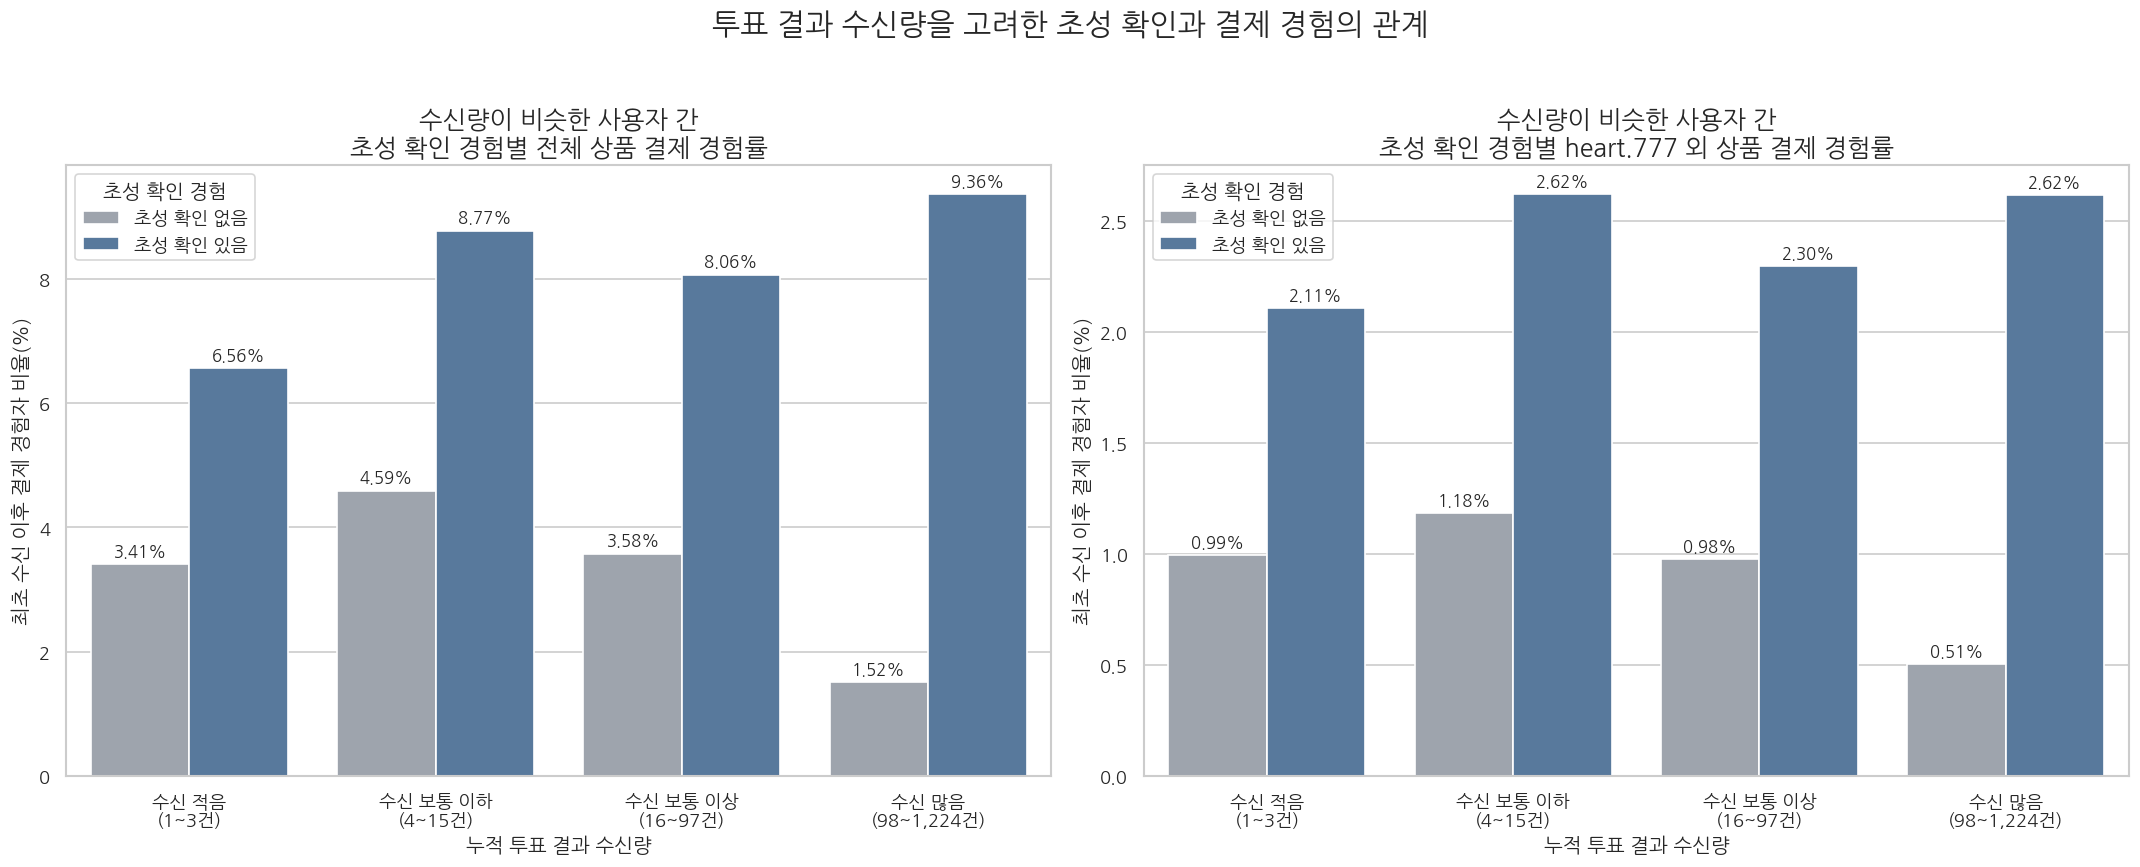

In [373]:
# 수신량 구간별 초성 확인 경험과 결제율 비교

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 7),
)

color_map = {
    "초성 확인 없음": "#9CA3AF",
    "초성 확인 있음": "#4C78A8",
}

# ------------------------------------------------------------
# 왼쪽: 전체 상품 결제 경험률
# ------------------------------------------------------------

sns.barplot(
    data=receipt_control_summary,
    x="수신량 구간",
    y="전체 상품 결제 경험률(%)",
    hue="초성 확인 경험",
    order=receipt_volume_order,
    hue_order=initial_open_order,
    palette=color_map,
    ax=axes[0],
)

axes[0].set_title(
    "수신량이 비슷한 사용자 간\n초성 확인 경험별 전체 상품 결제 경험률",
    fontsize=15,
)

axes[0].set_xlabel("누적 투표 결과 수신량")
axes[0].set_ylabel("최초 수신 이후 결제 경험자 비율(%)")

# 막대 위에 비율 표시
for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=10,
    )

axes[0].legend(
    title="초성 확인 경험",
    loc="upper left",
)

# ------------------------------------------------------------
# 오른쪽: heart.777 외 상품 결제 경험률
# ------------------------------------------------------------

sns.barplot(
    data=receipt_control_summary,
    x="수신량 구간",
    y="heart.777 외 상품 결제 경험률(%)",
    hue="초성 확인 경험",
    order=receipt_volume_order,
    hue_order=initial_open_order,
    palette=color_map,
    ax=axes[1],
)

axes[1].set_title(
    "수신량이 비슷한 사용자 간\n초성 확인 경험별 heart.777 외 상품 결제 경험률",
    fontsize=15,
)

axes[1].set_xlabel("누적 투표 결과 수신량")
axes[1].set_ylabel("최초 수신 이후 결제 경험자 비율(%)")

# 막대 위에 비율 표시
for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=10,
    )

axes[1].legend(
    title="초성 확인 경험",
    loc="upper left",
)

plt.suptitle(
    "투표 결과 수신량을 고려한 초성 확인과 결제 경험의 관계",
    fontsize=18,
    y=1.03,
)

plt.tight_layout()
plt.show()


### 5-6. 동일한 30일 관찰 기간에서 후속 결제 비교


In [374]:
# 수신 데이터와 결제 데이터가 모두 존재하는 기간 확인

analysis_start_at = max(
    receipt_analysis_base["received_at"].min(),
    payment_analysis_base["payment_at"].min(),
)

analysis_end_at = min(
    receipt_analysis_base["received_at"].max(),
    payment_analysis_base["payment_at"].max(),
)

display(
    pd.Series(
        {
            "공통 데이터 시작 시각": analysis_start_at,
            "공통 데이터 종료 시각": analysis_end_at,
            "공통 데이터 기간(일)": (
                analysis_end_at - analysis_start_at
            ).days,
        },
        name="값",
    ).to_frame()
)


,값
공통 데이터 시작 시각,2023-05-13 21:28:34
공통 데이터 종료 시각,2024-05-08 01:36:18
공통 데이터 기간(일),360


In [375]:
# 최초 수신 후 30일까지 관찰 가능한 사용자만 선정

fixed_window_users = (
    user_receipt_summary[
        [
            "user_id",
            "first_received_at",
        ]
    ]
    .copy()
)

# 최초 수신 후 7일과 30일이 되는 시점
fixed_window_users["day_7_at"] = (
    fixed_window_users["first_received_at"]
    + pd.Timedelta(days=7)
)

fixed_window_users["day_30_at"] = (
    fixed_window_users["first_received_at"]
    + pd.Timedelta(days=30)
)

# 결제 데이터 시작 이후 최초 수신한 사용자만 포함
# 데이터 종료일까지 30일을 모두 관찰할 수 있어야 함
fixed_window_users = (
    fixed_window_users.loc[
        fixed_window_users["first_received_at"].ge(
            analysis_start_at
        )
        &
        fixed_window_users["day_30_at"].le(
            analysis_end_at
        )
    ]
    .copy()
)

display(
    pd.Series(
        {
            "전체 수신자 수": (
                user_receipt_summary["user_id"].nunique()
            ),
            "30일 관찰 가능 사용자 수": (
                fixed_window_users["user_id"].nunique()
            ),
            "분석 제외 사용자 수": (
                user_receipt_summary["user_id"].nunique()
                - fixed_window_users["user_id"].nunique()
            ),
        },
        name="사용자 수",
    ).to_frame()
)


,사용자 수
전체 수신자 수,15402
30일 관찰 가능 사용자 수,6337
분석 제외 사용자 수,9065


In [376]:
# 최초 수신 후 7일간의 수신 기록만 추출

early_receipt_records = (
    receipt_analysis_base
    .merge(
        fixed_window_users[
            [
                "user_id",
                "first_received_at",
                "day_7_at",
            ]
        ],
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

# 최초 수신 시점부터 7일이 되기 전까지의 수신 기록
early_receipt_records = (
    early_receipt_records.loc[
        early_receipt_records["received_at"].ge(
            early_receipt_records["first_received_at"]
        )
        &
        early_receipt_records["received_at"].lt(
            early_receipt_records["day_7_at"]
        )
    ]
    .copy()
)

# 사용자별 초기 7일 행동 요약
early_user_behavior = (
    early_receipt_records
    .groupby("user_id", as_index=False)
    .agg(
        early_receipt_count=(
            "received_at",
            "size",
        ),
        early_opened_initials=(
            "opened_times",
            "sum",
        ),
    )
)

# 초기 7일에 수신한 기록 중 초성이 확인된 기록이 있는지 표시
early_user_behavior["early_has_opened_initial"] = (
    early_user_behavior["early_opened_initials"].gt(0)
)

display(
    early_user_behavior.rename(
        columns={
            "user_id": "사용자 ID",
            "early_receipt_count": "초기 7일 수신 건수",
            "early_opened_initials": (
                "초기 7일 수신 기록의 초성 확인 개수"
            ),
            "early_has_opened_initial": (
                "초기 초성 확인 경험 여부"
            ),
        }
    ).head()
)


,사용자 ID,초기 7일 수신 건수,초기 7일 수신 기록의 초성 확인 개수,초기 초성 확인 경험 여부
0,837703,1,0,False
1,838297,1,0,False
2,839909,18,0,False
3,840603,1,0,False
4,840911,1,0,False


In [377]:
# 최초 수신 후 8~30일차에 발생한 결제만 추출

later_payment_records = (
    payment_analysis_base
    .merge(
        fixed_window_users[
            [
                "user_id",
                "day_7_at",
                "day_30_at",
            ]
        ],
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

# 초기 7일이 지난 후부터 30일이 되기 전까지의 결제
later_payment_records = (
    later_payment_records.loc[
        later_payment_records["payment_at"].ge(
            later_payment_records["day_7_at"]
        )
        &
        later_payment_records["payment_at"].lt(
            later_payment_records["day_30_at"]
        )
    ]
    .copy()
)

# 사용자별 후속 결제 경험 요약
later_user_payment = (
    later_payment_records
    .groupby("user_id", as_index=False)
    .agg(
        later_payment_count=(
            "product_id",
            "size",
        ),
        later_has_non_777_payment=(
            "product_id",
            lambda x: x.ne("heart.777").any(),
        ),
    )
)

# 결제 기록이 있으면 전체 상품 결제 경험 있음
later_user_payment["later_has_any_payment"] = True

display(
    pd.Series(
        {
            "8~30일차 결제 기록 수": (
                len(later_payment_records)
            ),
            "8~30일차 고유 결제자 수": (
                later_payment_records["user_id"].nunique()
            ),
        },
        name="값",
    ).to_frame()
)


,값
8~30일차 결제 기록 수,85
8~30일차 고유 결제자 수,61


In [378]:
# 초기 7일 행동과 8~30일차 결제 경험 연결

fixed_window_analysis = (
    fixed_window_users[
        [
            "user_id",
            "first_received_at",
        ]
    ]
    .merge(
        early_user_behavior,
        on="user_id",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        later_user_payment,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# 결제가 연결되지 않은 사용자는 후속 결제 경험 없음
fixed_window_analysis["later_payment_count"] = (
    fixed_window_analysis["later_payment_count"]
    .fillna(0)
    .astype("int64")
)

fixed_window_analysis["later_has_any_payment"] = (
    fixed_window_analysis["later_has_any_payment"]
    .fillna(False)
    .astype(bool)
)

fixed_window_analysis["later_has_non_777_payment"] = (
    fixed_window_analysis["later_has_non_777_payment"]
    .fillna(False)
    .astype(bool)
)

# 차트에 사용할 한글 표시명
fixed_window_analysis["초기 초성 확인 경험"] = np.where(
    fixed_window_analysis["early_has_opened_initial"],
    "초성 확인 있음",
    "초성 확인 없음",
)

initial_open_order = [
    "초성 확인 없음",
    "초성 확인 있음",
]

display(
    fixed_window_analysis.rename(
        columns={
            "user_id": "사용자 ID",
            "first_received_at": "최초 수신 시각",
            "early_receipt_count": "초기 7일 수신 건수",
            "early_opened_initials": (
                "초기 7일 수신 기록의 초성 확인 개수"
            ),
            "later_payment_count": "8~30일차 결제 횟수",
            "later_has_any_payment": (
                "8~30일차 전체 상품 결제 경험 여부"
            ),
            "later_has_non_777_payment": (
                "8~30일차 heart.777 외 상품 결제 경험 여부"
            ),
        }
    ).head()
)


/tmp/ipykernel_1576/2720550106.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1576/2720550106.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,사용자 ID,최초 수신 시각,초기 7일 수신 건수,초기 7일 수신 기록의 초성 확인 개수,early_has_opened_initial,8~30일차 결제 횟수,8~30일차 heart.777 외 상품 결제 경험 여부,8~30일차 전체 상품 결제 경험 여부,초기 초성 확인 경험
0,837703,2023-05-28 15:55:05,1,0,False,0,False,False,초성 확인 없음
1,838297,2023-05-25 00:53:20,1,0,False,0,False,False,초성 확인 없음
2,839909,2023-05-25 11:43:32,18,0,False,0,False,False,초성 확인 없음
3,840603,2023-05-17 11:12:11,1,0,False,0,False,False,초성 확인 없음
4,840911,2023-05-16 12:32:55,1,0,False,0,False,False,초성 확인 없음


In [379]:
# 초기 7일 수신량을 기준으로 사용자 4개 구간 생성

fixed_window_analysis["early_receipt_group"] = (
    pd.qcut(
        fixed_window_analysis["early_receipt_count"],
        q=4,
        duplicates="drop",
    )
)

# 각 구간의 실제 최소·최대 수신 건수 계산
early_group_bounds = (
    fixed_window_analysis
    .groupby(
        "early_receipt_group",
        observed=True,
    )
    .agg(
        minimum_receipts=(
            "early_receipt_count",
            "min",
        ),
        maximum_receipts=(
            "early_receipt_count",
            "max",
        ),
    )
    .reset_index()
    .sort_values("minimum_receipts")
)

level_names_by_count = {
    1: ["전체 사용자"],
    2: ["수신 적음", "수신 많음"],
    3: ["수신 적음", "수신 보통", "수신 많음"],
    4: [
        "수신 적음",
        "수신 보통 이하",
        "수신 보통 이상",
        "수신 많음",
    ],
}

number_of_groups = len(early_group_bounds)

volume_level_names = level_names_by_count.get(
    number_of_groups,
    [
        f"수신량 {number}구간"
        for number in range(1, number_of_groups + 1)
    ],
)

# 실제 건수가 포함된 직관적인 표시명 생성
early_group_bounds["초기 수신량 구간"] = [
    (
        f"{level_name}\n"
        f"({int(minimum):,}~{int(maximum):,}건)"
    )
    for level_name, minimum, maximum
    in zip(
        volume_level_names,
        early_group_bounds["minimum_receipts"],
        early_group_bounds["maximum_receipts"],
    )
]

early_group_label_map = dict(
    zip(
        early_group_bounds["early_receipt_group"],
        early_group_bounds["초기 수신량 구간"],
    )
)

fixed_window_analysis["초기 수신량 구간"] = (
    fixed_window_analysis["early_receipt_group"]
    .astype("object")
    .map(early_group_label_map)
)

early_receipt_order = (
    early_group_bounds["초기 수신량 구간"].tolist()
)

fixed_window_analysis["초기 수신량 구간"] = (
    pd.Categorical(
        fixed_window_analysis["초기 수신량 구간"],
        categories=early_receipt_order,
        ordered=True,
    )
)

display(
    early_group_bounds[
        [
            "초기 수신량 구간",
            "minimum_receipts",
            "maximum_receipts",
        ]
    ]
    .rename(
        columns={
            "minimum_receipts": "최소 수신 건수",
            "maximum_receipts": "최대 수신 건수",
        }
    )
)


,초기 수신량 구간,최소 수신 건수,최대 수신 건수
0,수신 적음\n(1~4건),1,4
1,수신 보통\n(5~27건),5,27
2,수신 많음\n(28~739건),28,739


In [380]:
# 초기 수신량이 비슷한 사용자끼리 후속 결제율 비교

fixed_window_summary = (
    fixed_window_analysis
    .groupby(
        [
            "초기 수신량 구간",
            "초기 초성 확인 경험",
        ],
        observed=True,
    )
    .agg(
        사용자_수=(
            "user_id",
            "nunique",
        ),
        평균_초기_수신_건수=(
            "early_receipt_count",
            "mean",
        ),
        전체_상품_후속_결제자_수=(
            "later_has_any_payment",
            "sum",
        ),
        heart_777_외_후속_결제자_수=(
            "later_has_non_777_payment",
            "sum",
        ),
    )
    .reset_index()
)

fixed_window_summary["전체 상품 후속 결제율(%)"] = (
    fixed_window_summary["전체_상품_후속_결제자_수"]
    / fixed_window_summary["사용자_수"]
    * 100
)

fixed_window_summary[
    "heart.777 외 상품 후속 결제율(%)"
] = (
    fixed_window_summary["heart_777_외_후속_결제자_수"]
    / fixed_window_summary["사용자_수"]
    * 100
)

fixed_window_display = (
    fixed_window_summary.rename(
        columns={
            "사용자_수": "사용자 수",
            "평균_초기_수신_건수": "평균 초기 수신 건수",
            "전체_상품_후속_결제자_수": (
                "전체 상품 후속 결제자 수"
            ),
            "heart_777_외_후속_결제자_수": (
                "heart.777 외 후속 결제자 수"
            ),
        }
    )
)

number_columns = [
    "평균 초기 수신 건수",
    "전체 상품 후속 결제율(%)",
    "heart.777 외 상품 후속 결제율(%)",
]

fixed_window_display[number_columns] = (
    fixed_window_display[number_columns].round(2)
)

display(fixed_window_display)


,초기 수신량 구간,초기 초성 확인 경험,사용자 수,평균 초기 수신 건수,전체 상품 후속 결제자 수,heart.777 외 후속 결제자 수,전체 상품 후속 결제율(%),heart.777 외 상품 후속 결제율(%)
0,수신 적음\n(1~4건),초성 확인 없음,2873,1.75,21,11,0.73,0.38
1,수신 적음\n(1~4건),초성 확인 있음,338,2.12,5,3,1.48,0.89
2,수신 보통\n(5~27건),초성 확인 없음,1013,10.50,7,2,0.69,0.20
3,수신 보통\n(5~27건),초성 확인 있음,544,13.34,8,3,1.47,0.55
4,수신 많음\n(28~739건),초성 확인 없음,198,63.54,1,0,0.51,0.00
5,수신 많음\n(28~739건),초성 확인 있음,1371,152.49,19,9,1.39,0.66


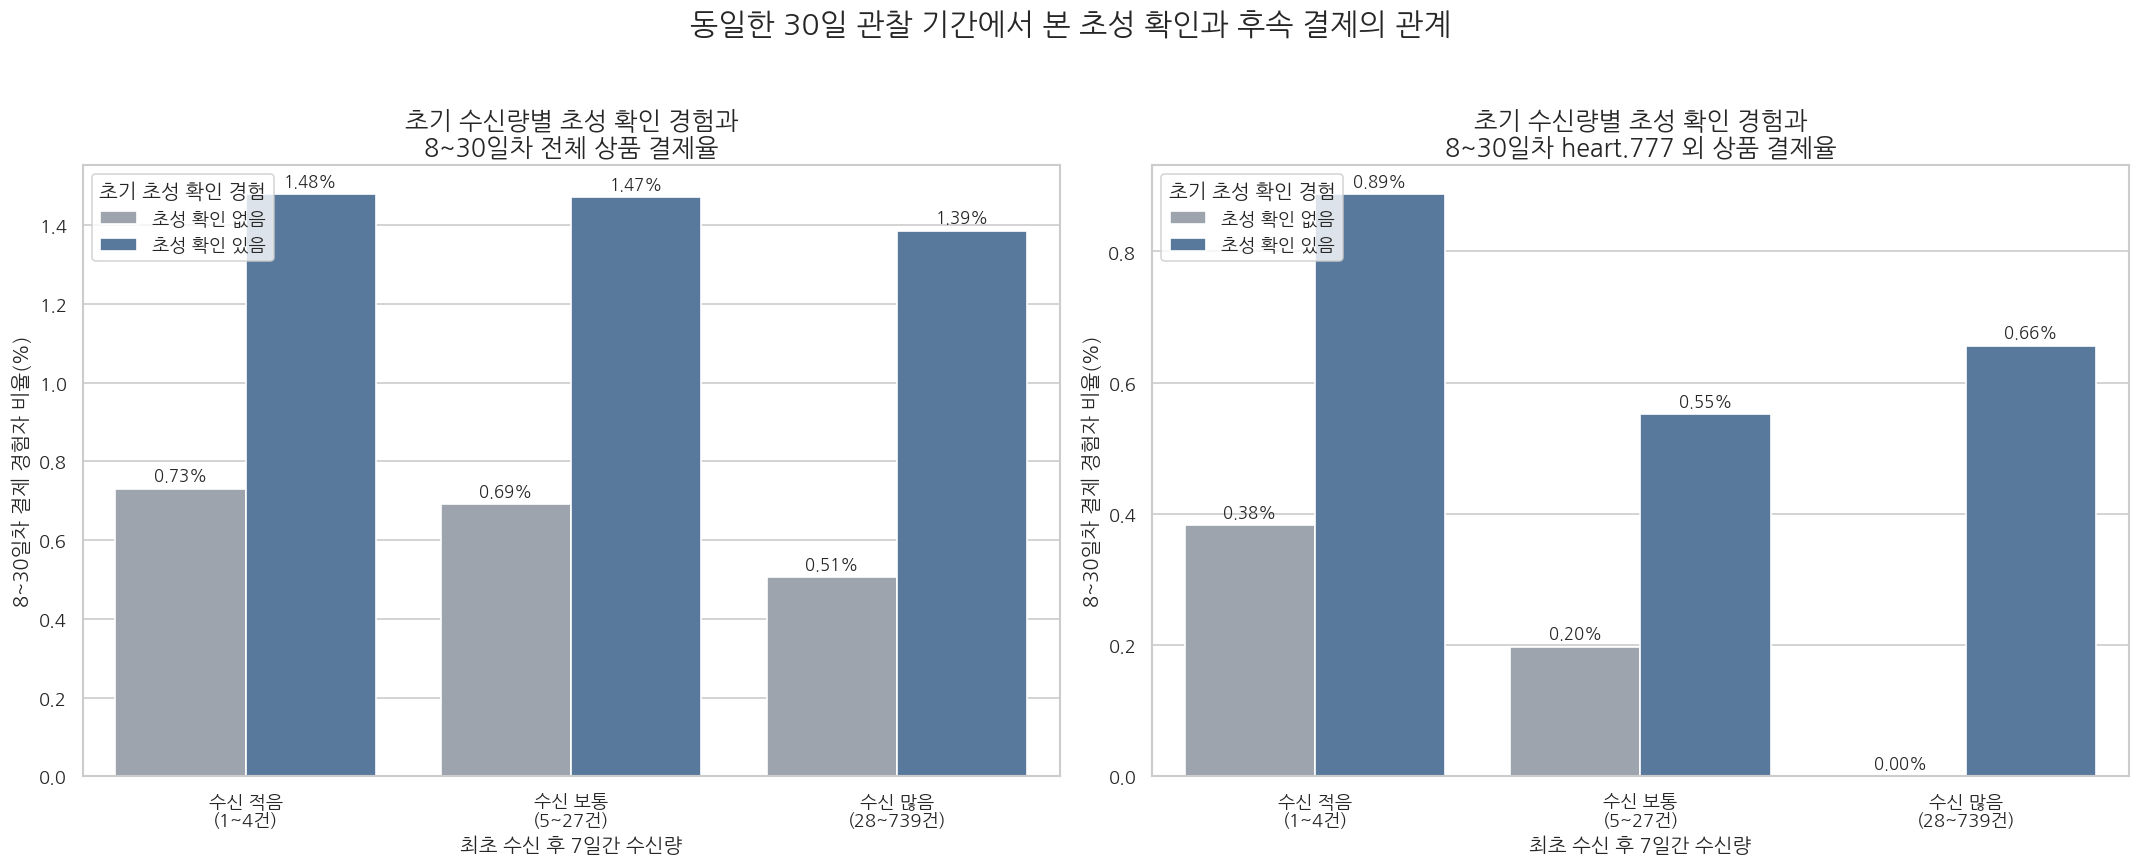

In [381]:
# 초기 수신량을 고려한 초성 확인과 후속 결제 관계 시각화

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 7),
)

color_map = {
    "초성 확인 없음": "#9CA3AF",
    "초성 확인 있음": "#4C78A8",
}

# 전체 상품 후속 결제율
sns.barplot(
    data=fixed_window_summary,
    x="초기 수신량 구간",
    y="전체 상품 후속 결제율(%)",
    hue="초기 초성 확인 경험",
    order=early_receipt_order,
    hue_order=initial_open_order,
    palette=color_map,
    ax=axes[0],
)

axes[0].set_title(
    "초기 수신량별 초성 확인 경험과\n8~30일차 전체 상품 결제율",
    fontsize=15,
)
axes[0].set_xlabel("최초 수신 후 7일간 수신량")
axes[0].set_ylabel("8~30일차 결제 경험자 비율(%)")

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=10,
    )

axes[0].legend(
    title="초기 초성 확인 경험",
    loc="upper left",
)

# heart.777 외 상품 후속 결제율
sns.barplot(
    data=fixed_window_summary,
    x="초기 수신량 구간",
    y="heart.777 외 상품 후속 결제율(%)",
    hue="초기 초성 확인 경험",
    order=early_receipt_order,
    hue_order=initial_open_order,
    palette=color_map,
    ax=axes[1],
)

axes[1].set_title(
    "초기 수신량별 초성 확인 경험과\n8~30일차 heart.777 외 상품 결제율",
    fontsize=15,
)
axes[1].set_xlabel("최초 수신 후 7일간 수신량")
axes[1].set_ylabel("8~30일차 결제 경험자 비율(%)")

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=10,
    )

axes[1].legend(
    title="초기 초성 확인 경험",
    loc="upper left",
)

plt.suptitle(
    "동일한 30일 관찰 기간에서 본 초성 확인과 후속 결제의 관계",
    fontsize=18,
    y=1.03,
)

plt.tight_layout()
plt.show()


## 6. 결과 신뢰성 검증

앞에서 확인한 카테고리 차이가 단순한 표본 수, 특정 사용자의 반복 행동 또는 특정 시기에 의해 만들어진 결과인지 확인한다.

검증은 다음 네 가지 관점으로 진행한다.

1. 카테고리별 표본 수와 95% 신뢰구간
2. 반복 수신이 많은 사용자의 영향 제거
3. 월별 순위와 추세의 안정성
4. 수신량 구성을 보정한 초성 확인과 후속 결제의 연관성

### 6-1. 카테고리별 표본 수와 초성 확인율의 95% 신뢰구간

In [382]:
# 이항 비율의 Wilson 95% 신뢰구간 계산 함수
def calculate_wilson_interval(successes, total, z=1.96):
    successes = np.asarray(successes, dtype="float64")
    total = np.asarray(total, dtype="float64")

    proportion = np.divide(
        successes,
        total,
        out=np.full_like(successes, np.nan),
        where=total > 0,
    )

    denominator = 1 + (z ** 2 / total)
    center = (
        proportion + z ** 2 / (2 * total)
    ) / denominator
    margin = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / total
            + z ** 2 / (4 * total ** 2)
        )
        / denominator
    )

    return center - margin, center + margin


# 카테고리별 수신 기록 수, 수신자 수와 초성 확인 건수 집계
category_confidence_summary = (
    category_spend_analysis
    .groupby("category", observed=True)
    .agg(
        receipt_records=("id", "size"),
        unique_receivers=("chosen_user_id", "nunique"),
        opened_records=("초성_확인_여부", "sum"),
        fully_opened_records=("초성_전체_확인_여부", "sum"),
    )
    .reset_index()
)

# 초성 1개 이상 확인율의 신뢰구간
(
    category_confidence_summary["open_ci_low"],
    category_confidence_summary["open_ci_high"],
) = calculate_wilson_interval(
    category_confidence_summary["opened_records"],
    category_confidence_summary["receipt_records"],
)

# 초성 3개 전체 확인율의 신뢰구간
(
    category_confidence_summary["full_open_ci_low"],
    category_confidence_summary["full_open_ci_high"],
) = calculate_wilson_interval(
    category_confidence_summary["fully_opened_records"],
    category_confidence_summary["receipt_records"],
)

category_confidence_summary["open_rate_pct"] = (
    category_confidence_summary["opened_records"]
    / category_confidence_summary["receipt_records"]
    * 100
)
category_confidence_summary["open_ci_low_pct"] = (
    category_confidence_summary["open_ci_low"] * 100
)
category_confidence_summary["open_ci_high_pct"] = (
    category_confidence_summary["open_ci_high"] * 100
)
category_confidence_summary["full_open_rate_pct"] = (
    category_confidence_summary["fully_opened_records"]
    / category_confidence_summary["receipt_records"]
    * 100
)
category_confidence_summary["full_open_ci_low_pct"] = (
    category_confidence_summary["full_open_ci_low"] * 100
)
category_confidence_summary["full_open_ci_high_pct"] = (
    category_confidence_summary["full_open_ci_high"] * 100
)

category_confidence_display = (
    category_confidence_summary[
        [
            "category",
            "receipt_records",
            "unique_receivers",
            "open_rate_pct",
            "open_ci_low_pct",
            "open_ci_high_pct",
            "full_open_rate_pct",
            "full_open_ci_low_pct",
            "full_open_ci_high_pct",
        ]
    ]
    .rename(
        columns={
            "category": "질문 카테고리",
            "receipt_records": "수신 기록 수(건)",
            "unique_receivers": "고유 수신자 수(명)",
            "open_rate_pct": "초성 1개 이상 확인율(%)",
            "open_ci_low_pct": "초성 확인율 95% 신뢰구간 하한(%)",
            "open_ci_high_pct": "초성 확인율 95% 신뢰구간 상한(%)",
            "full_open_rate_pct": "초성 3개 전체 확인율(%)",
            "full_open_ci_low_pct": "전체 확인율 95% 신뢰구간 하한(%)",
            "full_open_ci_high_pct": "전체 확인율 95% 신뢰구간 상한(%)",
        }
    )
    .sort_values("초성 1개 이상 확인율(%)", ascending=False)
)

rate_columns = [
    column
    for column in category_confidence_display.columns
    if "(%)" in column
]
category_confidence_display[rate_columns] = (
    category_confidence_display[rate_columns].round(2)
)

display(category_confidence_display)


,질문 카테고리,수신 기록 수(건),고유 수신자 수(명),초성 1개 이상 확인율(%),초성 확인율 95% 신뢰구간 하한(%),초성 확인율 95% 신뢰구간 상한(%),초성 3개 전체 확인율(%),전체 확인율 95% 신뢰구간 하한(%),전체 확인율 95% 신뢰구간 상한(%)
3,우정·신뢰·관계 친밀도,244551,11477,6.7,6.60,6.80,0.39,0.37,0.42
2,외적 매력·연애 호감,293029,12109,6.54,6.45,6.63,0.38,0.36,0.40
1,성격·감정·사회적 태도,263483,11936,3.66,3.59,3.73,0.11,0.10,0.12
4,취향·생활습관·상황,190054,11328,2.95,2.88,3.03,0.08,0.07,0.09
0,능력·학업·미래,213111,11479,2.8,2.73,2.87,0.07,0.06,0.08


> Wilson 신뢰구간은 수신 기록을 서로 독립인 관측치로 가정한 참고값이다. 같은 사용자가 여러 기록을 만들 수 있으므로, 다음 단계에서 사용자별 평균을 먼저 계산한 결과를 함께 확인한다.

### 6-2. 기록 기준과 사용자 동일 가중치 기준 비교

In [383]:
# 사용자-카테고리별 초성 확인 행동을 먼저 요약
user_category_reliability = (
    category_spend_analysis
    .dropna(subset=["chosen_user_id", "category"])
    .groupby(
        ["category", "chosen_user_id"],
        observed=True,
    )
    .agg(
        user_receipt_records=("id", "size"),
        user_open_record_rate=("초성_확인_여부", "mean"),
        user_opened_initials_per_receipt=(
            "opened_times_clean",
            "mean",
        ),
    )
    .reset_index()
)

# 사용자별 값을 동일하게 가중한 카테고리 평균과 표준오차 계산
category_user_equal_summary = (
    user_category_reliability
    .groupby("category", observed=True)
    .agg(
        users=("chosen_user_id", "nunique"),
        user_equal_open_rate=("user_open_record_rate", "mean"),
        user_open_rate_std=("user_open_record_rate", "std"),
        user_equal_open_efficiency=(
            "user_opened_initials_per_receipt",
            "mean",
        ),
        user_open_efficiency_std=(
            "user_opened_initials_per_receipt",
            "std",
        ),
    )
    .reset_index()
)

category_user_equal_summary["user_equal_open_rate_pct"] = (
    category_user_equal_summary["user_equal_open_rate"] * 100
)
category_user_equal_summary["user_equal_open_efficiency_pct"] = (
    category_user_equal_summary["user_equal_open_efficiency"] * 100
)

# 사용자 평균의 95% 신뢰구간: 평균 ± 1.96 × 표준오차
category_user_equal_summary["user_open_rate_margin_pct"] = (
    1.96
    * category_user_equal_summary["user_open_rate_std"]
    / np.sqrt(category_user_equal_summary["users"])
    * 100
)
category_user_equal_summary["user_open_efficiency_margin_pct"] = (
    1.96
    * category_user_equal_summary["user_open_efficiency_std"]
    / np.sqrt(category_user_equal_summary["users"])
    * 100
)

category_user_equal_summary["user_equal_open_rate_ci_low_pct"] = (
    category_user_equal_summary["user_equal_open_rate_pct"]
    - category_user_equal_summary["user_open_rate_margin_pct"]
)
category_user_equal_summary["user_equal_open_rate_ci_high_pct"] = (
    category_user_equal_summary["user_equal_open_rate_pct"]
    + category_user_equal_summary["user_open_rate_margin_pct"]
)
category_user_equal_summary[
    "user_equal_open_efficiency_ci_low_pct"
] = (
    category_user_equal_summary["user_equal_open_efficiency_pct"]
    - category_user_equal_summary["user_open_efficiency_margin_pct"]
)
category_user_equal_summary[
    "user_equal_open_efficiency_ci_high_pct"
] = (
    category_user_equal_summary["user_equal_open_efficiency_pct"]
    + category_user_equal_summary["user_open_efficiency_margin_pct"]
)

# 기록 기준 결과와 결합
category_reliability_summary = (
    category_spend_summary[
        [
            "category",
            "receipt_records",
            "unique_receivers",
            "opened_record_rate_pct",
            "opened_initials_per_100_receipts",
        ]
    ]
    .merge(
        category_user_equal_summary,
        on="category",
        how="left",
        validate="one_to_one",
    )
)

category_reliability_summary["open_rate_weighting_gap_pp"] = (
    category_reliability_summary["opened_record_rate_pct"]
    - category_reliability_summary["user_equal_open_rate_pct"]
)
category_reliability_summary["efficiency_weighting_gap"] = (
    category_reliability_summary[
        "opened_initials_per_100_receipts"
    ]
    - category_reliability_summary[
        "user_equal_open_efficiency_pct"
    ]
)

category_reliability_display = (
    category_reliability_summary[
        [
            "category",
            "receipt_records",
            "users",
            "opened_record_rate_pct",
            "user_equal_open_rate_pct",
            "open_rate_weighting_gap_pp",
            "opened_initials_per_100_receipts",
            "user_equal_open_efficiency_pct",
            "user_equal_open_efficiency_ci_low_pct",
            "user_equal_open_efficiency_ci_high_pct",
            "efficiency_weighting_gap",
        ]
    ]
    .rename(
        columns={
            "category": "질문 카테고리",
            "receipt_records": "수신 기록 수(건)",
            "users": "사용자 동일 가중치 계산 사용자 수(명)",
            "opened_record_rate_pct": "기록 기준 초성 확인율(%)",
            "user_equal_open_rate_pct": "사용자 동일 가중치 초성 확인율(%)",
            "open_rate_weighting_gap_pp": "초성 확인율 계산 방식 차이(%p)",
            "opened_initials_per_100_receipts": "기록 기준 수신 100건당 초성 확인 개수",
            "user_equal_open_efficiency_pct": "사용자 동일 가중치 수신 100건당 초성 확인 개수",
            "user_equal_open_efficiency_ci_low_pct": "사용자 동일 가중치 효율 95% 신뢰구간 하한",
            "user_equal_open_efficiency_ci_high_pct": "사용자 동일 가중치 효율 95% 신뢰구간 상한",
            "efficiency_weighting_gap": "초성 확인 개수 계산 방식 차이",
        }
    )
    .sort_values(
        "사용자 동일 가중치 수신 100건당 초성 확인 개수",
        ascending=False,
    )
)

numeric_columns = category_reliability_display.select_dtypes(
    include="number"
).columns
category_reliability_display[numeric_columns] = (
    category_reliability_display[numeric_columns].round(2)
)

display(category_reliability_display)


,질문 카테고리,수신 기록 수(건),사용자 동일 가중치 계산 사용자 수(명),기록 기준 초성 확인율(%),사용자 동일 가중치 초성 확인율(%),초성 확인율 계산 방식 차이(%p),기록 기준 수신 100건당 초성 확인 개수,사용자 동일 가중치 수신 100건당 초성 확인 개수,사용자 동일 가중치 효율 95% 신뢰구간 하한,사용자 동일 가중치 효율 95% 신뢰구간 상한,초성 확인 개수 계산 방식 차이
3,우정·신뢰·관계 친밀도,244551,11477,6.7,7.92,-1.22,8.95,10.31,9.87,10.76,-1.36
2,외적 매력·연애 호감,293029,12109,6.54,7.42,-0.89,8.78,9.73,9.30,10.16,-0.96
1,성격·감정·사회적 태도,263483,11936,3.66,4.53,-0.87,4.42,5.52,5.20,5.85,-1.1
0,능력·학업·미래,213111,11479,2.8,3.84,-1.04,3.34,4.62,4.32,4.92,-1.28
4,취향·생활습관·상황,190054,11328,2.95,3.74,-0.78,3.54,4.43,4.14,4.73,-0.89


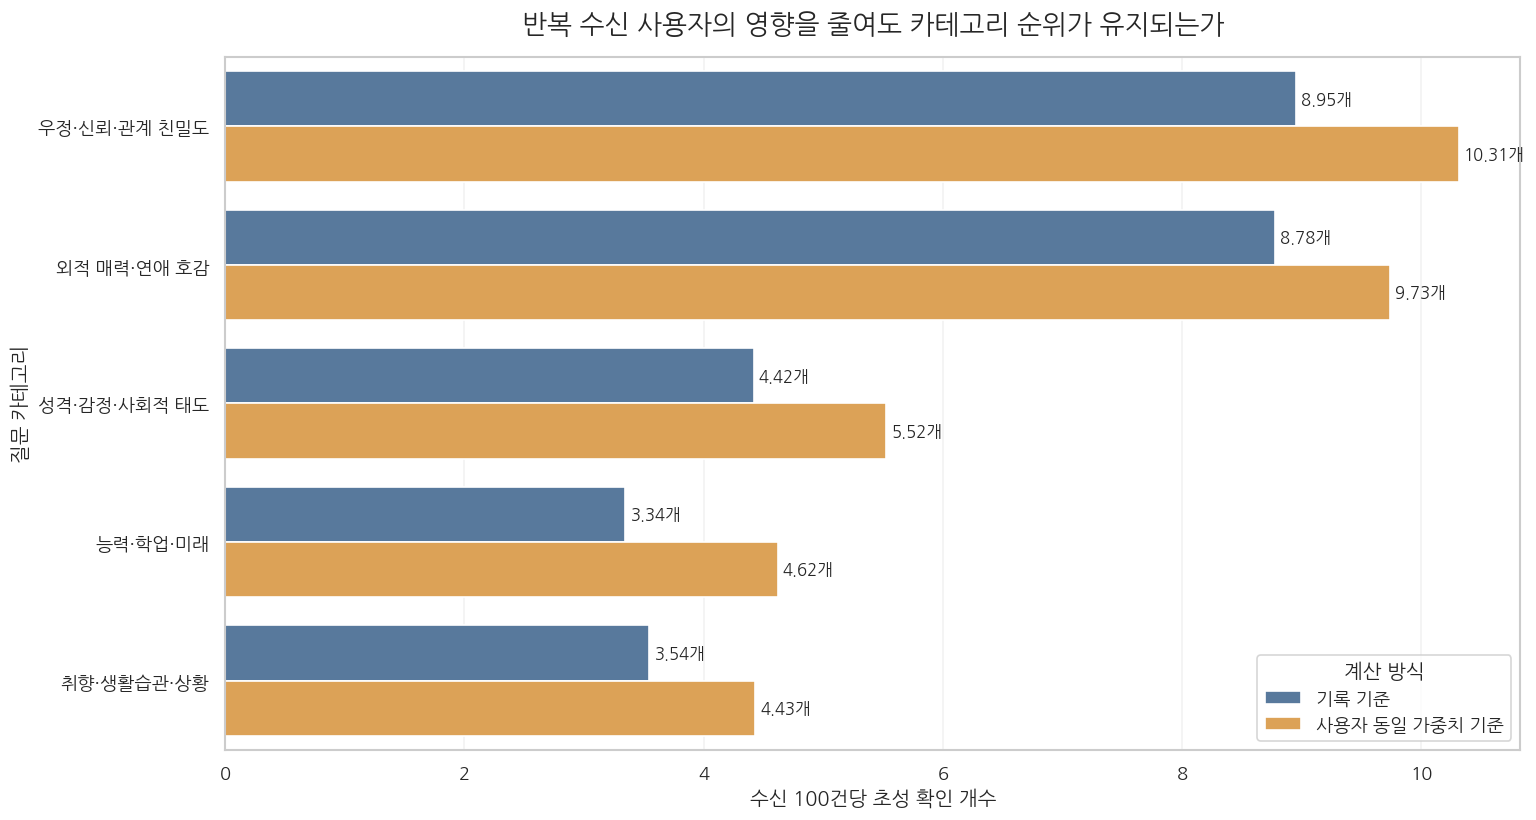

In [384]:
# 기록 기준과 사용자 동일 가중치의 초성 확인 효율 비교
weighting_chart = (
    category_reliability_summary[
        [
            "category",
            "opened_initials_per_100_receipts",
            "user_equal_open_efficiency_pct",
        ]
    ]
    .rename(
        columns={
            "category": "질문 카테고리",
            "opened_initials_per_100_receipts": "기록 기준",
            "user_equal_open_efficiency_pct": "사용자 동일 가중치 기준",
        }
    )
    .melt(
        id_vars="질문 카테고리",
        var_name="계산 방식",
        value_name="수신 100건당 초성 확인 개수",
    )
)

category_order_user_equal = (
    category_reliability_summary
    .sort_values(
        "user_equal_open_efficiency_pct",
        ascending=False,
    )["category"]
    .tolist()
)

plt.figure(figsize=(13, 7))
ax = sns.barplot(
    data=weighting_chart,
    y="질문 카테고리",
    x="수신 100건당 초성 확인 개수",
    hue="계산 방식",
    order=category_order_user_equal,
    palette={
        "기록 기준": "#4C78A8",
        "사용자 동일 가중치 기준": "#F2A541",
    },
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f개",
        padding=3,
        fontsize=10,
    )

ax.set_title(
    "반복 수신 사용자의 영향을 줄여도 카테고리 순위가 유지되는가",
    fontsize=16,
    pad=15,
)
ax.set_xlabel("수신 100건당 초성 확인 개수")
ax.set_ylabel("질문 카테고리")
ax.legend(title="계산 방식")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


### 6-3. 월별 초성 확인 행동과 순위의 안정성

In [385]:
# 월별 안정성 분석을 위한 기준값
MIN_MONTHLY_RECEIPTS = 100

monthly_reliability_base = (
    category_spend_analysis[
        [
            "category",
            "chosen_user_id",
            "created_at",
            "opened_times_clean",
            "초성_확인_여부",
        ]
    ]
    .dropna(subset=["category", "created_at"])
    .copy()
)

monthly_reliability_base["analysis_month"] = (
    pd.to_datetime(
        monthly_reliability_base["created_at"],
        errors="coerce",
    )
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_category_metrics = (
    monthly_reliability_base
    .groupby(
        ["analysis_month", "category"],
        observed=True,
    )
    .agg(
        receipt_records=("chosen_user_id", "size"),
        unique_receivers=("chosen_user_id", "nunique"),
        opened_records=("초성_확인_여부", "sum"),
        total_opened_initials=("opened_times_clean", "sum"),
    )
    .reset_index()
)

monthly_category_metrics["open_rate_pct"] = (
    monthly_category_metrics["opened_records"]
    / monthly_category_metrics["receipt_records"]
    * 100
)
monthly_category_metrics["opened_initials_per_100_receipts"] = (
    monthly_category_metrics["total_opened_initials"]
    / monthly_category_metrics["receipt_records"]
    * 100
)

# 표본이 지나치게 작은 월-카테고리는 순위 비교에서 제외
monthly_category_metrics = (
    monthly_category_metrics.loc[
        monthly_category_metrics["receipt_records"]
        >= MIN_MONTHLY_RECEIPTS
    ]
    .copy()
)

monthly_category_metrics["monthly_efficiency_rank"] = (
    monthly_category_metrics
    .groupby("analysis_month")[
        "opened_initials_per_100_receipts"
    ]
    .rank(method="min", ascending=False)
)

display(
    pd.Series(
        {
            "월별 순위 계산 최소 수신 기록 수": MIN_MONTHLY_RECEIPTS,
            "분석 월 수": monthly_category_metrics["analysis_month"].nunique(),
            "분석 월-카테고리 조합 수": len(monthly_category_metrics),
        },
        name="값",
    ).to_frame()
)


,값
월별 순위 계산 최소 수신 기록 수,100
분석 월 수,7
분석 월-카테고리 조합 수,32


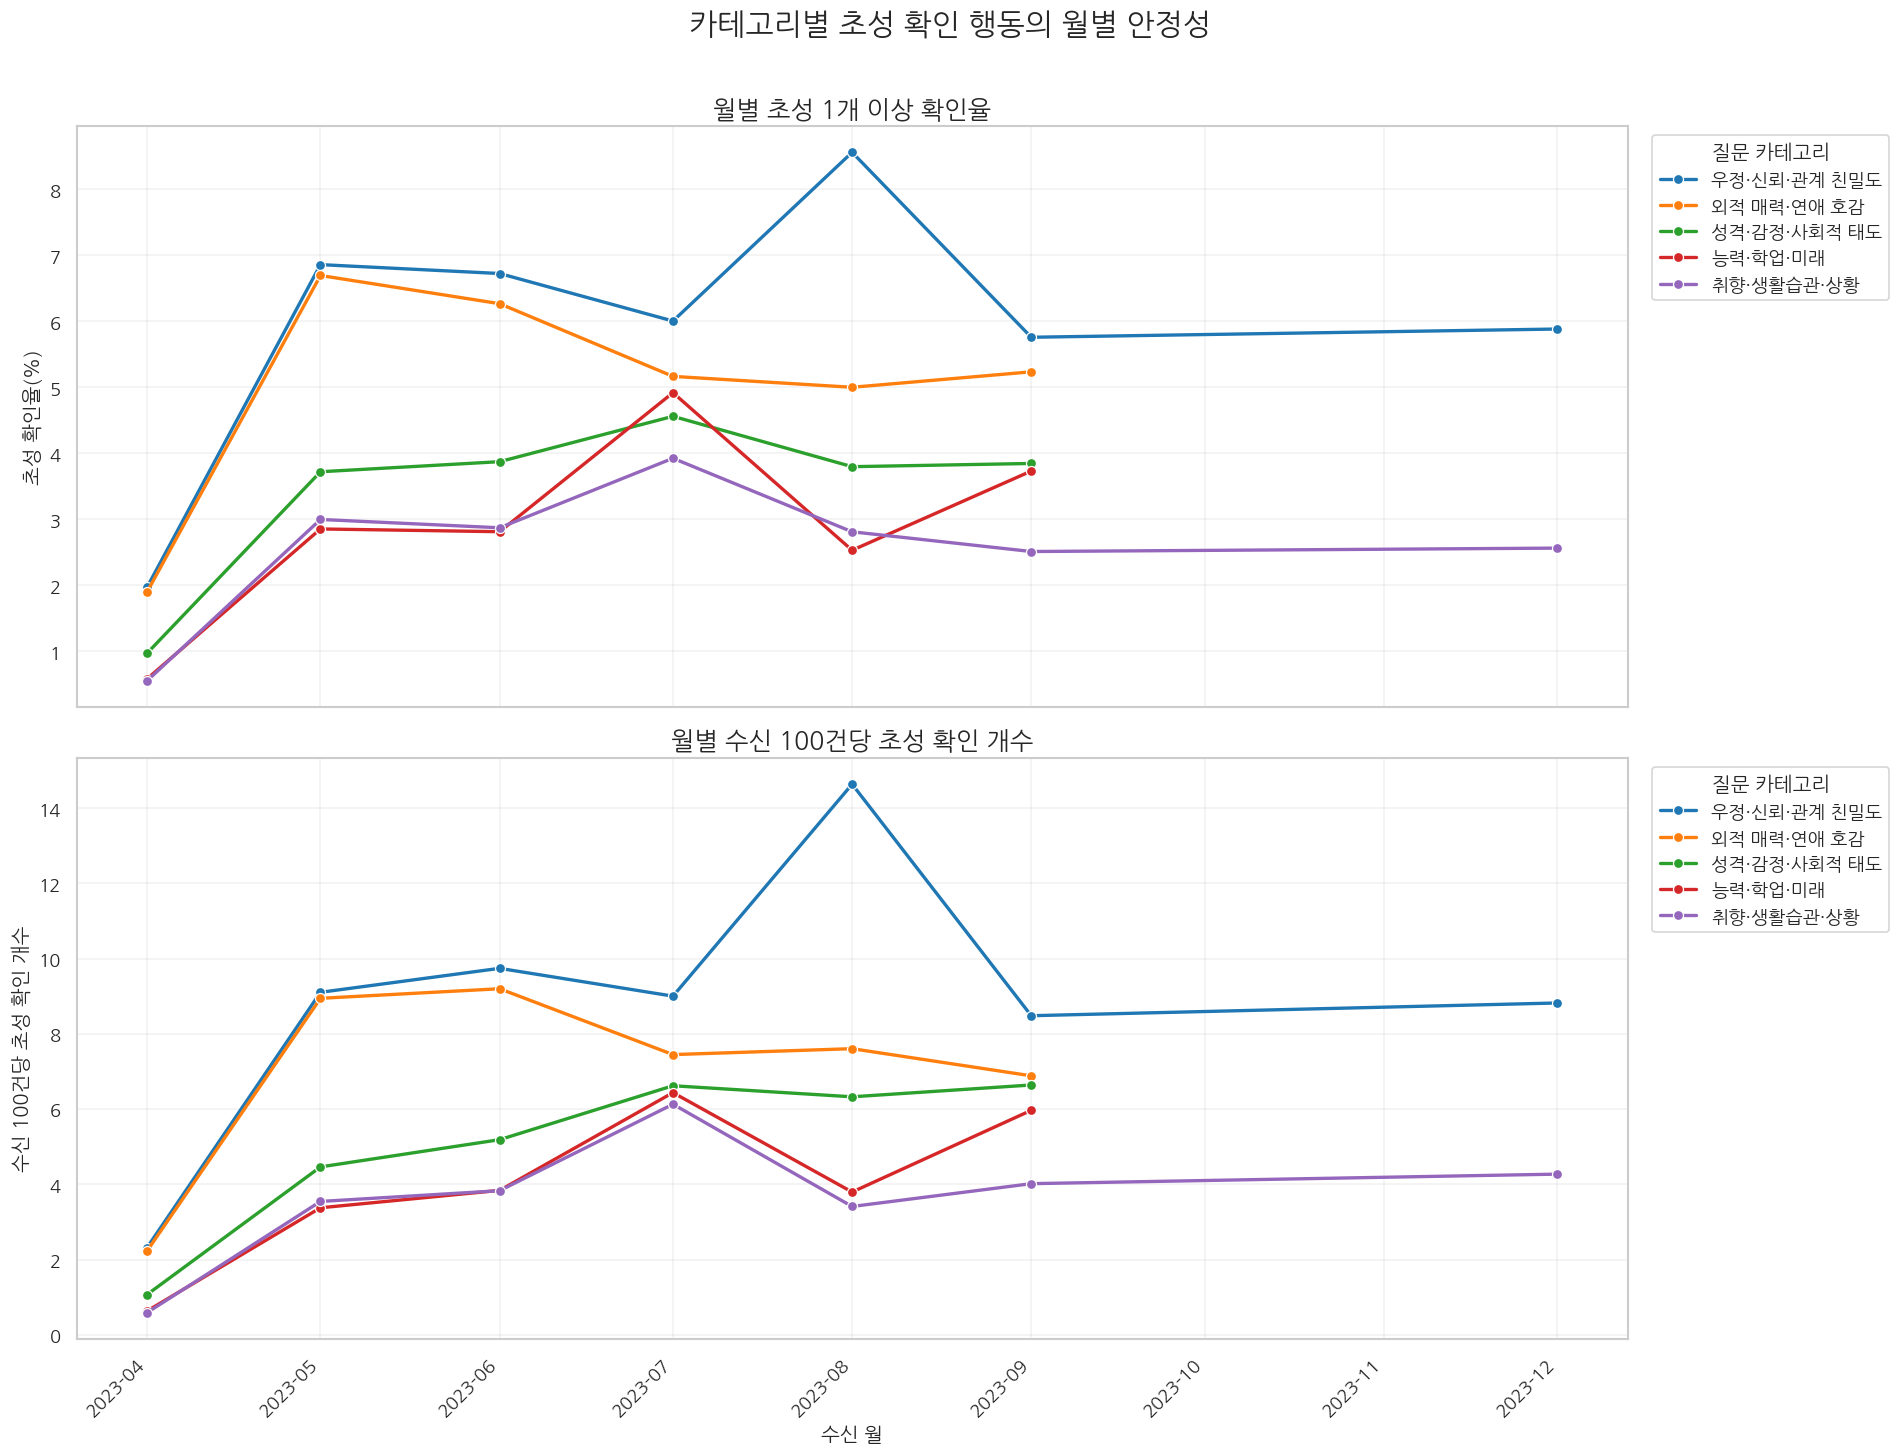

In [386]:
# 카테고리별 월간 추세 시각화
category_palette = dict(
    zip(
        category_order_user_equal,
        sns.color_palette("tab10", n_colors=len(category_order_user_equal)),
    )
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 12),
    sharex=True,
)

sns.lineplot(
    data=monthly_category_metrics,
    x="analysis_month",
    y="open_rate_pct",
    hue="category",
    hue_order=category_order_user_equal,
    palette=category_palette,
    marker="o",
    linewidth=2,
    ax=axes[0],
)
axes[0].set_title("월별 초성 1개 이상 확인율", fontsize=15)
axes[0].set_xlabel("")
axes[0].set_ylabel("초성 확인율(%)")
axes[0].legend(
    title="질문 카테고리",
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
)
axes[0].grid(alpha=0.25)

sns.lineplot(
    data=monthly_category_metrics,
    x="analysis_month",
    y="opened_initials_per_100_receipts",
    hue="category",
    hue_order=category_order_user_equal,
    palette=category_palette,
    marker="o",
    linewidth=2,
    ax=axes[1],
)
axes[1].set_title("월별 수신 100건당 초성 확인 개수", fontsize=15)
axes[1].set_xlabel("수신 월")
axes[1].set_ylabel("수신 100건당 초성 확인 개수")
axes[1].legend(
    title="질문 카테고리",
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
)
axes[1].grid(alpha=0.25)

for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")

fig.suptitle(
    "카테고리별 초성 확인 행동의 월별 안정성",
    fontsize=18,
    y=1.01,
)

plt.tight_layout()
plt.show()


In [387]:
# 월별 카테고리 순위가 얼마나 유지됐는지 요약
monthly_rank_summary = (
    monthly_category_metrics
    .groupby("category", observed=True)
    .agg(
        months_observed=("analysis_month", "nunique"),
        median_efficiency_rank=("monthly_efficiency_rank", "median"),
        mean_efficiency_rank=("monthly_efficiency_rank", "mean"),
        best_rank=("monthly_efficiency_rank", "min"),
        worst_rank=("monthly_efficiency_rank", "max"),
        top_1_months=(
            "monthly_efficiency_rank",
            lambda values: values.eq(1).sum(),
        ),
        top_2_months=(
            "monthly_efficiency_rank",
            lambda values: values.le(2).sum(),
        ),
    )
    .reset_index()
)

monthly_rank_display = (
    monthly_rank_summary.rename(
        columns={
            "category": "질문 카테고리",
            "months_observed": "순위를 계산한 월 수",
            "median_efficiency_rank": "월별 순위 중앙값",
            "mean_efficiency_rank": "월별 평균 순위",
            "best_rank": "가장 높은 순위",
            "worst_rank": "가장 낮은 순위",
            "top_1_months": "1위인 월 수",
            "top_2_months": "상위 2위 이내인 월 수",
        }
    )
    .sort_values(
        ["월별 순위 중앙값", "월별 평균 순위"],
        ascending=True,
    )
)

rank_numeric_columns = monthly_rank_display.select_dtypes(
    include="number"
).columns
monthly_rank_display[rank_numeric_columns] = (
    monthly_rank_display[rank_numeric_columns].round(2)
)

display(monthly_rank_display)


,질문 카테고리,순위를 계산한 월 수,월별 순위 중앙값,월별 평균 순위,가장 높은 순위,가장 낮은 순위,1위인 월 수,상위 2위 이내인 월 수
3,우정·신뢰·관계 친밀도,7,1.0,1.0,1.0,1.0,7.0,7.0
2,외적 매력·연애 호감,6,2.0,2.0,2.0,2.0,0.0,6.0
1,성격·감정·사회적 태도,6,3.0,3.0,3.0,3.0,0.0,0.0
0,능력·학업·미래,6,4.0,4.17,4.0,5.0,0.0,0.0
4,취향·생활습관·상황,7,5.0,4.43,2.0,5.0,0.0,1.0


### 6-4. 수신량 구성을 보정한 초성 확인과 후속 결제의 연관성

In [388]:
# 각 초기 수신량 구간이 전체 분석 사용자에서 차지하는 비중 계산
payment_sensitivity_base = fixed_window_summary.copy()

receipt_stratum_weights = (
    payment_sensitivity_base
    .groupby(
        "초기 수신량 구간",
        observed=True,
    )["사용자_수"]
    .sum()
    .rename("구간_전체_사용자_수")
    .reset_index()
)
receipt_stratum_weights["구간_가중치"] = (
    receipt_stratum_weights["구간_전체_사용자_수"]
    / receipt_stratum_weights["구간_전체_사용자_수"].sum()
)

payment_sensitivity_base = (
    payment_sensitivity_base.merge(
        receipt_stratum_weights,
        on="초기 수신량 구간",
        how="left",
        validate="many_to_one",
    )
)

payment_sensitivity_base["전체_상품_구간별_결제율"] = (
    payment_sensitivity_base["전체_상품_후속_결제자_수"]
    / payment_sensitivity_base["사용자_수"]
)
payment_sensitivity_base["비777_상품_구간별_결제율"] = (
    payment_sensitivity_base["heart_777_외_후속_결제자_수"]
    / payment_sensitivity_base["사용자_수"]
)

# 두 집단 모두 동일한 수신량 분포를 가진다고 가정한 표준화 결제율
standardized_payment_rates = (
    payment_sensitivity_base
    .assign(
        전체_상품_가중_결제율=lambda data: (
            data["전체_상품_구간별_결제율"]
            * data["구간_가중치"]
        ),
        비777_상품_가중_결제율=lambda data: (
            data["비777_상품_구간별_결제율"]
            * data["구간_가중치"]
        ),
    )
    .groupby("초기 초성 확인 경험", observed=True)
    .agg(
        standardized_any_payment_rate=(
            "전체_상품_가중_결제율",
            "sum",
        ),
        standardized_non_777_payment_rate=(
            "비777_상품_가중_결제율",
            "sum",
        ),
        observed_users=("사용자_수", "sum"),
    )
    .reset_index()
)

standardized_payment_rates[
    "standardized_any_payment_rate_pct"
] = standardized_payment_rates[
    "standardized_any_payment_rate"
] * 100
standardized_payment_rates[
    "standardized_non_777_payment_rate_pct"
] = standardized_payment_rates[
    "standardized_non_777_payment_rate"
] * 100

standardized_payment_long = (
    standardized_payment_rates[
        [
            "초기 초성 확인 경험",
            "standardized_any_payment_rate_pct",
            "standardized_non_777_payment_rate_pct",
        ]
    ]
    .melt(
        id_vars="초기 초성 확인 경험",
        var_name="payment_metric",
        value_name="standardized_rate_pct",
    )
)

payment_metric_name_map = {
    "standardized_any_payment_rate_pct": "전체 상품",
    "standardized_non_777_payment_rate_pct": "heart.777 외 상품",
}
standardized_payment_long["결제 상품 기준"] = (
    standardized_payment_long["payment_metric"]
    .map(payment_metric_name_map)
)

standardized_payment_pivot = (
    standardized_payment_long.pivot(
        index="결제 상품 기준",
        columns="초기 초성 확인 경험",
        values="standardized_rate_pct",
    )
    .reset_index()
)

standardized_payment_pivot["차이(%p)"] = (
    standardized_payment_pivot["초성 확인 있음"]
    - standardized_payment_pivot["초성 확인 없음"]
)
standardized_payment_pivot["배율"] = np.where(
    standardized_payment_pivot["초성 확인 없음"].gt(0),
    standardized_payment_pivot["초성 확인 있음"]
    / standardized_payment_pivot["초성 확인 없음"],
    np.nan,
)

standardized_payment_display = (
    standardized_payment_pivot.rename(
        columns={
            "초성 확인 없음": "초성 확인 없음 표준화 결제율(%)",
            "초성 확인 있음": "초성 확인 있음 표준화 결제율(%)",
        }
    )
    .round(2)
)

display(standardized_payment_display)


초기 초성 확인 경험,결제 상품 기준,초성 확인 없음 표준화 결제율(%),초성 확인 있음 표준화 결제율(%),차이(%p),배율
0,heart.777 외 상품,0.24,0.75,0.51,3.08
1,전체 상품,0.67,1.45,0.79,2.19


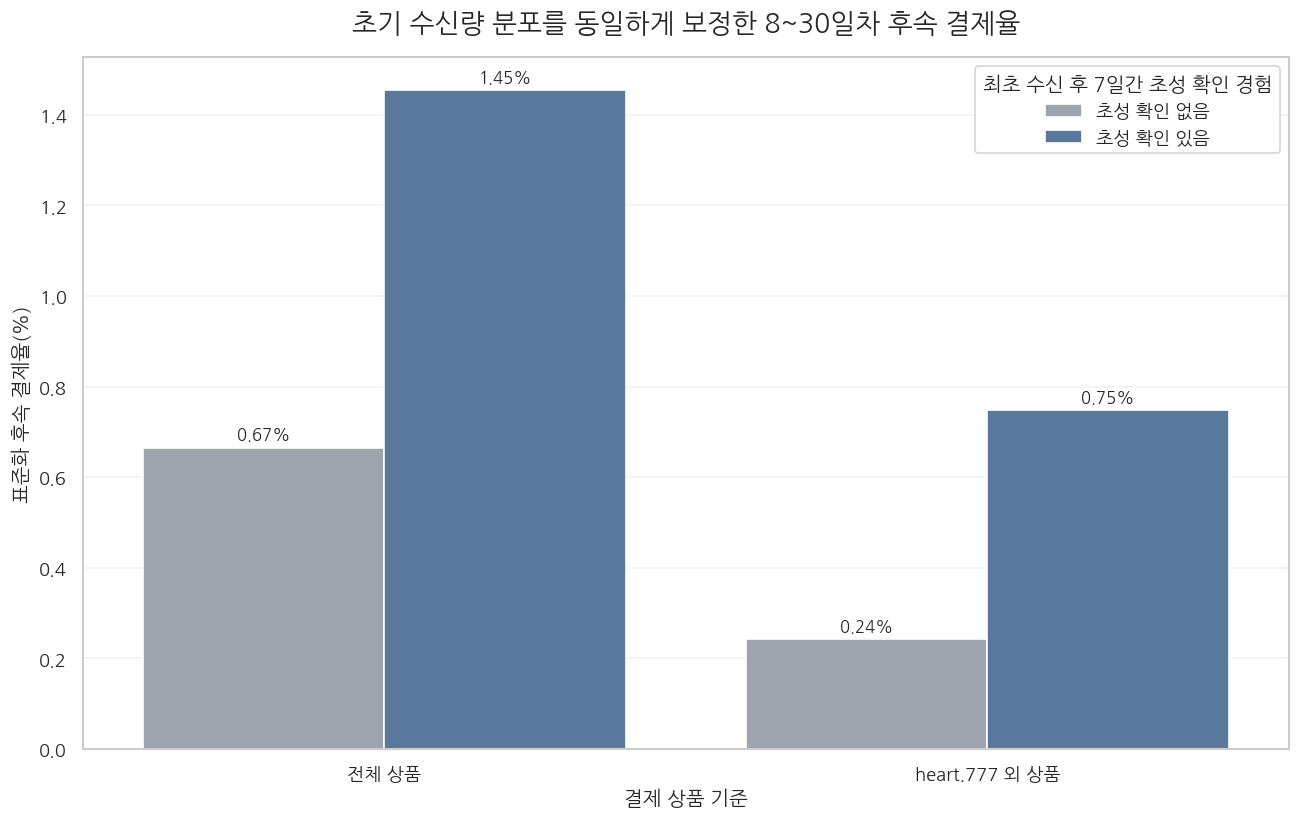

In [389]:
# 수신량 분포를 동일하게 맞춘 후의 후속 결제율 비교
plt.figure(figsize=(11, 7))
ax = sns.barplot(
    data=standardized_payment_long,
    x="결제 상품 기준",
    y="standardized_rate_pct",
    hue="초기 초성 확인 경험",
    hue_order=["초성 확인 없음", "초성 확인 있음"],
    palette={
        "초성 확인 없음": "#9CA3AF",
        "초성 확인 있음": "#4C78A8",
    },
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=10,
    )

ax.set_title(
    "초기 수신량 분포를 동일하게 보정한 8~30일차 후속 결제율",
    fontsize=16,
    pad=15,
)
ax.set_xlabel("결제 상품 기준")
ax.set_ylabel("표준화 후속 결제율(%)")
ax.legend(title="최초 수신 후 7일간 초성 확인 경험")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## 7. 카테고리별 호기심·하트 소비 기회 종합

카테고리별 결제를 직접 귀속하지 않고, 다음 세 단계의 증거를 연결해 최종적으로 해석한다.

1. **카테고리 → 초성 확인:** 어떤 카테고리가 실제 초성 확인 행동을 많이 만드는가?
2. **카테고리 → 후속 투표:** 해당 카테고리를 받은 뒤 서비스 핵심 행동으로 이어지는가?
3. **초성 확인 → 후속 결제:** 초성 확인 경험이 있는 사용자가 이후 결제를 더 많이 경험하는가?

따라서 카테고리별 수익을 직접 계산하는 것이 아니라, **하트 소비 수요를 만드는 질문 카테고리와 그 수요가 결제로 이어질 가능성**을 분리해 본다.

### 7-1. 카테고리별 최종 근거 테이블 생성

In [390]:
# 7일 이내 후속 투표 참여율만 최종 종합표에 연결
future_vote_7d = (
    category_future_vote_summary.loc[
        category_future_vote_summary["관찰 기간"].eq("7일 이내"),
        [
            "category",
            "record_weighted_rate_pct",
            "user_equal_weight_rate_pct",
        ],
    ]
    .rename(
        columns={
            "record_weighted_rate_pct": "future_vote_7d_record_pct",
            "user_equal_weight_rate_pct": "future_vote_7d_user_equal_pct",
        }
    )
)

# 초성 확인, 신뢰도 검증, 시간 안정성과 후속 투표 결과 결합
category_opportunity_summary = (
    category_spend_summary
    .merge(
        category_user_equal_summary[
            [
                "category",
                "user_equal_open_rate_pct",
                "user_equal_open_efficiency_pct",
                "user_equal_open_efficiency_ci_low_pct",
                "user_equal_open_efficiency_ci_high_pct",
            ]
        ],
        on="category",
        how="left",
        validate="one_to_one",
    )
    .merge(
        monthly_rank_summary,
        on="category",
        how="left",
        validate="one_to_one",
    )
    .merge(
        future_vote_7d,
        on="category",
        how="left",
        validate="one_to_one",
    )
)

# 전체 수신과 전체 초성 확인에서 각 카테고리가 차지하는 비중
category_opportunity_summary["receipt_share_pct"] = (
    category_opportunity_summary["receipt_records"]
    / category_opportunity_summary["receipt_records"].sum()
    * 100
)
category_opportunity_summary["opened_initial_share_pct"] = (
    category_opportunity_summary["total_opened_initials"]
    / category_opportunity_summary["total_opened_initials"].sum()
    * 100
)
category_opportunity_summary["contribution_lift_pp"] = (
    category_opportunity_summary["opened_initial_share_pct"]
    - category_opportunity_summary["receipt_share_pct"]
)


### 7-2. 초성 확인 효율과 전체 기여도를 기준으로 기회 유형 분류

In [391]:
# 전체 카테고리를 합친 수신 100건당 초성 확인 개수
overall_open_efficiency = (
    category_opportunity_summary["total_opened_initials"].sum()
    / category_opportunity_summary["receipt_records"].sum()
    * 100
)

# 카테고리가 5개라면 균등 기여도 기준은 20%
average_contribution_share = (
    100 / category_opportunity_summary["category"].nunique()
)

high_efficiency = (
    category_opportunity_summary[
        "opened_initials_per_100_receipts"
    ]
    >= overall_open_efficiency
)
high_contribution = (
    category_opportunity_summary["opened_initial_share_pct"]
    >= average_contribution_share
)

category_opportunity_summary["opportunity_type"] = np.select(
    [
        high_efficiency & high_contribution,
        high_efficiency & ~high_contribution,
        ~high_efficiency & high_contribution,
    ],
    [
        "핵심 강화",
        "노출 확대 검토",
        "초성 확인 효율 개선",
    ],
    default="상대적 후순위",
)

display(
    pd.Series(
        {
            "전체 수신 100건당 초성 확인 개수": (
                round(overall_open_efficiency, 2)
            ),
            "카테고리 균등 기여도 기준(%)": (
                round(average_contribution_share, 2)
            ),
        },
        name="기준값",
    ).to_frame()
)


,기준값
전체 수신 100건당 초성 확인 개수,6.07
카테고리 균등 기여도 기준(%),20.00


### 7-3. 카테고리별 호기심·추가 행동 종합 결과표

In [392]:
final_category_evidence = (
    category_opportunity_summary[
        [
            "category",
            "receipt_records",
            "unique_receivers",
            "opened_record_rate_pct",
            "opened_initials_per_100_receipts",
            "user_equal_open_efficiency_pct",
            "user_equal_open_efficiency_ci_low_pct",
            "user_equal_open_efficiency_ci_high_pct",
            "receipt_share_pct",
            "opened_initial_share_pct",
            "contribution_lift_pp",
            "months_observed",
            "top_2_months",
            "future_vote_7d_record_pct",
            "future_vote_7d_user_equal_pct",
            "opportunity_type",
        ]
    ]
    .rename(
        columns={
            "category": "질문 카테고리",
            "receipt_records": "수신 기록 수(건)",
            "unique_receivers": "고유 수신자 수(명)",
            "opened_record_rate_pct": "초성 1개 이상 확인율(%)",
            "opened_initials_per_100_receipts": "기록 기준 수신 100건당 초성 확인 개수",
            "user_equal_open_efficiency_pct": "사용자 동일 가중치 수신 100건당 초성 확인 개수",
            "user_equal_open_efficiency_ci_low_pct": "사용자 동일 가중치 효율 95% 신뢰구간 하한",
            "user_equal_open_efficiency_ci_high_pct": "사용자 동일 가중치 효율 95% 신뢰구간 상한",
            "receipt_share_pct": "전체 수신 비중(%)",
            "opened_initial_share_pct": "전체 초성 확인 기여도(%)",
            "contribution_lift_pp": "수신 비중 대비 초성 확인 기여도 차이(%p)",
            "months_observed": "월별 순위 계산 월 수",
            "top_2_months": "초성 확인 효율 상위 2위인 월 수",
            "future_vote_7d_record_pct": "수신 후 7일 내 투표 참여율·기록 기준(%)",
            "future_vote_7d_user_equal_pct": "수신 후 7일 내 투표 참여율·사용자 동일 가중치(%)",
            "opportunity_type": "기회 유형",
        }
    )
    .sort_values(
        [
            "전체 초성 확인 기여도(%)",
            "사용자 동일 가중치 수신 100건당 초성 확인 개수",
        ],
        ascending=False,
    )
)

final_numeric_columns = final_category_evidence.select_dtypes(
    include="number"
).columns
final_category_evidence[final_numeric_columns] = (
    final_category_evidence[final_numeric_columns].round(2)
)

display(final_category_evidence)


,질문 카테고리,수신 기록 수(건),고유 수신자 수(명),초성 1개 이상 확인율(%),기록 기준 수신 100건당 초성 확인 개수,사용자 동일 가중치 수신 100건당 초성 확인 개수,사용자 동일 가중치 효율 95% 신뢰구간 하한,사용자 동일 가중치 효율 95% 신뢰구간 상한,전체 수신 비중(%),전체 초성 확인 기여도(%),수신 비중 대비 초성 확인 기여도 차이(%p),월별 순위 계산 월 수,초성 확인 효율 상위 2위인 월 수,수신 후 7일 내 투표 참여율·기록 기준(%),수신 후 7일 내 투표 참여율·사용자 동일 가중치(%),기회 유형
2,외적 매력·연애 호감,293029,12109,6.54,8.78,9.73,9.30,10.16,24.33,35.18,10.85,6,6.0,72.88,32.17,핵심 강화
3,우정·신뢰·관계 친밀도,244551,11477,6.7,8.95,10.31,9.87,10.76,20.31,29.93,9.63,7,7.0,72.14,34.23,핵심 강화
1,성격·감정·사회적 태도,263483,11936,3.66,4.42,5.52,5.20,5.85,21.88,15.93,-5.95,6,0.0,74.25,33.44,상대적 후순위
0,능력·학업·미래,213111,11479,2.8,3.34,4.62,4.32,4.92,17.7,9.75,-7.95,6,0.0,72.94,34.26,상대적 후순위
4,취향·생활습관·상황,190054,11328,2.95,3.54,4.43,4.14,4.73,15.78,9.21,-6.57,7,1.0,70.9,33.26,상대적 후순위


### 7-4. 초성 확인 효율과 전체 기여도 기회 매트릭스

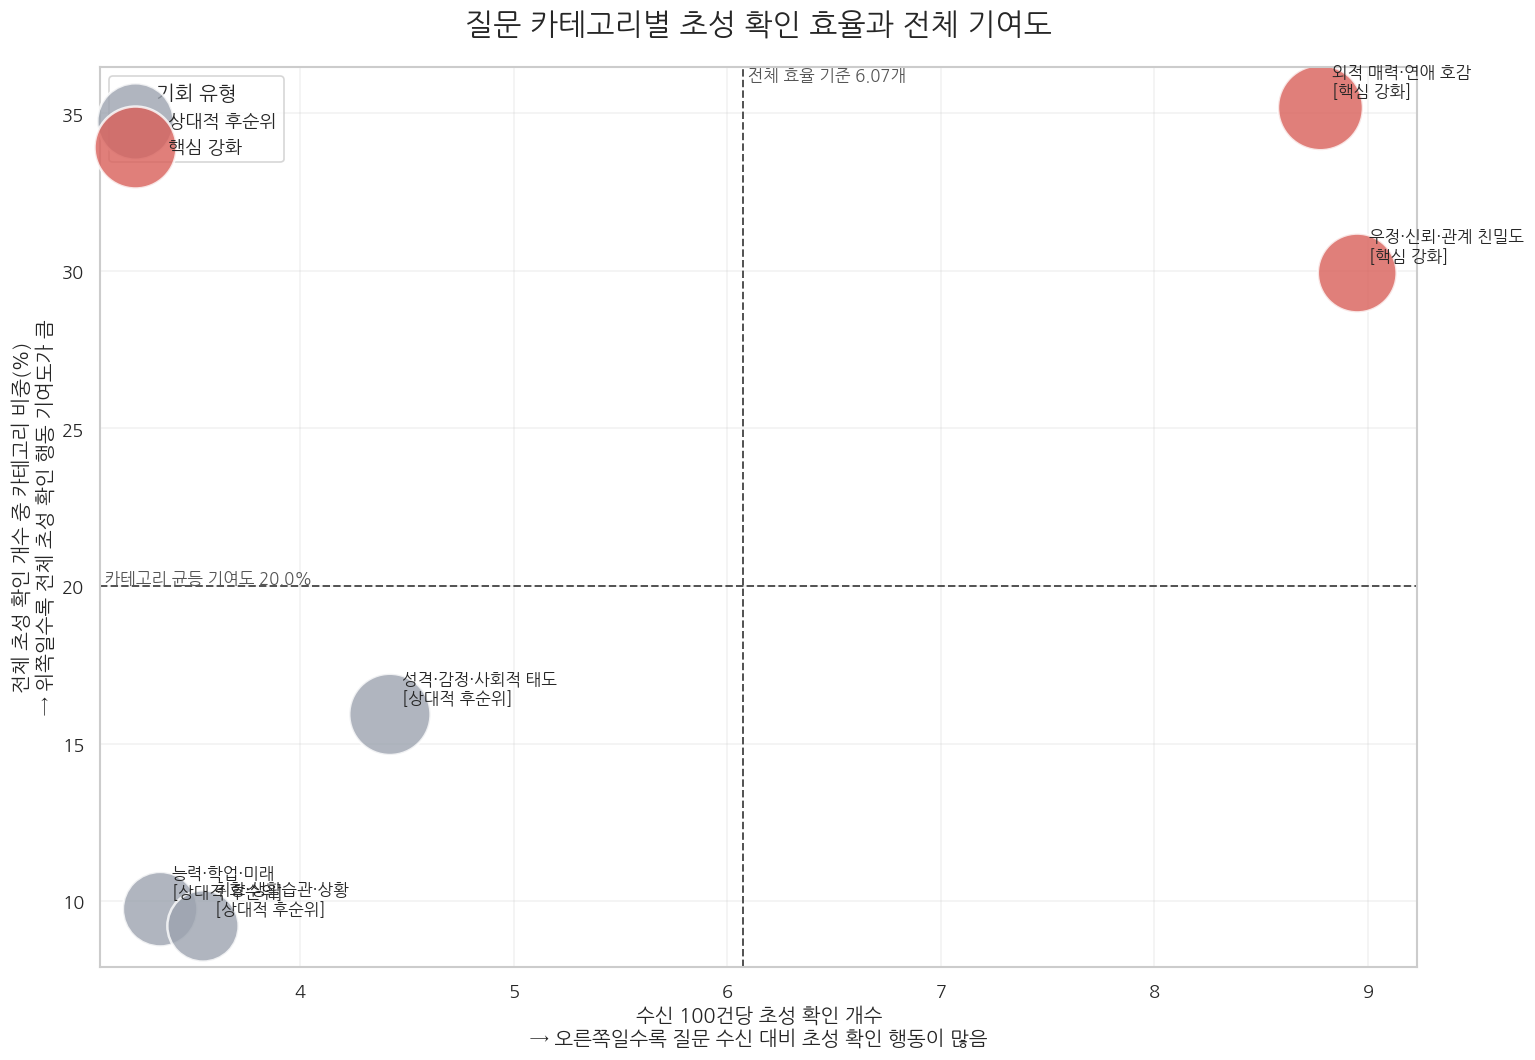

In [393]:
fig, ax = plt.subplots(figsize=(13, 9))

# 버블 크기는 카테고리별 수신 기록 수를 나타냄
category_opportunity_summary["bubble_size"] = (
    category_opportunity_summary["receipt_records"]
    / category_opportunity_summary["receipt_records"].max()
    * 2200
    + 400
)

color_map = {
    "핵심 강화": "#D95F59",
    "노출 확대 검토": "#59A14F",
    "초성 확인 효율 개선": "#F2A541",
    "상대적 후순위": "#9CA3AF",
}

for opportunity_type, group in category_opportunity_summary.groupby(
    "opportunity_type",
    observed=True,
):
    ax.scatter(
        group["opened_initials_per_100_receipts"],
        group["opened_initial_share_pct"],
        s=group["bubble_size"],
        c=color_map[opportunity_type],
        alpha=0.8,
        edgecolors="white",
        linewidths=1.5,
        label=opportunity_type,
    )

ax.axvline(
    overall_open_efficiency,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
)
ax.axhline(
    average_contribution_share,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
)

for _, row in category_opportunity_summary.iterrows():
    ax.annotate(
        f"{row['category']}\n[{row['opportunity_type']}]",
        (
            row["opened_initials_per_100_receipts"],
            row["opened_initial_share_pct"],
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10,
    )

ax.set_title(
    "질문 카테고리별 초성 확인 효율과 전체 기여도",
    fontsize=18,
    pad=20,
)
ax.set_xlabel(
    "수신 100건당 초성 확인 개수\n"
    "→ 오른쪽일수록 질문 수신 대비 초성 확인 행동이 많음",
    fontsize=12,
)
ax.set_ylabel(
    "전체 초성 확인 개수 중 카테고리 비중(%)\n"
    "→ 위쪽일수록 전체 초성 확인 행동 기여도가 큼",
    fontsize=12,
)
ax.legend(title="기회 유형", loc="best")
ax.grid(alpha=0.25)

ax.text(
    overall_open_efficiency,
    ax.get_ylim()[1],
    f" 전체 효율 기준 {overall_open_efficiency:.2f}개",
    ha="left",
    va="top",
    fontsize=10,
    color="#555555",
)
ax.text(
    ax.get_xlim()[0],
    average_contribution_share,
    f" 카테고리 균등 기여도 {average_contribution_share:.1f}%",
    ha="left",
    va="bottom",
    fontsize=10,
    color="#555555",
)

plt.tight_layout()
plt.show()


### 7-5. 카테고리 지표와 후속 결제 지표를 분리한 최종 결론

In [394]:
# 실제 실행 결과를 바탕으로 발표용 핵심 수치를 자동 출력
top_efficiency_row = category_opportunity_summary.sort_values(
    "user_equal_open_efficiency_pct",
    ascending=False,
).iloc[0]

top_contribution_row = category_opportunity_summary.sort_values(
    "opened_initial_share_pct",
    ascending=False,
).iloc[0]

top_future_vote_row = category_opportunity_summary.sort_values(
    "future_vote_7d_user_equal_pct",
    ascending=False,
).iloc[0]

payment_result_lookup = standardized_payment_display.set_index(
    "결제 상품 기준"
)
all_product_payment_gap = payment_result_lookup.loc[
    "전체 상품",
    "차이(%p)",
]
all_product_payment_ratio = payment_result_lookup.loc[
    "전체 상품",
    "배율",
]

print(
    "1. 사용자 동일 가중치 기준 초성 확인 효율이 가장 높은 카테고리:",
    top_efficiency_row["category"],
    f"({top_efficiency_row['user_equal_open_efficiency_pct']:.2f}개/수신 100건)",
)
print(
    "2. 전체 초성 확인 행동 기여도가 가장 높은 카테고리:",
    top_contribution_row["category"],
    f"({top_contribution_row['opened_initial_share_pct']:.2f}%)",
)
print(
    "3. 수신 후 7일 내 사용자 동일 가중치 투표 참여율이 가장 높은 카테고리:",
    top_future_vote_row["category"],
    f"({top_future_vote_row['future_vote_7d_user_equal_pct']:.2f}%)",
)
print(
    "4. 수신량 보정 후 초성 확인 경험자와 미경험자의 전체 상품 후속 결제율 차이:",
    f"{all_product_payment_gap:.2f}%p",
    f"({all_product_payment_ratio:.2f}배)",
)
print(
    "5. 주의: 4번은 초성 확인과 후속 결제의 연관성이며,"
    " 특정 카테고리가 결제를 직접 유발했다는 뜻은 아닙니다."
)


1. 사용자 동일 가중치 기준 초성 확인 효율이 가장 높은 카테고리: 우정·신뢰·관계 친밀도 (10.31개/수신 100건)
2. 전체 초성 확인 행동 기여도가 가장 높은 카테고리: 외적 매력·연애 호감 (35.18%)
3. 수신 후 7일 내 사용자 동일 가중치 투표 참여율이 가장 높은 카테고리: 능력·학업·미래 (34.26%)
4. 수신량 보정 후 초성 확인 경험자와 미경험자의 전체 상품 후속 결제율 차이: 0.79%p (2.19배)
5. 주의: 4번은 초성 확인과 후속 결제의 연관성이며, 특정 카테고리가 결제를 직접 유발했다는 뜻은 아닙니다.


## 최종 해석 원칙

- **카테고리별로 직접 설명할 수 있는 것:** 수신량 대비 초성 확인 행동, 전체 초성 확인 행동에 대한 기여도, 수신 후 후속 투표 참여율
- **사용자 수준에서 보조적으로 설명할 수 있는 것:** 초성 확인 경험이 있는 사용자의 이후 결제 경험률이 더 높은지 여부
- **설명할 수 없는 것:** 하나의 결제를 특정 질문 또는 특정 카테고리 때문에 발생한 결제로 직접 귀속하는 것
- 따라서 최종 제안은 `호기심을 많이 만드는 카테고리 강화 → 초성 확인 행동 확대 → 실제 하트 소비와 결제로 연결되는지 A/B 테스트`의 순서로 제시한다.

# PPT용 차트 뽑기

In [395]:
# ============================================================
# PPT 차트 공통 준비
# ============================================================

sns.set_theme(
    style="whitegrid",
    font="NanumGothic",
)

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

In [396]:
# ------------------------------------------------------------
# 1. 필요한 컬럼 확인
# ------------------------------------------------------------

ppt_required_columns = {
    "category",
    "chosen_user_id",
    "has_read_flag",
    "opened_times",
}

ppt_missing_columns = (
    ppt_required_columns
    - set(category_behavior_base.columns)
)

if ppt_missing_columns:
    raise KeyError(
        "category_behavior_base에 필요한 컬럼이 없습니다: "
        f"{sorted(ppt_missing_columns)}"
    )


# ------------------------------------------------------------
# 2. 발표용 분석 테이블 생성
# 기존 category_behavior_base는 변경하지 않음
# ------------------------------------------------------------

ppt_base = category_behavior_base.copy()

ppt_base["초성 확인 개수"] = pd.to_numeric(
    ppt_base["opened_times"],
    errors="coerce",
)

# opened_times가 0~3인 정상 기록만 사용
ppt_valid_open_count = (
    ppt_base["초성 확인 개수"]
    .between(0, 3)
)

print(
    "초성 확인 개수가 결측이거나 0~3 범위를 벗어나 제외된 기록:",
    f"{(~ppt_valid_open_count).sum():,}건",
)

ppt_base = (
    ppt_base.loc[
        ppt_valid_open_count
        & ppt_base["category"].notna()
    ]
    .copy()
)

ppt_base["초성 확인 개수"] = (
    ppt_base["초성 확인 개수"]
    .astype(int)
)

ppt_base["읽음"] = (
    ppt_base["has_read_flag"]
    .fillna(False)
    .astype(bool)
)

ppt_base["초성 1개 이상 확인"] = (
    ppt_base["초성 확인 개수"]
    .ge(1)
)

ppt_base["읽고 초성 1개 이상 확인"] = (
    ppt_base["읽음"]
    & ppt_base["초성 1개 이상 확인"]
)


# ------------------------------------------------------------
# 3. 카테고리 색상 통일
# ------------------------------------------------------------

ppt_category_colors = {
    "우정·신뢰·관계 친밀도": "#4C78A8",
    "외적 매력·연애 호감": "#E45756",
    "성격·감정·사회적 태도": "#72B7B2",
    "취향·생활습관·상황": "#F2CF5B",
    "능력·학업·미래": "#B279A2",
}

# 새로운 카테고리가 있어도 오류가 나지 않게 색상 추가
ppt_categories = (
    ppt_base["category"]
    .dropna()
    .unique()
    .tolist()
)

ppt_fallback_colors = sns.color_palette(
    "tab10",
    n_colors=len(ppt_categories),
)

for category, color in zip(
    ppt_categories,
    ppt_fallback_colors,
):
    ppt_category_colors.setdefault(
        category,
        color,
    )


# ------------------------------------------------------------
# 4. 페이지 4와 부록에서 사용할 카테고리 요약표
# ------------------------------------------------------------

ppt_category_summary = (
    ppt_base
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        수신_기록_수=(
            "초성 확인 개수",
            "size",
        ),
        총_초성_확인_개수=(
            "초성 확인 개수",
            "sum",
        ),
    )
    .reset_index()
)

ppt_category_summary[
    "수신 100건당 초성 확인 개수"
] = (
    ppt_category_summary["총_초성_확인_개수"]
    / ppt_category_summary["수신_기록_수"]
    * 100
)

ppt_category_summary[
    "전체 초성 확인 중 비중(%)"
] = (
    ppt_category_summary["총_초성_확인_개수"]
    / ppt_category_summary[
        "총_초성_확인_개수"
    ].sum()
    * 100
)

초성 확인 개수가 결측이거나 0~3 범위를 벗어나 제외된 기록: 0건


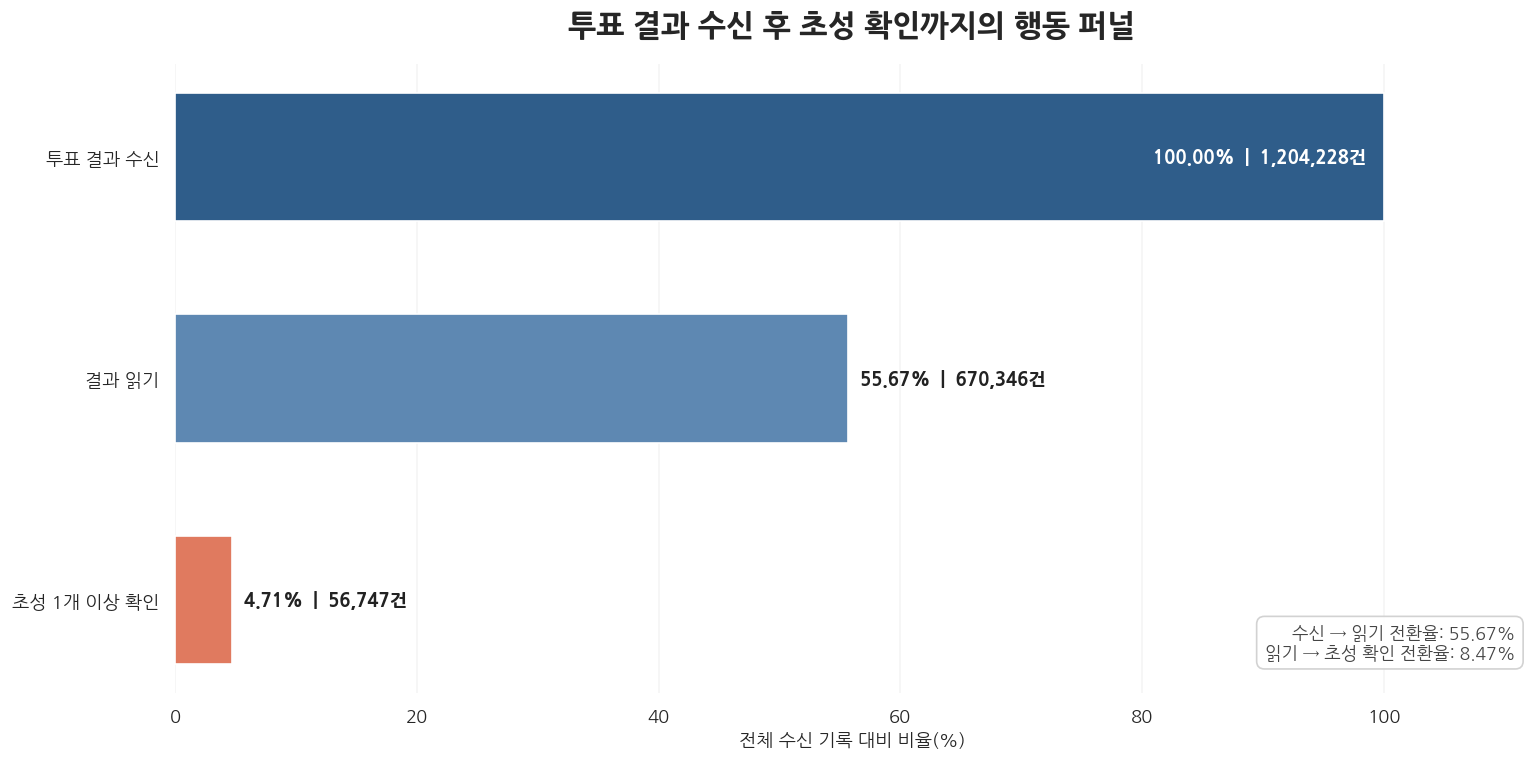

In [397]:
# ============================================================
# 페이지 1. 투표 결과 수신 → 읽기 → 초성 확인 퍼널
# ============================================================

# 단계별 기록 수 계산
ppt_received_count = len(ppt_base)

ppt_read_count = int(
    ppt_base["읽음"].sum()
)

ppt_read_and_open_count = int(
    ppt_base[
        "읽고 초성 1개 이상 확인"
    ].sum()
)

ppt_funnel = pd.DataFrame(
    {
        "단계": [
            "투표 결과 수신",
            "결과 읽기",
            "초성 1개 이상 확인",
        ],
        "기록 수": [
            ppt_received_count,
            ppt_read_count,
            ppt_read_and_open_count,
        ],
    }
)

# 모든 단계의 비율을 최초 수신 기록을 분모로 계산
ppt_funnel[
    "전체 수신 대비 비율(%)"
] = (
    ppt_funnel["기록 수"]
    / ppt_received_count
    * 100
)

# 단계 사이의 조건부 전환율
ppt_read_conversion = (
    ppt_read_count
    / ppt_received_count
    * 100
)

ppt_open_conversion_among_read = (
    ppt_read_and_open_count
    / ppt_read_count
    * 100
    if ppt_read_count > 0
    else np.nan
)


# ------------------------------------------------------------
# 차트
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 6.5)
)

ppt_funnel_colors = [
    "#2F5D8A",
    "#5E88B2",
    "#E07A5F",
]

bars = ax.barh(
    ppt_funnel["단계"],
    ppt_funnel[
        "전체 수신 대비 비율(%)"
    ],
    color=ppt_funnel_colors,
    height=0.58,
)

ax.invert_yaxis()

# 비율과 기록 수 표시
for bar, rate, count in zip(
    bars,
    ppt_funnel[
        "전체 수신 대비 비율(%)"
    ],
    ppt_funnel["기록 수"],
):
    if rate >= 85:
        text_x = rate - 1.5
        text_align = "right"
        text_color = "white"

    else:
        text_x = rate + 1
        text_align = "left"
        text_color = "#222222"

    ax.text(
        text_x,
        bar.get_y()
        + bar.get_height() / 2,
        f"{rate:.2f}%  |  {count:,}건",
        va="center",
        ha=text_align,
        fontsize=11,
        fontweight="bold",
        color=text_color,
    )


# 조건부 전환율 설명 상자
ax.text(
    0.99,
    0.05,
    (
        f"수신 → 읽기 전환율: "
        f"{ppt_read_conversion:.2f}%\n"
        f"읽기 → 초성 확인 전환율: "
        f"{ppt_open_conversion_among_read:.2f}%"
    ),
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10.5,
    color="#444444",
    bbox={
        "boxstyle": "round,pad=0.45",
        "facecolor": "white",
        "edgecolor": "#D0D0D0",
        "alpha": 0.95,
    },
)

ax.set_title(
    "투표 결과 수신 후 초성 확인까지의 행동 퍼널",
    fontsize=18,
    pad=18,
    fontweight="bold",
)

ax.set_xlabel(
    "전체 수신 기록 대비 비율(%)",
    fontsize=11,
)
ax.set_ylabel("")
ax.set_xlim(0, 112)

ax.grid(
    axis="x",
    alpha=0.2,
)
ax.grid(
    axis="y",
    visible=False,
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True,
)

plt.tight_layout()
plt.show()

,질문 카테고리,질문 수신 기록 수(건),고유 수신자 수(명)
0,취향·생활습관·상황,190054,11328
1,능력·학업·미래,213111,11479
2,우정·신뢰·관계 친밀도,244551,11477
3,성격·감정·사회적 태도,263483,11936
4,외적 매력·연애 호감,293029,12109


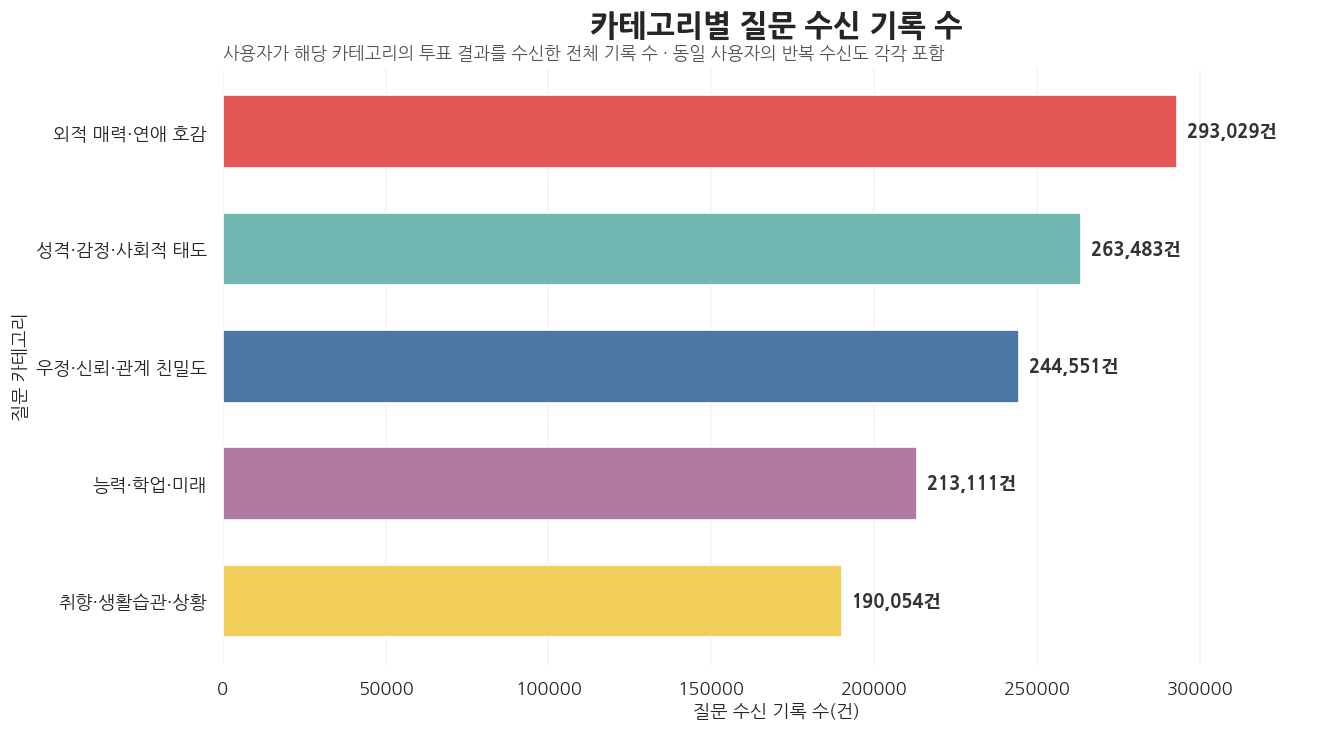

In [398]:
# ============================================================
# 카테고리별 질문 수신 기록 수
# ============================================================

ppt_category_receipt_count = (
    ppt_base
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        질문_수신_기록_수=(
            "category",
            "size",
        ),
        고유_수신자_수=(
            "chosen_user_id",
            "nunique",
        ),
    )
    .reset_index()
    .sort_values(
        "질문_수신_기록_수",
        ascending=True,
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 결과표
# ------------------------------------------------------------

ppt_category_receipt_count_display = (
    ppt_category_receipt_count
    .rename(
        columns={
            "category": "질문 카테고리",
            "질문_수신_기록_수": "질문 수신 기록 수(건)",
            "고유_수신자_수": "고유 수신자 수(명)",
        }
    )
)

display(
    ppt_category_receipt_count_display
)


# ------------------------------------------------------------
# 카테고리별 질문 수신 기록 수 차트
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 7)
)

bars = ax.barh(
    ppt_category_receipt_count["category"],
    ppt_category_receipt_count[
        "질문_수신_기록_수"
    ],
    color=[
        ppt_category_colors[category]
        for category
        in ppt_category_receipt_count["category"]
    ],
    height=0.62,
)


# ------------------------------------------------------------
# 막대 끝에 수신 기록 수 표시
# ------------------------------------------------------------

ppt_receipt_count_max = (
    ppt_category_receipt_count[
        "질문_수신_기록_수"
    ].max()
)

for bar, count in zip(
    bars,
    ppt_category_receipt_count[
        "질문_수신_기록_수"
    ],
):
    ax.text(
        count
        + ppt_receipt_count_max * 0.01,
        bar.get_y()
        + bar.get_height() / 2,
        f"{int(count):,}건",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#333333",
    )


# ------------------------------------------------------------
# 차트 설정
# ------------------------------------------------------------

ax.set_title(
    "카테고리별 질문 수신 기록 수",
    fontsize=18,
    pad=20,
    fontweight="bold",
)

ax.text(
    0,
    1.01,
    (
        "사용자가 해당 카테고리의 투표 결과를 수신한 전체 기록 수"
        " · 동일 사용자의 반복 수신도 각각 포함"
    ),
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10.5,
    color="#555555",
)

ax.set_xlabel(
    "질문 수신 기록 수(건)",
    fontsize=11,
)

ax.set_ylabel(
    "질문 카테고리",
    fontsize=11,
)

ax.set_xlim(
    0,
    ppt_receipt_count_max * 1.16,
)

ax.grid(
    axis="x",
    alpha=0.2,
)

ax.grid(
    axis="y",
    visible=False,
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True,
)

plt.subplots_adjust(
    left=0.25,
    right=0.96,
    top=0.85,
    bottom=0.14,
)

plt.show()

,질문 카테고리,전체 수신 기록 수(건),초성 1개 이상 확인 기록 수(건),초성 1개 이상 확인율(%)
0,취향·생활습관·상황,190054,5614,2.95
1,능력·학업·미래,213111,5961,2.80
2,성격·감정·사회적 태도,263483,9636,3.66
3,우정·신뢰·관계 친밀도,244551,16386,6.70
4,외적 매력·연애 호감,293029,19150,6.54


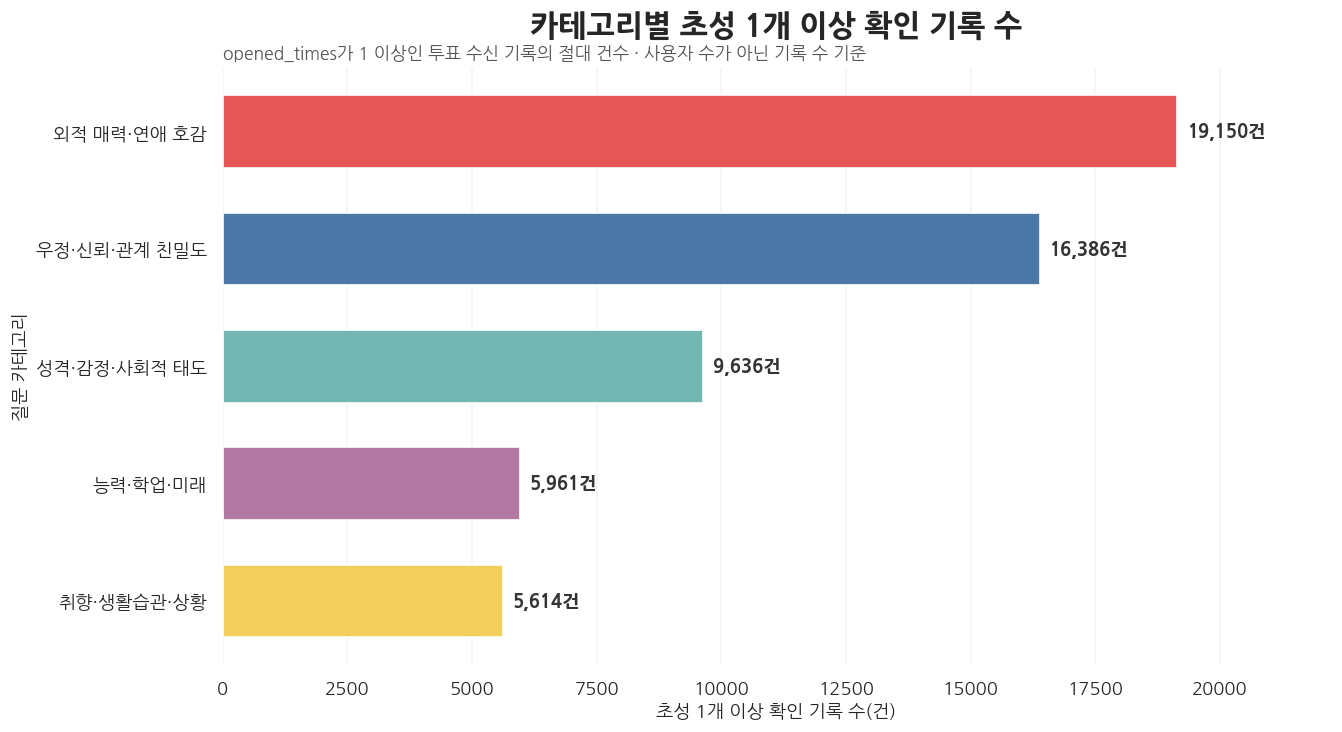

In [399]:
# ============================================================
# 카테고리별 초성 1개 이상 확인 기록 수
# ============================================================

# 카테고리별 전체 수신 기록과 초성 확인 기록 집계
ppt_category_open_count = (
    ppt_base
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        전체_수신_기록_수=(
            "초성 1개 이상 확인",
            "size",
        ),
        초성_1개_이상_확인_기록_수=(
            "초성 1개 이상 확인",
            "sum",
        ),
    )
    .reset_index()
)

# 참고용 초성 확인율 계산
ppt_category_open_count[
    "초성_1개_이상_확인율"
] = (
    ppt_category_open_count[
        "초성_1개_이상_확인_기록_수"
    ]
    / ppt_category_open_count[
        "전체_수신_기록_수"
    ]
    * 100
)

# 건수가 적은 카테고리부터 정렬
ppt_category_open_count = (
    ppt_category_open_count
    .sort_values(
        "초성_1개_이상_확인_기록_수",
        ascending=True,
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 결과표
# ------------------------------------------------------------

ppt_category_open_count_display = (
    ppt_category_open_count
    .rename(
        columns={
            "category": "질문 카테고리",
            "전체_수신_기록_수": "전체 수신 기록 수(건)",
            "초성_1개_이상_확인_기록_수": "초성 1개 이상 확인 기록 수(건)",
            "초성_1개_이상_확인율": "초성 1개 이상 확인율(%)",
        }
    )
    .round(2)
)

display(
    ppt_category_open_count_display
)


# ------------------------------------------------------------
# 가로 막대그래프
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 7)
)

bars = ax.barh(
    ppt_category_open_count["category"],
    ppt_category_open_count[
        "초성_1개_이상_확인_기록_수"
    ],
    color=[
        ppt_category_colors[category]
        for category
        in ppt_category_open_count["category"]
    ],
    height=0.62,
)


# 막대 끝에 건수 표시
for bar, count in zip(
    bars,
    ppt_category_open_count[
        "초성_1개_이상_확인_기록_수"
    ],
):
    ax.text(
        count
        + ppt_category_open_count[
            "초성_1개_이상_확인_기록_수"
        ].max() * 0.01,
        bar.get_y()
        + bar.get_height() / 2,
        f"{int(count):,}건",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#333333",
    )


# ------------------------------------------------------------
# 차트 설정
# ------------------------------------------------------------

ax.set_title(
    "카테고리별 초성 1개 이상 확인 기록 수",
    fontsize=18,
    pad=20,
    fontweight="bold",
)

ax.text(
    0,
    1.01,
    (
        "opened_times가 1 이상인 투표 수신 기록의 절대 건수"
        " · 사용자 수가 아닌 기록 수 기준"
    ),
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10.5,
    color="#555555",
)

ax.set_xlabel(
    "초성 1개 이상 확인 기록 수(건)",
    fontsize=11,
)

ax.set_ylabel(
    "질문 카테고리",
    fontsize=11,
)

# 막대 끝 숫자가 잘리지 않도록 여백 추가
ppt_open_count_max = (
    ppt_category_open_count[
        "초성_1개_이상_확인_기록_수"
    ].max()
)

ax.set_xlim(
    0,
    ppt_open_count_max * 1.16,
)

ax.grid(
    axis="x",
    alpha=0.2,
)

ax.grid(
    axis="y",
    visible=False,
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True,
)

plt.subplots_adjust(
    left=0.25,
    right=0.96,
    top=0.85,
    bottom=0.14,
)

plt.show()

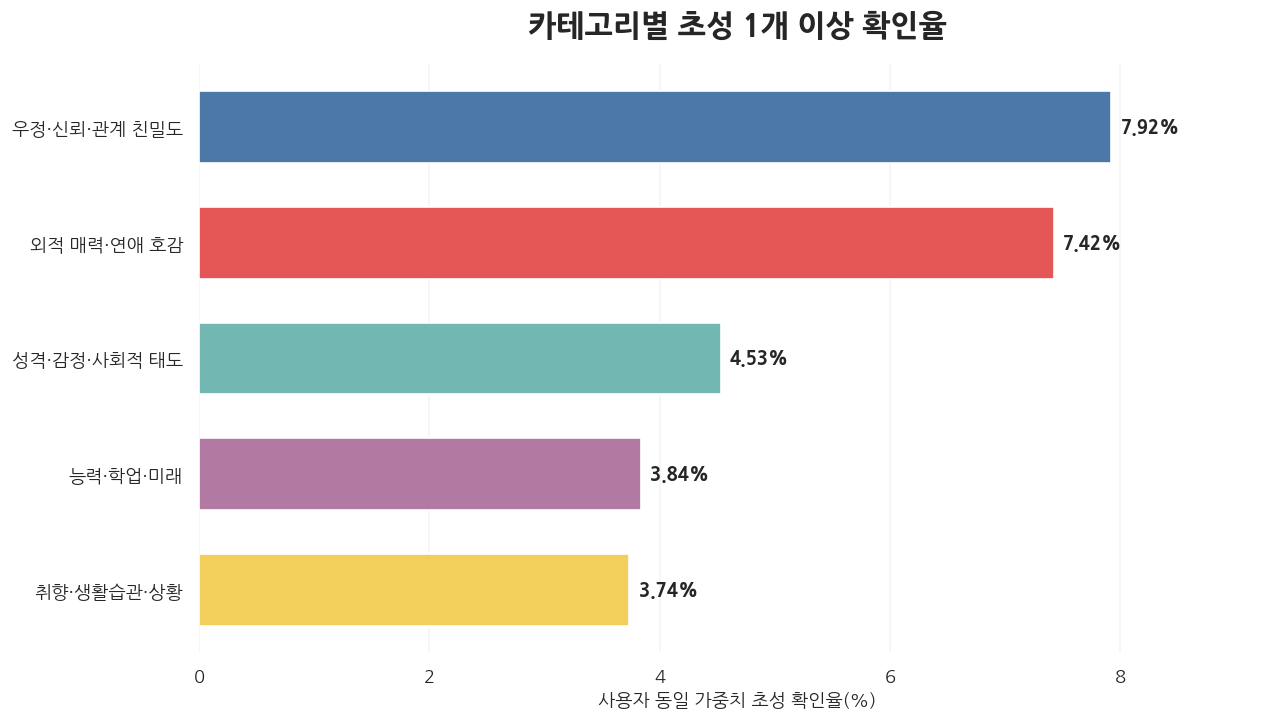

In [400]:
# ============================================================
# 카테고리별 사용자 동일 가중치 초성 확인율
# ============================================================

# 사용자-카테고리 단위로 수신 및 초성 확인 기록 집계
ppt_user_category_rate = (
    ppt_base
    .groupby(
        [
            "category",
            "chosen_user_id",
        ],
        observed=True,
    )
    .agg(
        수신_기록_수=(
            "초성 1개 이상 확인",
            "size",
        ),
        초성_확인_기록_수=(
            "초성 1개 이상 확인",
            "sum",
        ),
    )
    .reset_index()
)

# 각 사용자의 카테고리별 초성 확인율
ppt_user_category_rate[
    "사용자별 초성 확인율(%)"
] = (
    ppt_user_category_rate[
        "초성_확인_기록_수"
    ]
    / ppt_user_category_rate[
        "수신_기록_수"
    ]
    * 100
)

# 사용자별 비율을 단순 평균
# 수신 기록이 많은 사용자와 적은 사용자에게 동일 가중치 부여
ppt_user_equal_open_rate = (
    ppt_user_category_rate
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        사용자_동일_가중치_초성_확인율=(
            "사용자별 초성 확인율(%)",
            "mean",
        ),
        고유_수신자_수=(
            "chosen_user_id",
            "nunique",
        ),
    )
    .reset_index()
    .sort_values(
        "사용자_동일_가중치_초성_확인율",
        ascending=True,
    )
)


# ------------------------------------------------------------
# 차트
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 7)
)

bar_colors = [
    ppt_category_colors[category]
    for category
    in ppt_user_equal_open_rate["category"]
]

bars = ax.barh(
    ppt_user_equal_open_rate["category"],
    ppt_user_equal_open_rate[
        "사용자_동일_가중치_초성_확인율"
    ],
    color=bar_colors,
    height=0.62,
)

for bar, value in zip(
    bars,
    ppt_user_equal_open_rate[
        "사용자_동일_가중치_초성_확인율"
    ],
):
    ax.text(
        value + 0.08,
        bar.get_y()
        + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title(
    "카테고리별 초성 1개 이상 확인율",
    fontsize=18,
    pad=18,
    fontweight="bold",
)

ax.set_xlabel(
    "사용자 동일 가중치 초성 확인율(%)",
    fontsize=11,
)
ax.set_ylabel("")

ax.set_xlim(
    0,
    ppt_user_equal_open_rate[
        "사용자_동일_가중치_초성_확인율"
    ].max() * 1.18,
)

ax.grid(
    axis="x",
    alpha=0.2,
)
ax.grid(
    axis="y",
    visible=False,
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True,
)

plt.subplots_adjust(
    left=0.27,
    right=0.96,
    top=0.84,
    bottom=0.14,
)

plt.show()

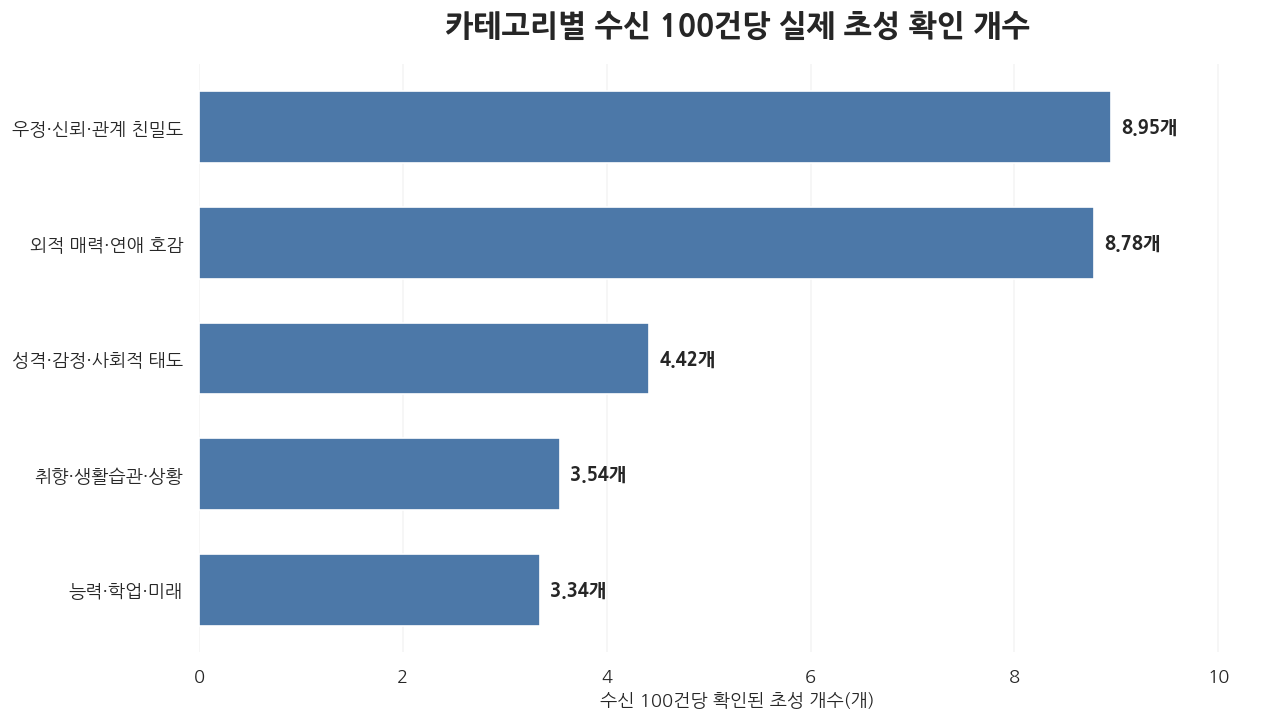

In [401]:
# ============================================================
# 수신 100건당 실제 초성 확인 개수
# ============================================================

ppt_efficiency_chart = (
    ppt_category_summary
    .sort_values(
        "수신 100건당 초성 확인 개수",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(13, 7)
)

bars = ax.barh(
    ppt_efficiency_chart["category"],
    ppt_efficiency_chart[
        "수신 100건당 초성 확인 개수"
    ],
    color="#4C78A8",
    height=0.62,
)

for bar, value in zip(
    bars,
    ppt_efficiency_chart[
        "수신 100건당 초성 확인 개수"
    ],
):
    ax.text(
        value + 0.10,
        bar.get_y()
        + bar.get_height() / 2,
        f"{value:.2f}개",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title(
    "카테고리별 수신 100건당 실제 초성 확인 개수",
    fontsize=18,
    pad=18,
    fontweight="bold",
)

ax.set_xlabel(
    "수신 100건당 확인된 초성 개수(개)",
    fontsize=11,
)
ax.set_ylabel("")

ax.set_xlim(
    0,
    ppt_efficiency_chart[
        "수신 100건당 초성 확인 개수"
    ].max() * 1.18,
)

ax.grid(
    axis="x",
    alpha=0.2,
)
ax.grid(
    axis="y",
    visible=False,
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True,
)

plt.subplots_adjust(
    left=0.27,
    right=0.96,
    top=0.84,
    bottom=0.14,
)

plt.show()

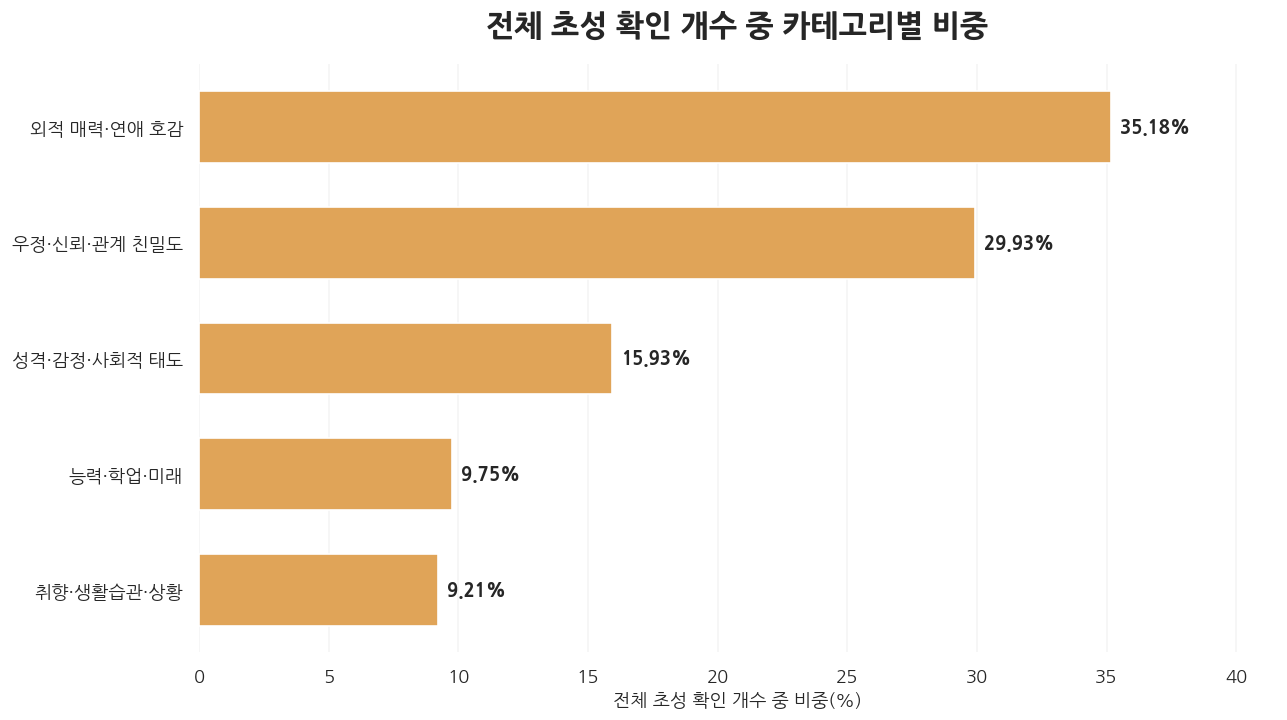

In [402]:
# ============================================================
# 전체 초성 확인 개수 중 카테고리별 비중
# ============================================================

ppt_contribution_chart = (
    ppt_category_summary
    .sort_values(
        "전체 초성 확인 중 비중(%)",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(13, 7)
)

bars = ax.barh(
    ppt_contribution_chart["category"],
    ppt_contribution_chart[
        "전체 초성 확인 중 비중(%)"
    ],
    color="#E0A458",
    height=0.62,
)

for bar, value in zip(
    bars,
    ppt_contribution_chart[
        "전체 초성 확인 중 비중(%)"
    ],
):
    ax.text(
        value + 0.35,
        bar.get_y()
        + bar.get_height() / 2,
        f"{value:.2f}%",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title(
    "전체 초성 확인 개수 중 카테고리별 비중",
    fontsize=18,
    pad=18,
    fontweight="bold",
)

ax.set_xlabel(
    "전체 초성 확인 개수 중 비중(%)",
    fontsize=11,
)
ax.set_ylabel("")

ax.set_xlim(
    0,
    ppt_contribution_chart[
        "전체 초성 확인 중 비중(%)"
    ].max() * 1.18,
)

ax.grid(
    axis="x",
    alpha=0.2,
)
ax.grid(
    axis="y",
    visible=False,
)

sns.despine(
    ax=ax,
    left=True,
    bottom=True,
)

plt.subplots_adjust(
    left=0.27,
    right=0.96,
    top=0.84,
    bottom=0.14,
)

plt.show()

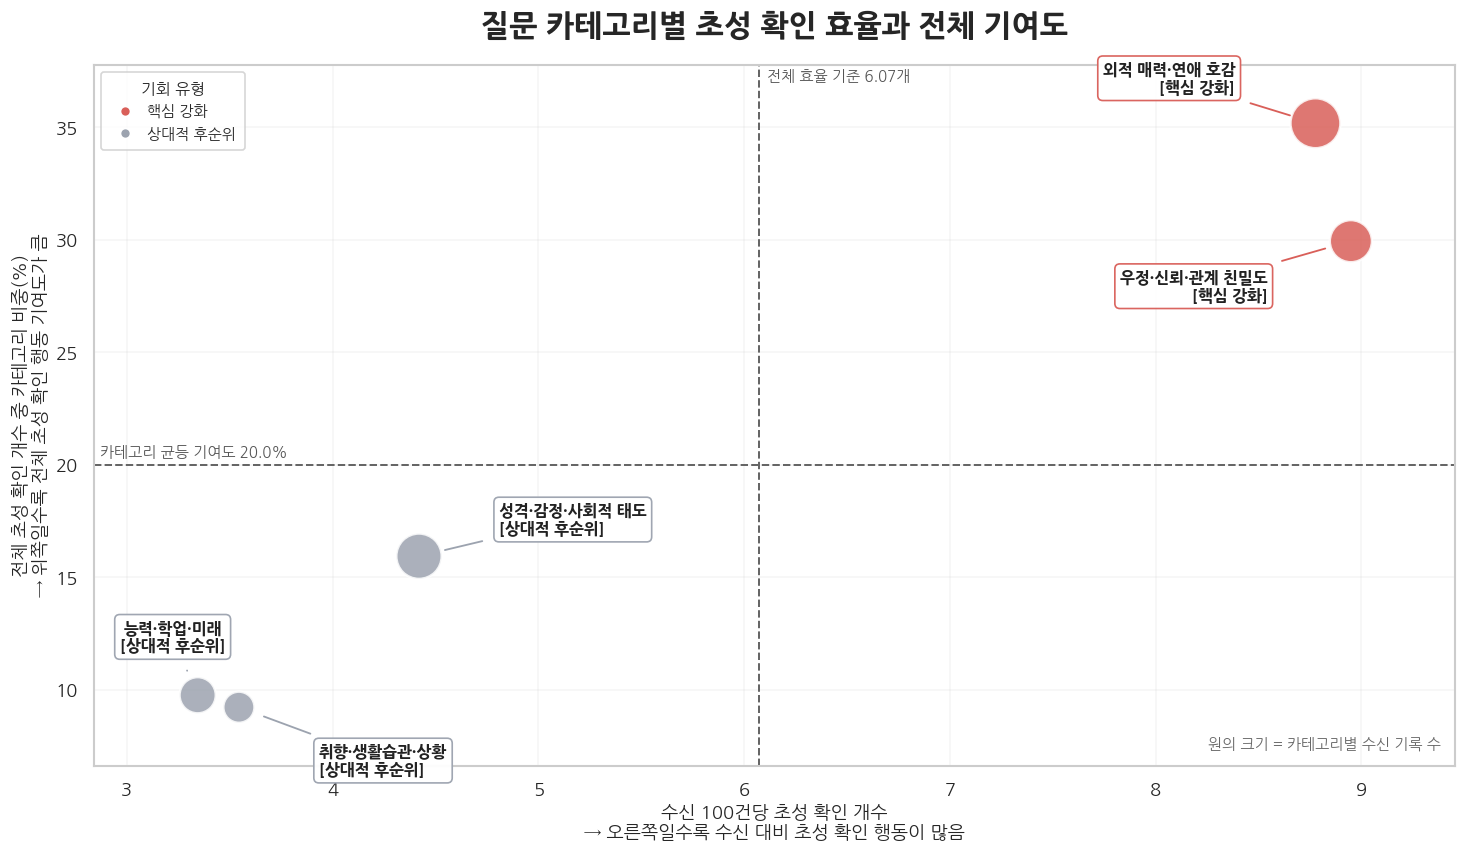

In [403]:
# ============================================================
# 카테고리별 초성 확인 효율 × 전체 기여도 매트릭스
# ============================================================

# ------------------------------------------------------------
# 1. 카테고리별 수신 기록과 초성 확인 개수 집계
# ------------------------------------------------------------

ppt_matrix = (
    ppt_base
    .groupby(
        "category",
        observed=True,
    )
    .agg(
        수신_기록_수=(
            "초성 확인 개수",
            "size",
        ),
        총_초성_확인_개수=(
            "초성 확인 개수",
            "sum",
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 2. 수신 100건당 초성 확인 개수
#
# 카테고리별 수신량 차이를 보정한 효율 지표
# ------------------------------------------------------------

ppt_matrix[
    "수신 100건당 초성 확인 개수"
] = (
    ppt_matrix["총_초성_확인_개수"]
    / ppt_matrix["수신_기록_수"]
    * 100
)


# ------------------------------------------------------------
# 3. 전체 초성 확인 중 카테고리별 비중
#
# 전체 초성 확인 행동에서 해당 카테고리가 차지한 비중
# ------------------------------------------------------------

ppt_matrix[
    "전체 초성 확인 중 비중(%)"
] = (
    ppt_matrix["총_초성_확인_개수"]
    / ppt_matrix[
        "총_초성_확인_개수"
    ].sum()
    * 100
)


# ------------------------------------------------------------
# 4. 매트릭스 기준값 계산
# ------------------------------------------------------------

# 전체 카테고리를 합친 수신 100건당 초성 확인 개수
ppt_overall_efficiency = (
    ppt_matrix[
        "총_초성_확인_개수"
    ].sum()
    / ppt_matrix[
        "수신_기록_수"
    ].sum()
    * 100
)

# 카테고리가 동일하게 기여한다고 가정한 기준
ppt_equal_contribution = (
    100
    / ppt_matrix["category"].nunique()
)


# ------------------------------------------------------------
# 5. 기회 유형 분류
# ------------------------------------------------------------

ppt_high_efficiency = (
    ppt_matrix[
        "수신 100건당 초성 확인 개수"
    ]
    >= ppt_overall_efficiency
)

ppt_high_contribution = (
    ppt_matrix[
        "전체 초성 확인 중 비중(%)"
    ]
    >= ppt_equal_contribution
)

ppt_matrix["기회 유형"] = np.select(
    [
        (
            ppt_high_efficiency
            & ppt_high_contribution
        ),
        (
            ppt_high_efficiency
            & ~ppt_high_contribution
        ),
        (
            ~ppt_high_efficiency
            & ppt_high_contribution
        ),
    ],
    [
        "핵심 강화",
        "노출 확대 검토",
        "효율 개선",
    ],
    default="상대적 후순위",
)


# ------------------------------------------------------------
# 6. 원 크기 계산
#
# 수신 기록 수가 많을수록 원이 커짐
# 확대된 차트에서 너무 커 보이지 않도록 최대 크기 축소
# ------------------------------------------------------------

ppt_min_bubble = 350
ppt_max_bubble = 900

ppt_min_receipts = (
    ppt_matrix["수신_기록_수"].min()
)

ppt_max_receipts = (
    ppt_matrix["수신_기록_수"].max()
)

if ppt_max_receipts == ppt_min_receipts:

    ppt_matrix["버블 크기"] = (
        ppt_min_bubble
        + ppt_max_bubble
    ) / 2

else:

    ppt_matrix["버블 크기"] = (
        (
            ppt_matrix["수신_기록_수"]
            - ppt_min_receipts
        )
        / (
            ppt_max_receipts
            - ppt_min_receipts
        )
        * (
            ppt_max_bubble
            - ppt_min_bubble
        )
        + ppt_min_bubble
    )


# ------------------------------------------------------------
# 7. 기회 유형별 색상
# ------------------------------------------------------------

ppt_opportunity_colors = {
    "핵심 강화": "#D95F59",
    "노출 확대 검토": "#59A14F",
    "효율 개선": "#F2A541",
    "상대적 후순위": "#9CA3AF",
}


# ------------------------------------------------------------
# 8. 카테고리별 라벨 위치
#
# 이전보다 원과 라벨 사이 거리를 줄임
# 가까운 두 카테고리는 서로 반대 방향으로 배치
# ------------------------------------------------------------

ppt_label_positions = {
    "외적 매력·연애 호감": {
        "offset": (-48, 27),
        "ha": "right",
    },
    "우정·신뢰·관계 친밀도": {
        "offset": (-50, -27),
        "ha": "right",
    },
    "성격·감정·사회적 태도": {
        "offset": (48, 22),
        "ha": "left",
    },
    "능력·학업·미래": {
        "offset": (-15, 35),
        "ha": "center",
    },
    "취향·생활습관·상황": {
        "offset": (48, -32),
        "ha": "left",
    },
}


# ------------------------------------------------------------
# 9. 차트 생성
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13.5, 8)
)

for opportunity_type, group in (
    ppt_matrix
    .groupby(
        "기회 유형",
        observed=True,
    )
):

    ax.scatter(
        group[
            "수신 100건당 초성 확인 개수"
        ],
        group[
            "전체 초성 확인 중 비중(%)"
        ],
        s=group["버블 크기"],
        color=ppt_opportunity_colors[
            opportunity_type
        ],
        alpha=0.85,
        edgecolors="white",
        linewidths=1.5,
        zorder=3,
    )


# ------------------------------------------------------------
# 10. 전체 평균 기준선
# ------------------------------------------------------------

ax.axvline(
    ppt_overall_efficiency,
    color="#666666",
    linestyle="--",
    linewidth=1.2,
    zorder=1,
)

ax.axhline(
    ppt_equal_contribution,
    color="#666666",
    linestyle="--",
    linewidth=1.2,
    zorder=1,
)


# ------------------------------------------------------------
# 11. 카테고리 라벨
#
# 라벨은 원 밖에 배치하고 선으로 연결
# ------------------------------------------------------------

for _, row in ppt_matrix.iterrows():

    category = row["category"]
    opportunity_type = row["기회 유형"]

    label_setting = (
        ppt_label_positions.get(
            category,
            {
                "offset": (45, 25),
                "ha": "left",
            },
        )
    )

    offset_x, offset_y = (
        label_setting["offset"]
    )

    label_color = (
        ppt_opportunity_colors[
            opportunity_type
        ]
    )

    ax.annotate(
        (
            f"{category}\n"
            f"[{opportunity_type}]"
        ),

        # 원의 위치
        xy=(
            row[
                "수신 100건당 초성 확인 개수"
            ],
            row[
                "전체 초성 확인 중 비중(%)"
            ],
        ),

        # 원에서 글자를 이동할 거리
        xytext=(
            offset_x,
            offset_y,
        ),

        textcoords="offset points",

        ha=label_setting["ha"],
        va="center",

        fontsize=9.5,
        fontweight="bold",
        color="#222222",

        # 라벨 배경
        bbox={
            "boxstyle": "round,pad=0.32",
            "facecolor": "white",
            "edgecolor": label_color,
            "linewidth": 1,
            "alpha": 0.96,
        },

        # 원과 라벨을 연결하는 선
        arrowprops={
            "arrowstyle": "-",
            "color": label_color,
            "linewidth": 1.1,
            "shrinkA": 7,
            "shrinkB": 16,
            "connectionstyle": "arc3,rad=0",
        },

        annotation_clip=False,
        zorder=5,
    )


# ------------------------------------------------------------
# 12. 작은 원을 사용한 범례
# ------------------------------------------------------------

ppt_type_order = [
    "핵심 강화",
    "노출 확대 검토",
    "효율 개선",
    "상대적 후순위",
]

ppt_present_types = set(
    ppt_matrix["기회 유형"]
)

ppt_legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=(
            ppt_opportunity_colors[
                opportunity_type
            ]
        ),
        markeredgecolor="white",
        markersize=6,
        label=opportunity_type,
    )
    for opportunity_type
    in ppt_type_order
    if opportunity_type in ppt_present_types
]

ax.legend(
    handles=ppt_legend_handles,
    title="기회 유형",
    loc="upper left",
    frameon=True,
    fontsize=9,
    title_fontsize=9.5,
    borderpad=0.6,
    labelspacing=0.5,
    handletextpad=0.45,
)


# ------------------------------------------------------------
# 13. 축 범위를 데이터 주변에 가깝게 설정
#
# 이전 코드보다 여백을 크게 줄여 확대된 느낌으로 표시
# ------------------------------------------------------------

ppt_x_min = (
    ppt_matrix[
        "수신 100건당 초성 확인 개수"
    ].min()
)

ppt_x_max = (
    ppt_matrix[
        "수신 100건당 초성 확인 개수"
    ].max()
)

ppt_y_min = (
    ppt_matrix[
        "전체 초성 확인 중 비중(%)"
    ].min()
)

ppt_y_max = (
    ppt_matrix[
        "전체 초성 확인 중 비중(%)"
    ].max()
)

ppt_x_range = (
    ppt_x_max
    - ppt_x_min
)

ppt_y_range = (
    ppt_y_max
    - ppt_y_min
)

# X축은 데이터 범위의 약 9%만 여백으로 사용
ppt_x_padding = max(
    ppt_x_range * 0.09,
    0.45,
)

# Y축은 데이터 범위의 약 10%만 여백으로 사용
ppt_y_padding = max(
    ppt_y_range * 0.10,
    2.3,
)

ax.set_xlim(
    max(
        0,
        ppt_x_min - ppt_x_padding,
    ),
    ppt_x_max + ppt_x_padding,
)

ax.set_ylim(
    max(
        0,
        ppt_y_min - ppt_y_padding,
    ),
    ppt_y_max + ppt_y_padding,
)


# ------------------------------------------------------------
# 14. 기준선 설명
# ------------------------------------------------------------

ax.text(
    ppt_overall_efficiency + 0.04,
    ax.get_ylim()[1] - 0.2,
    (
        f"전체 효율 기준 "
        f"{ppt_overall_efficiency:.2f}개"
    ),
    ha="left",
    va="top",
    fontsize=9,
    color="#555555",
)

ax.text(
    ax.get_xlim()[0] + 0.03,
    ppt_equal_contribution + 0.22,
    (
        f"카테고리 균등 기여도 "
        f"{ppt_equal_contribution:.1f}%"
    ),
    ha="left",
    va="bottom",
    fontsize=9,
    color="#555555",
)


# ------------------------------------------------------------
# 15. 원 크기의 의미 표시
# ------------------------------------------------------------

ax.text(
    0.99,
    0.02,
    "원의 크기 = 카테고리별 수신 기록 수",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    color="#666666",
)


# ------------------------------------------------------------
# 16. 제목과 축 설명
# ------------------------------------------------------------

ax.set_title(
    "질문 카테고리별 초성 확인 효율과 전체 기여도",
    fontsize=18,
    pad=18,
    fontweight="bold",
)

ax.set_xlabel(
    (
        "수신 100건당 초성 확인 개수\n"
        "→ 오른쪽일수록 수신 대비 초성 확인 행동이 많음"
    ),
    fontsize=11,
)

ax.set_ylabel(
    (
        "전체 초성 확인 개수 중 카테고리 비중(%)\n"
        "→ 위쪽일수록 전체 초성 확인 행동 기여도가 큼"
    ),
    fontsize=11,
)


# ------------------------------------------------------------
# 17. 차트 마무리
# ------------------------------------------------------------

ax.grid(
    alpha=0.18,
    zorder=0,
)

plt.subplots_adjust(
    left=0.12,
    right=0.96,
    top=0.90,
    bottom=0.17,
)

plt.show()

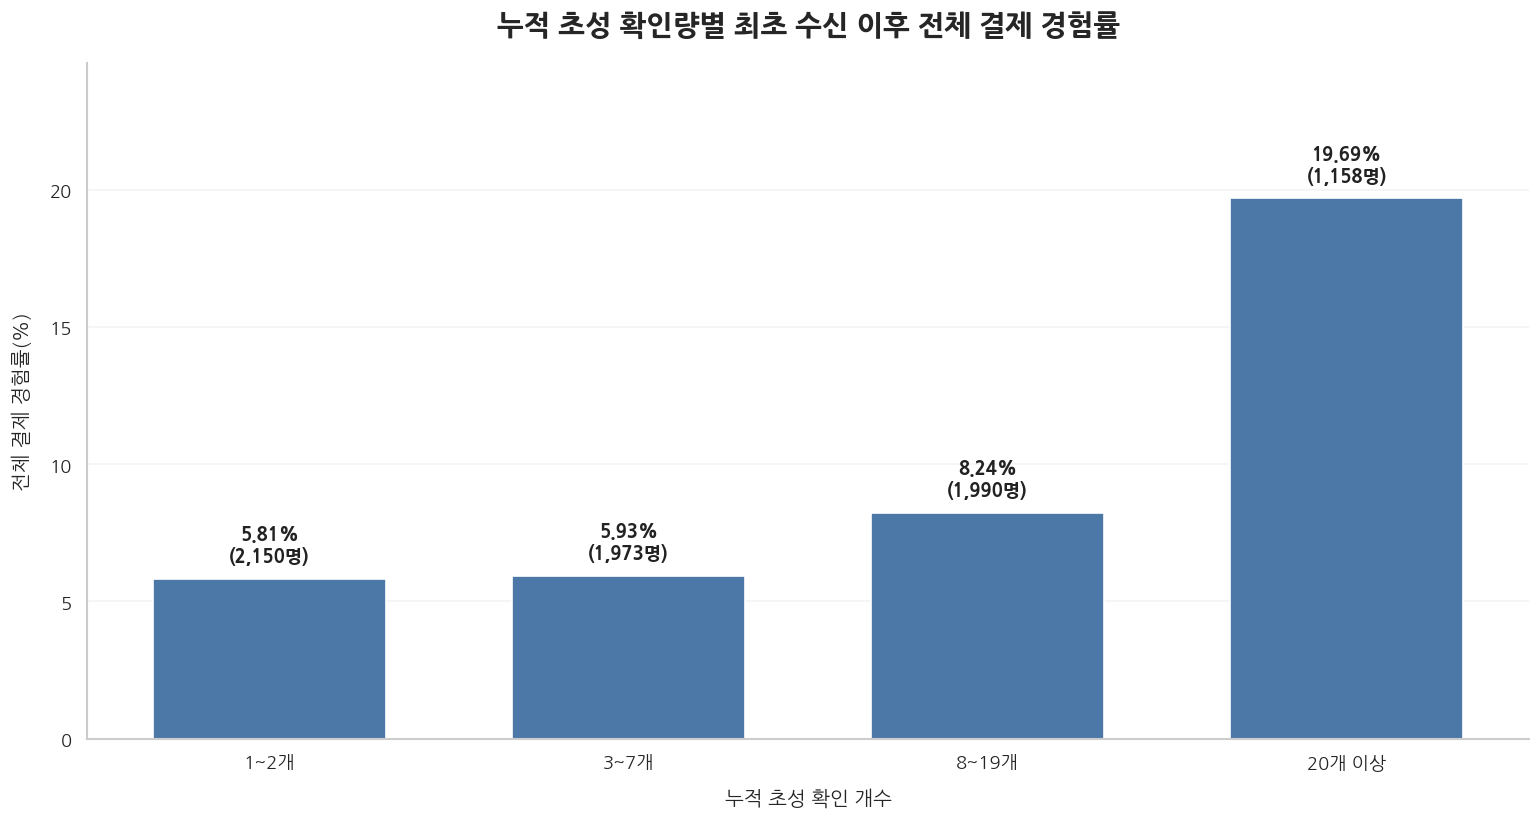

,사용자 수(명),결제 경험자 수(명),전체 결제 경험률(%)
초성 확인 구간,,,
1~2개,2150,125,5.81
3~7개,1973,117,5.93
8~19개,1990,164,8.24
20개 이상,1158,228,19.69


In [404]:
# ============================================================
# 누적 초성 확인량별 최초 수신 이후 전체 결제 경험률
# ============================================================

# ------------------------------------------------------------
# 1. 사용자별 초성 확인량과 결제 경험 데이터 가져오기
# ------------------------------------------------------------

payment_chart_base = (
    user_receipt_payment[
        [
            "user_id",
            "total_opened_initials",
            "has_any_payment",
        ]
    ]
    .copy()
)

# 사용자별로 한 행인지 확인
assert not payment_chart_base["user_id"].duplicated().any(), (
    "사용자 ID가 중복되어 있습니다. 사용자별 집계 테이블을 확인하세요."
)

# 누적 초성 확인 개수를 숫자형으로 변환
payment_chart_base["total_opened_initials"] = (
    pd.to_numeric(
        payment_chart_base["total_opened_initials"],
        errors="coerce",
    )
)

# 초성을 1개 이상 확인한 사용자만 사용
payment_chart_base = (
    payment_chart_base.loc[
        payment_chart_base["total_opened_initials"].gt(0)
    ]
    .copy()
)

# 기존 테이블의 결제 경험 여부 사용
# has_any_payment: 최초 수신 이후 전체 상품 결제 경험 여부
payment_chart_base["has_any_payment"] = (
    payment_chart_base["has_any_payment"]
    .fillna(False)
    .astype(bool)
)


# ------------------------------------------------------------
# 2. 이전 차트에서 사용한 구간 적용
# ------------------------------------------------------------

# 기존 데이터에서 사용자 수를 고려해 선택한 경계
# 현재 데이터를 다시 약 2,000명씩 나누는 것은 아님
open_group_order = [
    "1~2개",
    "3~7개",
    "8~19개",
    "20개 이상",
]

payment_chart_base["초성 확인 구간"] = pd.cut(
    payment_chart_base["total_opened_initials"],
    bins=[0, 2, 7, 19, np.inf],
    labels=open_group_order,
    right=True,
)


# ------------------------------------------------------------
# 3. 구간별 사용자 수와 결제 경험자 수 계산
# ------------------------------------------------------------

similar_2000_without_zero = (
    payment_chart_base
    .groupby(
        "초성 확인 구간",
        observed=True,
    )
    .agg(
        사용자_수=("user_id", "nunique"),
        결제_경험자_수=("has_any_payment", "sum"),
    )
    .reindex(open_group_order)
)

# 구간 내 전체 사용자 대비 결제 경험자 비율
similar_2000_without_zero["전체 결제 경험률(%)"] = (
    similar_2000_without_zero["결제_경험자_수"]
    / similar_2000_without_zero["사용자_수"]
    * 100
)

# 사용자가 없는 구간은 차트에서 제외
chart_data = (
    similar_2000_without_zero
    .dropna(subset=["전체 결제 경험률(%)"])
    .copy()
)

if chart_data.empty:
    raise ValueError("초성을 1개 이상 확인한 사용자가 없습니다.")


# ------------------------------------------------------------
# 4. 막대그래프 생성
# ------------------------------------------------------------

maximum_payment_rate = (
    chart_data["전체 결제 경험률(%)"].max()
)

fig, ax = plt.subplots(
    figsize=(13, 7),
)

x_positions = np.arange(len(chart_data))

payment_rates = (
    chart_data["전체 결제 경험률(%)"]
    .to_numpy(dtype=float)
)

user_counts = (
    chart_data["사용자_수"]
    .to_numpy(dtype=int)
)

bars = ax.bar(
    x=x_positions,
    height=payment_rates,
    color="#4C78A8",
    width=0.65,
)

# 막대 위에 결제 경험률과 구간 전체 사용자 수 표시
label_padding = max(maximum_payment_rate * 0.025, 0.2)

for bar, payment_rate, user_count in zip(
    bars,
    payment_rates,
    user_counts,
):
    ax.text(
        x=bar.get_x() + bar.get_width() / 2,
        y=bar.get_height() + label_padding,
        s=(
            f"{payment_rate:.2f}%\n"
            f"({user_count:,}명)"
        ),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#222222",
    )


# ------------------------------------------------------------
# 5. 제목과 축 디자인
# ------------------------------------------------------------

ax.set_title(
    "누적 초성 확인량별 최초 수신 이후 전체 결제 경험률",
    fontsize=17,
    fontweight="bold",
    pad=18,
)

ax.set_xticks(x_positions)
ax.set_xticklabels(
    chart_data.index.astype(str),
    fontsize=11,
)

ax.set_xlabel(
    "누적 초성 확인 개수",
    fontsize=12,
    labelpad=10,
)

ax.set_ylabel(
    "전체 결제 경험률(%)",
    fontsize=12,
    labelpad=10,
)

ax.set_ylim(
    0,
    max(maximum_payment_rate * 1.25, 1),
)

ax.grid(
    axis="y",
    alpha=0.22,
)

ax.grid(
    axis="x",
    visible=False,
)

ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. 계산 결과를 한글 컬럼명으로 확인
# ------------------------------------------------------------

display(
    chart_data.rename(
        columns={
            "사용자_수": "사용자 수(명)",
            "결제_경험자_수": "결제 경험자 수(명)",
        }
    ).round(2)
)

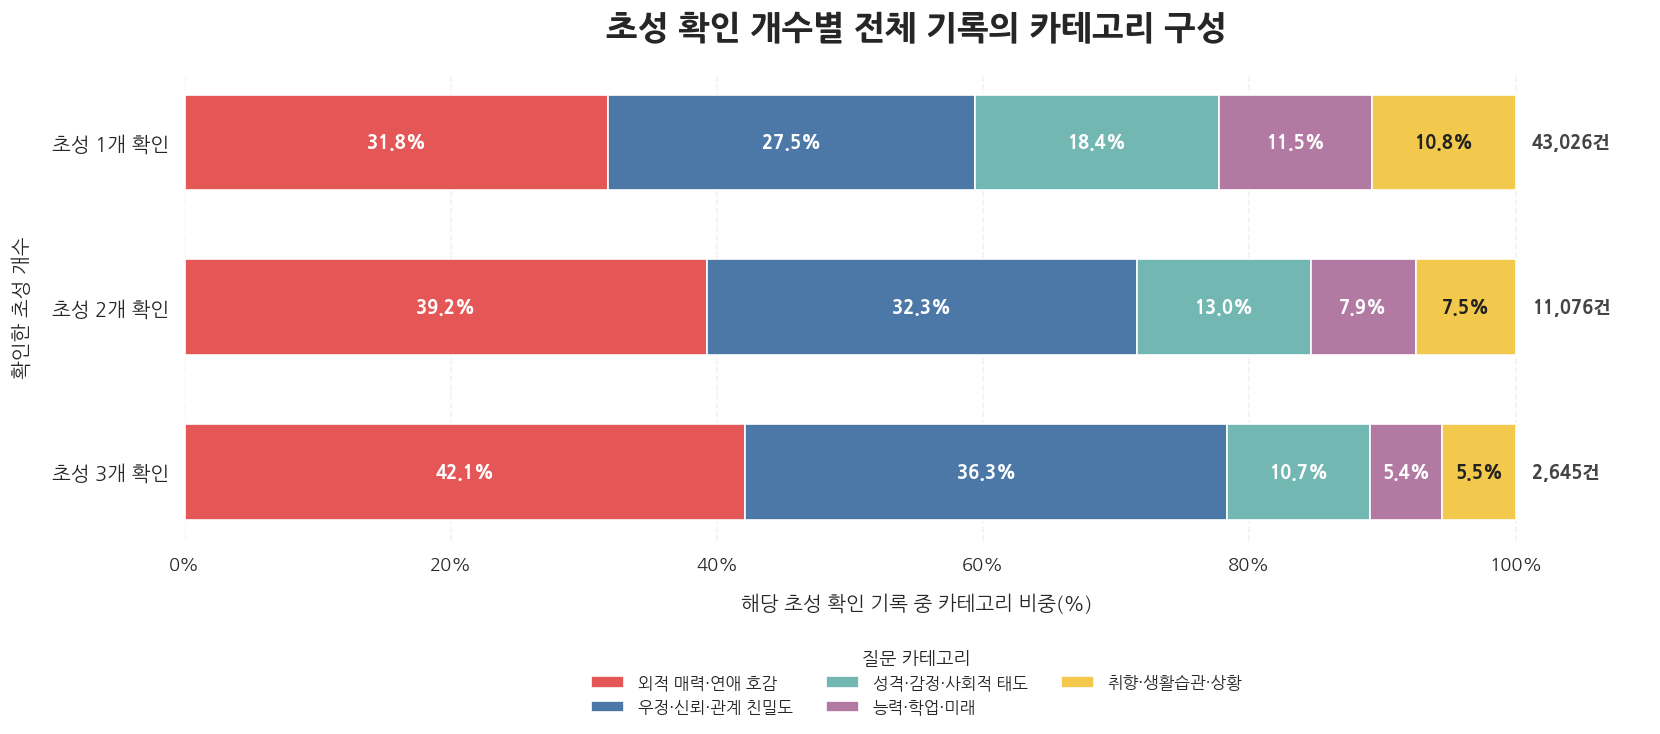

,확인한 초성 개수,질문 카테고리,기록 수(건),해당 초성 개수 내 비중(%)
0,초성 1개 확인,능력·학업·미래,4940,11.48
1,초성 1개 확인,성격·감정·사회적 태도,7910,18.38
2,초성 1개 확인,외적 매력·연애 호감,13693,31.82
3,초성 1개 확인,우정·신뢰·관계 친밀도,11845,27.53
4,초성 1개 확인,취향·생활습관·상황,4638,10.78
5,초성 2개 확인,능력·학업·미래,877,7.92
6,초성 2개 확인,성격·감정·사회적 태도,1443,13.03
7,초성 2개 확인,외적 매력·연애 호감,4344,39.22
8,초성 2개 확인,우정·신뢰·관계 친밀도,3582,32.34
9,초성 2개 확인,취향·생활습관·상황,830,7.49


In [405]:
# ============================================================
# 초성 확인 개수별 전체 기록의 카테고리 구성
# ============================================================

# ------------------------------------------------------------
# 1. 분석에 필요한 컬럼만 가져오기
# ------------------------------------------------------------

open_count_category_base = (
    category_behavior_base[
        [
            "category",
            "opened_times",
        ]
    ]
    .copy()
)

# 초성 확인 개수를 숫자형으로 변환
open_count_category_base["opened_times"] = (
    pd.to_numeric(
        open_count_category_base["opened_times"],
        errors="coerce",
    )
)

# 초성을 정확히 1개·2개·3개 확인한 기록만 사용
open_count_category_base = (
    open_count_category_base.loc[
        open_count_category_base[
            "opened_times"
        ].between(1, 3)
    ]
    .copy()
)

open_count_category_base["opened_times"] = (
    open_count_category_base["opened_times"]
    .astype("int64")
)


# ------------------------------------------------------------
# 2. 초성 확인 개수·카테고리별 기록 수 계산
# ------------------------------------------------------------

open_count_category_summary = (
    open_count_category_base
    .groupby(
        [
            "opened_times",
            "category",
        ],
        observed=True,
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size": "record_count",
        }
    )
)


# ------------------------------------------------------------
# 3. 초성 확인 개수별 전체 기록 수 계산
# ------------------------------------------------------------

open_count_category_summary[
    "open_count_total_records"
] = (
    open_count_category_summary
    .groupby("opened_times")["record_count"]
    .transform("sum")
)


# ------------------------------------------------------------
# 4. 초성 확인 개수별 카테고리 비중 계산
# ------------------------------------------------------------

open_count_category_summary[
    "category_share_pct"
] = (
    open_count_category_summary["record_count"]
    / open_count_category_summary[
        "open_count_total_records"
    ]
    * 100
)


# ------------------------------------------------------------
# 5. 차트 표시 순서와 색상 지정
# ------------------------------------------------------------

open_count_order = [
    1,
    2,
    3,
]

open_count_labels = {
    1: "초성 1개 확인",
    2: "초성 2개 확인",
    3: "초성 3개 확인",
}

category_order = [
    "외적 매력·연애 호감",
    "우정·신뢰·관계 친밀도",
    "성격·감정·사회적 태도",
    "능력·학업·미래",
    "취향·생활습관·상황",
]

category_colors = {
    "외적 매력·연애 호감": "#E45756",
    "우정·신뢰·관계 친밀도": "#4C78A8",
    "성격·감정·사회적 태도": "#72B7B2",
    "능력·학업·미래": "#B279A2",
    "취향·생활습관·상황": "#F2C94C",
}


# ------------------------------------------------------------
# 6. 비율 데이터를 피벗 형태로 변환
# ------------------------------------------------------------

category_share_pivot = (
    open_count_category_summary
    .pivot(
        index="opened_times",
        columns="category",
        values="category_share_pct",
    )
    .reindex(
        index=open_count_order,
        columns=category_order,
    )
    .fillna(0)
)

# 초성 확인 개수별 전체 기록 수
open_count_totals = (
    open_count_category_summary
    .groupby("opened_times")["record_count"]
    .sum()
    .reindex(open_count_order)
)


# ------------------------------------------------------------
# 7. 100% 누적 가로 막대그래프 생성
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    font="NanumGothic",
)

plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(
    figsize=(14, 6.5),
)

y_positions = np.arange(
    len(open_count_order)
)

# 각 막대가 시작되는 위치
left_positions = np.zeros(
    len(open_count_order)
)

for category in category_order:

    category_values = (
        category_share_pivot[category]
        .to_numpy()
    )

    bars = ax.barh(
        y=y_positions,
        width=category_values,
        left=left_positions,
        height=0.58,
        color=category_colors[category],
        label=category,
    )

    # 각 영역 안에 카테고리 비율 표시
    for bar, share in zip(
        bars,
        category_values,
    ):

        # 너무 좁은 영역에는 글자를 표시하지 않음
        if share < 4:
            continue

        text_x = (
            bar.get_x()
            + bar.get_width() / 2
        )

        text_y = (
            bar.get_y()
            + bar.get_height() / 2
        )

        # 노란색 영역은 검은 글자, 나머지는 흰 글자
        text_color = (
            "#222222"
            if category == "취향·생활습관·상황"
            else "white"
        )

        ax.text(
            text_x,
            text_y,
            f"{share:.1f}%",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=text_color,
        )

    left_positions += category_values


# ------------------------------------------------------------
# 8. 막대 오른쪽에 전체 기록 수 표시
# ------------------------------------------------------------

for y_position, opened_count in zip(
    y_positions,
    open_count_order,
):

    total_records = (
        open_count_totals.loc[opened_count]
    )

    ax.text(
        101.2,
        y_position,
        f"{total_records:,.0f}건",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#444444",
    )


# ------------------------------------------------------------
# 9. 제목·축·범례 디자인
# ------------------------------------------------------------

ax.set_title(
    "초성 확인 개수별 전체 기록의 카테고리 구성",
    fontsize=20,
    fontweight="bold",
    pad=22,
)

ax.set_xlabel(
    "해당 초성 확인 기록 중 카테고리 비중(%)",
    fontsize=12,
    labelpad=12,
)

ax.set_ylabel(
    "확인한 초성 개수",
    fontsize=12,
    labelpad=12,
)

ax.set_yticks(y_positions)

ax.set_yticklabels(
    [
        open_count_labels[count]
        for count in open_count_order
    ],
    fontsize=12,
)

# 초성 1개부터 위에서 아래로 표시
ax.invert_yaxis()

ax.set_xlim(
    0,
    110,
)

ax.set_xticks(
    [
        0,
        20,
        40,
        60,
        80,
        100,
    ]
)

ax.set_xticklabels(
    [
        "0%",
        "20%",
        "40%",
        "60%",
        "80%",
        "100%",
    ]
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25,
)

ax.grid(
    axis="y",
    visible=False,
)

sns.despine(
    ax=ax,
    top=True,
    right=True,
    left=True,
    bottom=True,
)

ax.legend(
    title="질문 카테고리",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    frameon=False,
    fontsize=10,
    title_fontsize=11,
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. 계산 결과 표 확인
# ------------------------------------------------------------

open_count_category_display = (
    open_count_category_summary[
        [
            "opened_times",
            "category",
            "record_count",
            "category_share_pct",
        ]
    ]
    .rename(
        columns={
            "opened_times": "확인한 초성 개수",
            "category": "질문 카테고리",
            "record_count": "기록 수(건)",
            "category_share_pct": "해당 초성 개수 내 비중(%)",
        }
    )
)

open_count_category_display[
    "확인한 초성 개수"
] = (
    open_count_category_display[
        "확인한 초성 개수"
    ]
    .map(open_count_labels)
)

open_count_category_display[
    "해당 초성 개수 내 비중(%)"
] = (
    open_count_category_display[
        "해당 초성 개수 내 비중(%)"
    ]
    .round(2)
)

display(open_count_category_display)

In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Sooyong"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"

!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "우리팀 최고! 수고 많으셨습니다!!"
!git push

/content/team3-ping-analytics
Already up to date.
